# Beyond the Scoreboard - analysis notebook
**SupeRR Selector Season 2 - Round 1.** Identifying the most reliable performers under pressure in T20 cricket.

This notebook contains the entire pipeline, from the six supplied CSV files to the final rankings. Each module is written to `src/` by a `%%writefile` cell and then executed, so the notebook is self-contained. Put the six CSVs in `./data/` next to this notebook and run all cells (about 15 minutes on two cores). Random seed: 20260516.

| Step | What it does |
|---|---|
| 1 | Clean deliveries, reconstruct match state |
| 2 | Win probability, leverage, Dynamic Pressure Index |
| 3 | Expected performance, runs above expectation |
| 4 | Test definitions of pressure |
| 5 | Player ratings with shrinkage and bootstrap |
| 6 | Predictive validation |
| 7 | Robustness |
| 8 | Final rankings |
| 9-11 | Insights, figures, exports |

In [1]:
import os, sys, warnings
warnings.filterwarnings('ignore')
os.makedirs('src', exist_ok=True)
assert os.path.exists('data/ball_by_ball.csv'), 'Place the six supplied CSV files in ./data'
sys.path.insert(0, os.path.abspath('src'))
print(sorted(os.listdir('data')))

['ball_by_ball.csv', 'competition_team_player_mapping.csv', 'competitions.csv', 'matches.csv', 'playing_eleven.csv', 'teams.csv']


## Setup - shared paths and constants

In [2]:
%%writefile src/common.py
"""Shared paths, constants and small helpers for the SupeRR Selector pipeline."""
from pathlib import Path
import json
import numpy as np
import pandas as pd

ROOT = Path(__file__).resolve().parents[1]
RAW = ROOT / "data"
PROC = ROOT / "processed"
OUT = ROOT / "outputs"
FIG = ROOT / "figures"
for p in (PROC, OUT, FIG):
    p.mkdir(exist_ok=True)

SEED = 20260516
rng = np.random.default_rng(SEED)

# ICC Full Members (2022 onwards). Everything else in the international pool is an Associate.
FULL_MEMBERS = {
    "India", "Australia", "England", "Pakistan", "South Africa", "New Zealand",
    "Sri Lanka", "West Indies", "Bangladesh", "Afghanistan", "Ireland", "Zimbabwe",
}

# Extras that are not recorded run-by-run in ball_by_ball.csv. Each value is the
# expected number of runs per event, estimated by robust regression of result
# margins on extras counts (see 01_prepare.calibrate_extras). They are re-estimated
# on every run; these are only fall-backs.
DEFAULT_EXTRA_RUNS = {"wide": 1.14, "byes": 2.03, "legbyes": 1.25}

# Dismissals credited to the bowler.
BOWLER_WICKETS = {"Caught", "Bowled", "LBW", "Stump", "Hit Wicket"}


def save_json(obj, name):
    with open(OUT / name, "w") as f:
        json.dump(obj, f, indent=2, default=float)


def load_json(name):
    with open(OUT / name) as f:
        return json.load(f)


def phase_of(over):
    """T20 phase from 1-indexed over number."""
    return np.where(over <= 6, "Powerplay", np.where(over <= 15, "Middle", "Death"))


Writing src/common.py


## The Pressure-Adjusted Player Model (PAPM) - shared code
Sparse ridge (empirical-Bayes random effects) with player, player×pressure, opponent and opponent×pressure terms; two-component version; match bootstrap.

In [3]:
%%writefile src/ratings_core.py
"""Core of the player-rating model, reused by the main pipeline and the robustness suite.

Pressure-Adjusted Player Model (PAPM)
-------------------------------------
For every ball i, with RAE_i the wicket-adjusted runs above expectation from the batting
side's point of view (sign flipped for bowlers), and P_i = 1 on a pressure ball:

    RAE_i = mu + tau * P_i
            + a_j   + d_j * P_i          (the player being rated: normal level + pressure shift)
            + o_k   + e_k * P_i          (the opponent on that ball: bowler for batters, batter for bowlers)
            + noise

a_j, d_j, o_k, e_k are random effects with Normal(0, sigma^2) priors. Their posterior
mode is a ridge regression; the prior variances (penalties) are chosen by 5-fold
cross-validation over *matches*, i.e. by how well the model predicts deliveries in
matches it has not seen. This is empirical Bayes: the data decide how much a small
sample is trusted. The opponent terms mean a run against Jasprit Bumrah in the 19th over
counts for more than a run against a part-timer.

Pressure performance of player j = a_j + d_j (runs above expectation per pressure ball).
Normal performance = a_j. Pressure shift = d_j.
"""
import numpy as np
import pandas as pd
from scipy import sparse
from scipy.sparse.linalg import lsqr


def build(df, actor, opp, pflag):
    a = pd.Categorical(df[actor].values)
    o = pd.Categorical(df[opp].values)
    n = len(df)
    P = df[pflag].values.astype(float)
    i = np.arange(n)
    na, no = len(a.categories), len(o.categories)
    blocks = dict(
        A=sparse.csr_matrix((np.ones(n), (i, a.codes)), shape=(n, na)),
        D=sparse.csr_matrix((P, (i, a.codes)), shape=(n, na)),
        O=sparse.csr_matrix((np.ones(n), (i, o.codes)), shape=(n, no)),
        E=sparse.csr_matrix((P, (i, o.codes)), shape=(n, no)),
    )
    fixed = sparse.csr_matrix(np.c_[np.ones(n), P])
    return {"blocks": blocks, "fixed": fixed, "actors": np.asarray(a.categories), "opps": np.asarray(o.categories),
            "na": na, "no": no, "P": P, "acodes": a.codes, "ocodes": o.codes}


def fit(des, y, lam_base, lam_delta, lam_opp=None, lam_opp_delta=None, w=None):
    lam_opp = lam_base if lam_opp is None else lam_opp
    lam_opp_delta = lam_delta if lam_opp_delta is None else lam_opp_delta
    bl = des["blocks"]
    sc = [1 / np.sqrt(lam_base), 1 / np.sqrt(lam_delta), 1 / np.sqrt(lam_opp), 1 / np.sqrt(lam_opp_delta)]
    X = sparse.hstack([des["fixed"] * 100.0, bl["A"] * sc[0], bl["D"] * sc[1], bl["O"] * sc[2], bl["E"] * sc[3]]).tocsr()
    yy = np.asarray(y, float)
    if w is not None:
        sw = np.sqrt(w)
        X = sparse.diags(sw) @ X
        yy = yy * sw
    sol = lsqr(X, yy, damp=1.0, atol=1e-10, btol=1e-10, iter_lim=5000)[0]
    na, no = des["na"], des["no"]
    k = 2
    out = {"mu": sol[0] * 100, "tau": sol[1] * 100}
    out["a"] = sol[k:k + na] * sc[0]; k += na
    out["d"] = sol[k:k + na] * sc[1]; k += na
    out["o"] = sol[k:k + no] * sc[2]; k += no
    out["e"] = sol[k:k + no] * sc[3]
    return out


def predict(des, coef, rows=None):
    bl = des["blocks"]
    pred = (coef["mu"] + coef["tau"] * des["P"] + bl["A"] @ coef["a"] + bl["D"] @ coef["d"]
            + bl["O"] @ coef["o"] + bl["E"] @ coef["e"])
    return pred if rows is None else pred[rows]


def cv_select(df, y, actor, opp, pflag, grid_base, grid_delta, folds=5, seed=0):
    """Choose prior variances by match-grouped cross-validation (held-out MSE)."""
    rng = np.random.default_rng(seed)
    mids = df.match_id.unique()
    fold_of = dict(zip(mids, rng.integers(0, folds, len(mids))))
    f = df.match_id.map(fold_of).values
    y = np.asarray(y, float)
    des = build(df, actor, opp, pflag)
    res = []
    null_mse = []
    for lb in grid_base:
        for ld in grid_delta:
            se = 0.0
            for k in range(folds):
                tr = f != k
                sub = {**des, "blocks": {n: m[tr] for n, m in des["blocks"].items()}, "fixed": des["fixed"][tr],
                       "P": des["P"][tr]}
                c = fit(sub, y[tr], lb, ld)
                te = ~tr
                p = (c["mu"] + c["tau"] * des["P"][te] + des["blocks"]["A"][te] @ c["a"] + des["blocks"]["D"][te] @ c["d"]
                     + des["blocks"]["O"][te] @ c["o"] + des["blocks"]["E"][te] @ c["e"])
                se += ((y[te] - p) ** 2).sum()
            res.append({"lam_base": lb, "lam_delta": ld, "mse": se / len(y)})
    for k in range(folds):
        tr = f != k
        te = ~tr
        P = des["P"]
        m0 = np.array([y[tr & (P == v)].mean() for v in (0, 1)])
        null_mse.append(((y[te] - m0[P[te].astype(int)]) ** 2).sum())
    t = pd.DataFrame(res)
    t["null_mse"] = sum(null_mse) / len(y)
    t["improvement_vs_null_pct"] = 100 * (t.null_mse - t.mse) / t.null_mse
    best = t.loc[t.mse.idxmin()]
    return t, float(best.lam_base), float(best.lam_delta)


def bootstrap(df, y, actor, opp, pflag, lam_base, lam_delta, B=500, seed=1):
    """Match-level (cluster) bootstrap: resample whole matches with replacement and refit.
    Returns arrays (B x n_actors) of normal level a and pressure level a + d."""
    rng = np.random.default_rng(seed)
    des = build(df, actor, opp, pflag)
    codes, uniq = pd.factorize(df.match_id)
    nm = len(uniq)
    y = np.asarray(y, float)
    A = np.empty((B, des["na"]))
    PRS = np.empty((B, des["na"]))
    for bi in range(B):
        cnt = np.bincount(rng.integers(0, nm, nm), minlength=nm)
        w = cnt[codes].astype(float)
        keep = w > 0
        sub = {**des, "blocks": {n: m[keep] for n, m in des["blocks"].items()}, "fixed": des["fixed"][keep], "P": des["P"][keep]}
        c = fit(sub, y[keep], lam_base, lam_delta, w=w[keep])
        # players absent from a resample get their prior mean (0), exactly as the model implies
        A[bi] = c["a"]
        PRS[bi] = c["a"] + c["d"]
    return des["actors"], A, PRS


# ---------------------------------------------------------------------------
# Two-component PAPM
# ---------------------------------------------------------------------------
# Runs and dismissals carry very different amounts of repeatable signal (split-half
# reliability of the run residual is ~0.54, of the combined RAE only ~0.21, because
# aggressive players score more *and* get out more). Fitting one ridge to the combined
# currency forces a single shrinkage level on both. The two-component model shrinks
# each part by its own cross-validated amount and recombines them at the player's own
# wicket price:
#     RAE_j(pressure) = runs_j(pressure) - cbar_j(pressure) * outs_j(pressure)     (batting)
#     RAE_j(pressure) = runs_saved_j(pressure) + cbar_j(pressure) * wkts_j(pressure)   (bowling)

def components(df, side):
    if side == "bat":
        return (df.bat_runs - df.x_bat_runs).values, -(df.striker_out.astype(float) - df.x_out).values
    return (df.x_bowl_runs - df.bowler_runs).values, (df.bowler_wicket.astype(float) - df.x_bowl_wkt).values


def wicket_price(df, actor, actors):
    p = df[df.pressure].groupby(actor).wicket_cost.mean()
    n = df[~df.pressure].groupby(actor).wicket_cost.mean()
    return p.reindex(actors).fillna(df[df.pressure].wicket_cost.mean()).values, n.reindex(actors).fillna(df[~df.pressure].wicket_cost.mean()).values


def two_component(df, side, lam_run, lam_wkt, w=None, des=None):
    actor, opp = ("striker_id", "bowler_id") if side == "bat" else ("bowler_id", "striker_id")
    des = build(df, actor, opp, "pressure") if des is None else des
    yr, yk = components(df, side)
    cr = fit(des, yr, *lam_run, w=w)
    ck = fit(des, yk, *lam_wkt, w=w)
    return des, cr, ck


def combine(cr, ck, cp, cn):
    normal = cr["a"] + cn * ck["a"]
    pressure = (cr["a"] + cr["d"]) + cp * (ck["a"] + ck["d"])
    return normal, pressure


def bootstrap_two_component(df, side, lam_run, lam_wkt, B=500, seed=1):
    actor, opp = ("striker_id", "bowler_id") if side == "bat" else ("bowler_id", "striker_id")
    rng = np.random.default_rng(seed)
    des = build(df, actor, opp, "pressure")
    cp, cn = wicket_price(df, actor, des["actors"])
    yr, yk = components(df, side)
    codes, uniq = pd.factorize(df.match_id)
    nm = len(uniq)
    NOR = np.empty((B, des["na"])); PRS = np.empty((B, des["na"]))
    RUN_P = np.empty((B, des["na"])); WK_P = np.empty((B, des["na"]))
    SHIFT = np.empty((B, des["na"]))
    for bi in range(B):
        cnt = np.bincount(rng.integers(0, nm, nm), minlength=nm)
        wt = cnt[codes].astype(float)
        keep = wt > 0
        sub = {**des, "blocks": {n: m[keep] for n, m in des["blocks"].items()}, "fixed": des["fixed"][keep], "P": des["P"][keep]}
        cr = fit(sub, yr[keep], *lam_run, w=wt[keep])
        ck = fit(sub, yk[keep], *lam_wkt, w=wt[keep])
        NOR[bi], PRS[bi] = combine(cr, ck, cp, cn)
        RUN_P[bi] = cr["a"] + cr["d"]
        WK_P[bi] = ck["a"] + ck["d"]
        SHIFT[bi] = cr["d"] + cp * ck["d"]          # behavioural shift at a fixed (pressure) wicket price
    return des["actors"], NOR, PRS, RUN_P, WK_P, SHIFT


Writing src/ratings_core.py


## Step 1 - Data preparation
Match state before every delivery, imputed extras (calibrated on result margins), chase targets anchored to the chase, chronological scoring environment and Elo.

In [4]:
%%writefile src/s01_prepare.py
"""Step 1 - Data preparation.

Turns the raw delivery file into a clean table with one row per delivery and the
full match state *before* that delivery: score, wickets, legal balls remaining,
target, runs needed, scoring environment, team strength and the eventual result.

Key data facts established during profiling (all re-checked here):
* `runs` holds runs off the bat only. Wides, byes and leg-byes carry no run count,
  so their run value is imputed from result margins (calibrate_extras).
* `extras1_runs` is a code for the extras type, not a run count.
* Illegal deliveries are wides, 'Overstep' and 'other' (both no-balls). With that
  definition 98% of overs have exactly six legal balls; the rest are the final
  over of an innings.
* Innings 3 and 4 are super overs and are excluded from modelling.
"""
import re
import numpy as np
import pandas as pd
import statsmodels.api as sm
from common import RAW, PROC, FULL_MEMBERS, DEFAULT_EXTRA_RUNS, BOWLER_WICKETS, save_json, phase_of


def load_raw():
    b = pd.read_csv(RAW / "ball_by_ball.csv")
    m = pd.read_csv(RAW / "matches.csv")
    c = pd.read_csv(RAW / "competitions.csv")
    return b, m, c


def classify_result(m):
    r = m.result.fillna("").str.lower()
    out = pd.Series("decided", index=m.index)
    out[r.str.contains("no result|abandon")] = "no_result"
    out[r.str.contains("super over|eliminator|tied|tie")] = "tie"
    out[m.win_team_id.isna() & (out == "decided")] = "no_result"
    return out


def calibrate_extras(b, m):
    """Estimate runs per wide / bye / leg-bye from 'won by X runs' margins.

    margin_true - margin_reconstructed = a*dWides + b*dByes + c*dLegbyes + noise,
    where d* are first-innings minus second-innings counts. Huber regression keeps
    the few rain-affected rows from dominating.
    """
    x = b[b.innings <= 2].copy()
    x["wd"] = (x.extras_type == "wide").astype(int)
    x["nb"] = x.extras_type.isin(["Overstep", "other"]).astype(int)
    x["by"] = (x.extras_type == "byes").astype(int)
    x["lb"] = (x.extras_type == "legbyes").astype(int)
    x["base"] = x.runs + x.nb + x.extras_2_runs  # wides enter only through the coefficient
    agg = x.groupby(["match_id", "innings"])[["base", "wd", "by", "lb"]].sum().unstack()
    mm = m.set_index("match_id")
    rows = []
    for mid, r in mm.result.str.lower().items():
        mr = re.search(r"by (\d+) run", str(r))
        clean = pd.isna(mm.loc[mid, "revised_target"]) and pd.isna(mm.loc[mid, "first_inn_revised_overs"]) \
            and "d/l" not in str(r) and "dls" not in str(r)
        if mr and clean and mid in agg.index:
            a = agg.loc[mid]
            rows.append(dict(y=int(mr.group(1)) - (a[("base", 1)] - a[("base", 2)]),
                             wd=a[("wd", 1)] - a[("wd", 2)], by=a[("by", 1)] - a[("by", 2)],
                             lb=a[("lb", 1)] - a[("lb", 2)]))
    d = pd.DataFrame(rows)
    fit = sm.RLM(d.y, d[["wd", "by", "lb"]], M=sm.robust.norms.HuberT()).fit()
    est = {"wide": float(fit.params["wd"]), "byes": float(fit.params["by"]), "legbyes": float(fit.params["lb"])}
    resid = d.y - fit.predict(d[["wd", "by", "lb"]])
    diag = {"n_matches": int(len(d)), "estimates": est, "se": {k: float(v) for k, v in zip(est, fit.bse)},
            "median_abs_margin_error": float(resid.abs().median()),
            "share_within_2_runs": float((resid.abs() <= 2).mean()),
            "share_within_5_runs": float((resid.abs() <= 5).mean())}
    return est, diag


def team_tier(name, is_ipl):
    if is_ipl:
        return "IPL"
    if name.endswith(" A"):
        return "A"
    return "FM" if name in FULL_MEMBERS else "ASSOC"


def compute_elo(m, k=24.0):
    """Chronological Elo. Each match's rating uses only earlier matches, so no leakage.
    Starting points reflect tier: Full Members and IPL 1500, A teams 1400, Associates 1300."""
    start = {"IPL": 1500, "FM": 1500, "A": 1400, "ASSOC": 1300}
    rating, pre = {}, {}
    for _, r in m.sort_values(["match_date", "match_id"]).iterrows():
        h, a = r.home_team_id, r.away_team_id
        for t, tier in ((h, r.home_tier), (a, r.away_tier)):
            rating.setdefault(t, start[tier])
        pre[r.match_id] = (rating[h], rating[a])
        if r.result_class == "no_result":
            continue
        e_h = 1 / (1 + 10 ** ((rating[a] - rating[h]) / 400))
        s_h = 0.5 if r.result_class == "tie" else float(r.win_team_id == h)
        rating[h] += k * (s_h - e_h)
        rating[a] -= k * (s_h - e_h)
    return pre


def main():
    b, m, c = load_raw()
    m = m.merge(c, on="comp_id", how="left")
    m["is_ipl"] = m.comp_name.str.startswith("IPL")
    m["comp_group"] = np.where(m.is_ipl, "IPL", np.where(m.match_format == "T20", "A-team T20", "T20I"))
    m["year"] = pd.to_datetime(m.match_date).dt.year
    m["result_class"] = classify_result(m)
    m["home_tier"] = [team_tier(n, i) for n, i in zip(m.home_team, m.is_ipl)]
    m["away_tier"] = [team_tier(n, i) for n, i in zip(m.away_team, m.is_ipl)]
    m["is_dls"] = m.result.str.lower().str.contains("d/l|dls", na=False) | m.revised_target.notna()
    elo = compute_elo(m)
    m["home_elo"] = m.match_id.map(lambda x: elo[x][0])
    m["away_elo"] = m.match_id.map(lambda x: elo[x][1])

    extra_runs, extras_diag = calibrate_extras(b, m)

    raw_n = len(b)
    b = b[b.innings <= 2].copy()
    super_over_balls = raw_n - len(b)
    b = b.sort_values(["match_id", "innings", "innings_ball_num"]).reset_index(drop=True)

    et = b.extras_type.fillna("none")
    b["is_wide"] = et.eq("wide")
    b["is_noball"] = et.isin(["Overstep", "other"])
    b["is_bye"] = et.eq("byes")
    b["is_legbye"] = et.eq("legbyes")
    b["legal"] = ~(b.is_wide | b.is_noball)
    b["faced"] = ~b.is_wide                      # a no-ball counts as a ball faced
    b["bat_runs"] = b.runs.astype(float)
    b["extra_runs"] = (b.is_wide * extra_runs["wide"] + b.is_noball * 1.0 + b.extras_2_runs
                       + b.is_bye * extra_runs["byes"] + b.is_legbye * extra_runs["legbyes"])
    b["total_runs"] = b.bat_runs + b.extra_runs
    # runs charged to the bowler: bat runs + wides + no-ball penalty (not byes/leg-byes)
    b["bowler_runs"] = b.bat_runs + b.is_wide * extra_runs["wide"] + b.is_noball * (1.0 + b.extras_2_runs)
    b["is_wicket"] = b.is_wicket.astype(bool)
    b["striker_out"] = b.is_wicket & (b.dismissed_player_id == b.striker_id) & ~b.dismissal_type.isin(["Retire Out"])
    b["bowler_wicket"] = b.is_wicket & b.dismissal_type.isin(BOWLER_WICKETS)
    b["is_boundary"] = b.is_four | b.is_six
    b["is_dot"] = b.faced & (b.bat_runs == 0) & (b.total_runs == 0)
    b["team_wicket"] = b.is_wicket & ~b.dismissal_type.isin(["Retire Out"])

    g = b.groupby(["match_id", "innings"], sort=False)
    b["runs_before"] = g.total_runs.cumsum() - b.total_runs
    b["wkts_before"] = g.team_wicket.cumsum() - b.team_wicket
    b["legal_before"] = g.legal.cumsum() - b.legal
    b["over"] = b.overid.astype(int)
    b["phase"] = phase_of(b.over)

    mi = m.set_index("match_id")
    inn_tot = b.groupby(["match_id", "innings"]).total_runs.sum().unstack()
    # balls available to each innings (revised overs are stored in balls)
    b["balls_total"] = 120.0
    r1 = b.match_id.map(mi.first_inn_revised_overs)
    r2 = b.match_id.map(mi.second_inn_revised_overs).fillna(r1)
    b.loc[(b.innings == 1) & r1.notna(), "balls_total"] = r1
    b.loc[(b.innings == 2) & r2.notna(), "balls_total"] = r2
    b["balls_left"] = (b.balls_total - b.legal_before).clip(lower=1)

    # ---- chase targets ----
    targets = {}
    tgt_method = {}
    inn2 = b[b.innings == 2]
    first_bat2 = inn2.groupby("match_id").batting_team_id.first().to_dict()
    last_ball2 = inn2.groupby("match_id").total_runs.last().to_dict()
    for mid in inn_tot.index:
        t1 = inn_tot.loc[mid, 1] if 1 in inn_tot.columns else np.nan
        t2 = inn_tot.loc[mid, 2] if 2 in inn_tot.columns else np.nan
        row = mi.loc[mid]
        if pd.notna(row.revised_target):
            targets[mid], tgt_method[mid] = float(row.revised_target), "official revised target"
            continue
        if pd.isna(t1):
            continue
        tgt = np.round(t1) + 1
        res = str(row.result).lower()
        mr = re.search(r"by (\d+) run", res)
        bat2 = first_bat2.get(mid)
        # The target is made consistent with the *reconstructed* chase, because what drives the
        # match state is runs needed = target - reconstructed score. Unrecorded extras make the
        # reconstructed totals a few runs short; anchoring to the chase keeps the final overs exact.
        if mr and not row.is_dls and pd.notna(t2):
            tgt = np.round(t2) + int(mr.group(1)) + 1          # defended by X: chase ended X+1 short
            method = "anchored to chase + margin"
        elif re.search(r"wicket|wkt", res) and bat2 is not None and row.win_team_id == bat2 and pd.notna(t2):
            lo = t2 - last_ball2.get(mid, 0.0)                  # score before the winning ball
            tgt = float(np.clip(tgt, np.floor(lo) + 1, np.floor(t2))) if np.floor(lo) + 1 <= np.floor(t2) else float(np.floor(t2))
            method = "anchored to winning ball"
        elif row.result_class == "tie" and pd.notna(t2):
            tgt = np.round(t2) + 1
            method = "tie: chase total + 1"
        else:
            method = "reconstructed first innings"
        targets[mid], tgt_method[mid] = float(tgt), method
    b["target"] = np.where(b.innings == 2, b.match_id.map(targets), np.nan)
    b["runs_needed"] = b.target - b.runs_before
    b["rrr"] = np.where(b.innings == 2, b.runs_needed * 6 / b.balls_left, np.nan)
    b["crr"] = np.where(b.legal_before > 0, b.runs_before * 6 / b.legal_before.clip(lower=1), np.nan)
    b["wkts_in_hand"] = 10 - b.wkts_before

    # ---- match context ----
    b["comp_id"] = b.match_id.map(mi.comp_id)
    b["comp_group"] = b.match_id.map(mi.comp_group)
    b["season"] = b.match_id.map(mi.year)
    b["match_date"] = b.match_id.map(mi.match_date)
    b["knock_out"] = b.match_id.map(mi.knock_out).astype(int)
    b["result_class"] = b.match_id.map(mi.result_class)
    b["is_dls"] = b.match_id.map(mi.is_dls)
    home = b.match_id.map(mi.home_team_id)
    b["bat_is_home"] = b.batting_team_id == home
    b["bat_tier"] = np.where(b.bat_is_home, b.match_id.map(mi.home_tier), b.match_id.map(mi.away_tier))
    b["bowl_tier"] = np.where(b.bat_is_home, b.match_id.map(mi.away_tier), b.match_id.map(mi.home_tier))
    b["bat_elo"] = np.where(b.bat_is_home, b.match_id.map(mi.home_elo), b.match_id.map(mi.away_elo))
    b["bowl_elo"] = np.where(b.bat_is_home, b.match_id.map(mi.away_elo), b.match_id.map(mi.home_elo))
    b["elo_diff"] = ((b.bat_elo - b.bowl_elo) / 25).round() * 25   # coarse, for the same reason as env
    win = b.match_id.map(mi.win_team_id)
    b["bat_won"] = np.where(b.result_class == "tie", 0.5,
                            np.where(b.result_class == "no_result", np.nan, (win == b.batting_team_id).astype(float)))

    # Scoring environment known *before* the match: run rate of the previous 40 matches in
    # the same pool (IPL / international). Rounded to 0.1 rpo so that it cannot act as a
    # match identifier inside tree models (an early version that used a leave-one-out mean
    # let the trees memorise matches - see validation notes).
    inn = b.groupby("match_id").agg(runs=("total_runs", "sum"), balls=("legal", "sum"),
                                    grp=("comp_group", "first"), date=("match_date", "first")).reset_index()
    inn["pool"] = inn.grp.replace({"A-team T20": "T20I"})
    inn = inn.sort_values(["date", "match_id"])
    inn["rpo"] = 6 * inn.runs / inn.balls.clip(lower=1)
    inn["env"] = inn.groupby("pool").rpo.transform(lambda s: s.shift(1).rolling(40, min_periods=10).mean())
    inn["env"] = inn.env.fillna(inn.rpo.expanding().mean().shift(1)).fillna(8.4).round(1)
    b["env_rpo"] = b.match_id.map(inn.set_index("match_id").env)

    # post-delivery state (used for win-probability changes)
    b["runs_after"] = b.runs_before + b.total_runs
    b["wkts_after"] = b.wkts_before + b.team_wicket
    b["balls_left_after"] = (b.balls_left - b.legal).clip(lower=0)
    # last ball of each innings: after-state is terminal
    b["inn_last"] = ~b.duplicated(["match_id", "innings"], keep="last")

    keep_cols = [c for c in b.columns if c not in ("delivery_ist_time",)]
    b[keep_cols].to_parquet(PROC / "balls.parquet", index=False)
    m.to_parquet(PROC / "matches.parquet", index=False)

    summary = {
        "raw_deliveries": int(raw_n), "super_over_deliveries_excluded": int(super_over_balls),
        "deliveries_modelled": int(len(b)), "matches_in_matches_csv": int(len(m)),
        "matches_with_deliveries": int(b.match_id.nunique()),
        "matches_without_deliveries": int(len(set(m.match_id) - set(b.match_id))),
        "result_classes": m.result_class.value_counts().to_dict(),
        "dls_or_revised_matches": int(m.is_dls.sum()),
        "comp_groups_matches": m.groupby("comp_group").size().to_dict(),
        "knockout_matches": int(m.knock_out.sum()),
        "extras_calibration": extras_diag,
        "target_methods": pd.Series(tgt_method).value_counts().to_dict(),
        "share_overs_with_six_legal": float((b.groupby(["match_id", "innings", "over"]).legal.sum() == 6).mean()),
        "unique_batters": int(b.striker_id.nunique()), "unique_bowlers": int(b.bowler_id.nunique()),
        "date_range": [str(m.match_date.min()), str(m.match_date.max())],
        "tiers_balls": b.bat_tier.value_counts().to_dict(),
    }
    save_json(summary, "data_summary.json")
    print(summary)


if __name__ == "__main__":
    main()


Writing src/s01_prepare.py


In [5]:
import importlib, s01_prepare
importlib.reload(s01_prepare)
s01_prepare.main()

{'raw_deliveries': 200999, 'super_over_deliveries_excluded': 38, 'deliveries_modelled': 200961, 'matches_in_matches_csv': 883, 'matches_with_deliveries': 867, 'matches_without_deliveries': 16, 'result_classes': {'decided': 833, 'no_result': 40, 'tie': 10}, 'dls_or_revised_matches': 27, 'comp_groups_matches': {'A-team T20': 30, 'IPL': 371, 'T20I': 482}, 'knockout_matches': 31, 'extras_calibration': {'n_matches': 397, 'estimates': {'wide': 1.1447064342483892, 'byes': 2.0152424834078713, 'legbyes': 1.2408883029895823}, 'se': {'wide': 0.03687366132645768, 'byes': 0.17007666066061303, 'legbyes': 0.06512833445293215}, 'median_abs_margin_error': 1.5667479595280316, 'share_within_2_runs': 0.5743073047858942, 'share_within_5_runs': 0.9118387909319899}, 'target_methods': {'anchored to winning ball': 408, 'anchored to chase + margin': 398, 'reconstructed first innings': 29, 'official revised target': 23, 'tie: chase total + 1': 9}, 'share_overs_with_six_legal': 0.9820335209351228, 'unique_batters

## Step 2 - Win probability, outcome model, leverage and the Dynamic Pressure Index
Chronological specification selection (2022-23 → 2024), single test on 2025-26, then 5-fold out-of-fold scoring by match. *About 6 minutes.*

In [6]:
%%writefile src/s02_win_probability.py
"""Step 2 - Win probability, leverage and the Dynamic Pressure Index.

Architecture (one coherent match-state model for both innings):

1. Chase model  C(s):  P(chasing side wins | runs needed, balls left, wickets in hand,
   target, scoring environment, Elo gap). Gradient boosting with *monotone constraints*
   so it can never claim that needing more runs, having fewer balls or losing a
   wicket helps the chasing side.
2. First-innings model: the remaining-runs distribution R | state ~ Normal(mu(s), sigma(s)),
   fitted with two boosted regressions (mean, then variance). WP1(s) is obtained by
   integrating the chase model over the projected target:
        WP1(s) = E_R[ 1 - C(target = runs + R + 1, full resources) ]
   This uses the full information in the final score rather than only win/loss,
   and it makes the WP at the end of innings 1 equal to the WP at the first ball of
   innings 2 by construction.
3. Outcome model: P(dot, 1, 2, 3, 4, 6, wicket, wide/no-ball | state), multinomial boosting.
4. Leverage:  LI_raw(s) = sum_o P(o | s) * |WP(s after o) - WP(s)|, the expected swing in
   win probability carried by this delivery. LI = LI_raw / mean(LI_raw), so LI = 1 is an
   average ball and LI = 3 carries three times the usual match-deciding weight.

Every ball's WP and LI come from models trained on other matches only (5-fold
GroupKFold by match) so that no delivery is scored by a model that has seen its
own outcome. A separate chronological split (train 2022-24, test 2025-26)
measures true forecasting accuracy.
"""
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold
from sklearn.metrics import brier_score_loss, log_loss, roc_auc_score
from common import PROC, SEED, save_json

GH_X, GH_W = np.polynomial.hermite_e.hermegauss(24)      # nodes/weights for E[f(Z)], Z~N(0,1)
GH_W = GH_W / GH_W.sum()
T_GRID = np.arange(1, 341)

OUTCOMES = ["0", "1", "2", "3", "4", "6", "W", "X"]
OUT_RUNS = np.array([0, 1, 2, 3, 4, 6, 0, 1.14])
OUT_WKT = np.array([0, 0, 0, 0, 0, 0, 1, 0])
OUT_LEGAL = np.array([1, 1, 1, 1, 1, 1, 1, 0])

# Candidate feature sets. Monotone directions: -1 = can only lower WP, +1 = can only raise it.
MONO = {"runs_needed": -1, "balls_left": 1, "wkts_in_hand": 1, "rrr": -1, "target": 0,
        "env_rpo": 0, "elo_diff": 1, "runs_before": 0, "balls_total": 1, "crr_f": 0,
        "runs_needed_rel": -1, "rrr_rel": -1}
ENV_REF = 8.5   # reference run rate; "_rel" specifications express runs in units of the scoring environment
CHASE_SETS = {
    "state": ["runs_needed", "balls_left", "wkts_in_hand", "rrr"],
    "state_rel": ["runs_needed_rel", "balls_left", "wkts_in_hand", "rrr_rel"],
    "state_rel+elo": ["runs_needed_rel", "balls_left", "wkts_in_hand", "rrr_rel", "elo_diff"],
    "state+env": ["runs_needed", "balls_left", "wkts_in_hand", "rrr", "env_rpo"],
    "state+env+elo": ["runs_needed", "balls_left", "wkts_in_hand", "rrr", "env_rpo", "elo_diff"],
}
RR_SETS = {
    "state": ["balls_left", "wkts_in_hand", "balls_total"],
    "state+env": ["balls_left", "wkts_in_hand", "balls_total", "env_rpo"],
    "state+env+elo": ["balls_left", "wkts_in_hand", "balls_total", "env_rpo", "elo_diff"],
    "state+env+momentum": ["balls_left", "wkts_in_hand", "balls_total", "env_rpo", "crr_f"],
    "state_rel": ["balls_left", "wkts_in_hand", "balls_total"],
    "state_rel+elo": ["balls_left", "wkts_in_hand", "balls_total", "elo_diff"],
}
RR_MONO_OVERRIDE = {"env_rpo": 1}
OUT_FEATS = ["innings", "balls_left", "wkts_in_hand", "runs_needed_f", "rrr_f", "crr_f", "env_rpo", "balls_total"]


def outcome_class(b):
    cls = np.where(~b.legal, "X", np.where(b.team_wicket, "W", ""))
    r = b.total_runs.round().clip(0, 6).astype(int).replace({5: 4})
    cls = np.where(cls == "", r.astype(str), cls)
    return pd.Series(cls, index=b.index)


def _gfit(model, X, y, groups, seed, w=None):
    """Fit with early stopping on a *match-grouped* validation split. Row-level random
    validation lets the booster keep improving by memorising matches it has already seen."""
    r = np.random.default_rng(seed)
    u = np.unique(groups)
    val = np.isin(groups, r.choice(u, max(1, int(0.2 * len(u))), replace=False))
    kw = {} if w is None else {"sample_weight": w[~val], "sample_weight_val": w[val]}
    model.fit(X[~val], y[~val], X_val=X[val], y_val=y[val], **kw)
    return model


class WPModel:
    def __init__(self, seed=SEED, chase_set="state", rr_set="state+env"):
        self.seed = seed
        self.cf, self.rf = CHASE_SETS[chase_set], RR_SETS[rr_set]
        self.rr_rel = rr_set.startswith("state_rel")
        kw = dict(learning_rate=0.05, max_iter=1000, max_leaf_nodes=15, min_samples_leaf=1000,
                  l2_regularization=1.0, early_stopping=True, n_iter_no_change=30, random_state=seed)
        self.chase = HistGradientBoostingClassifier(monotonic_cst=[MONO[f] for f in self.cf], **kw)
        self.rr_mu = HistGradientBoostingRegressor(
            monotonic_cst=[RR_MONO_OVERRIDE.get(f, MONO[f]) for f in self.rf], **kw)
        self.rr_var = HistGradientBoostingRegressor(**kw)
        self.outc = HistGradientBoostingClassifier(**{**kw, "max_leaf_nodes": 31, "min_samples_leaf": 300})

    # ---------------- fitting ----------------
    def fit(self, b):
        ok = b.bat_won.notna() & ~b.is_dls
        c = b[ok & (b.innings == 2) & (b.runs_needed > 0)].copy()
        c["runs_needed_rel"] = c.runs_needed * ENV_REF / c.env_rpo
        c["rrr_rel"] = c.rrr * ENV_REF / c.env_rpo
        _gfit(self.chase, c[self.cf], (c.bat_won >= 0.5).astype(int).values, c.match_id.values, self.seed,
              w=np.where(c.bat_won == 0.5, 0.5, 1.0))
        f = b[ok & (b.innings == 1)].copy()
        f["crr_f"] = f.crr.fillna(-1)
        final = f.groupby("match_id").total_runs.transform("sum")
        y = (final - f.runs_before).values
        if self.rr_rel:
            y = y * ENV_REF / f.env_rpo.values
        _gfit(self.rr_mu, f[self.rf], y, f.match_id.values, self.seed)
        res2 = (y - self.rr_mu.predict(f[self.rf])) ** 2
        _gfit(self.rr_var, f[self.rf], res2, f.match_id.values, self.seed)
        _gfit(self.outc, out_X(b), outcome_class(b).values, b.match_id.values, self.seed)
        return self

    # ---------------- prediction ----------------
    def chase_wp(self, runs_needed, balls_left, wkts_in_hand, target, env, elo):
        runs_needed = np.asarray(runs_needed, float)
        balls_left = np.asarray(balls_left, float)
        wkts = np.asarray(wkts_in_hand, float)
        X = pd.DataFrame({"runs_needed": runs_needed, "balls_left": np.maximum(balls_left, 1),
                          "wkts_in_hand": wkts, "rrr": runs_needed * 6 / np.maximum(balls_left, 1),
                          "target": target, "env_rpo": env, "elo_diff": elo})
        X["runs_needed_rel"] = X.runs_needed * ENV_REF / X.env_rpo
        X["rrr_rel"] = X.rrr * ENV_REF / X.env_rpo
        X = X[self.cf]
        p = np.empty(len(X))
        live = (runs_needed > 0) & (balls_left > 0) & (wkts > 0)
        if live.any():
            p[live] = self.chase.predict_proba(X[live])[:, 1]
        p[runs_needed <= 0] = 1.0
        dead = ~live & (runs_needed > 0)
        p[dead] = np.where(runs_needed[dead] == 1, 0.5, 0.0)   # tie if exactly one short
        return p

    def chase_curve(self, balls2, env, elo_chaser):
        """C(T) for T in T_GRID at the start of a chase."""
        n = len(T_GRID)
        return self.chase_wp(T_GRID, np.full(n, balls2), np.full(n, 10), T_GRID, np.full(n, env), np.full(n, elo_chaser))

    def first_inn_wp(self, runs, wkts_in_hand, balls_left, balls_total, env, elo, curve):
        """Batting-first WP by integrating over the projected final total."""
        runs = np.asarray(runs, float)
        bt = np.asarray(balls_total, float)
        crr = np.where(bt - np.asarray(balls_left) > 0, runs * 6 / np.maximum(bt - np.asarray(balls_left), 1), -1)
        X = pd.DataFrame({"balls_left": balls_left, "wkts_in_hand": wkts_in_hand, "runs_before": runs,
                          "balls_total": balls_total, "env_rpo": env, "elo_diff": elo, "crr_f": crr})
        done = (np.asarray(balls_left) <= 0) | (np.asarray(wkts_in_hand) <= 0)
        k = (np.asarray(env, float) / ENV_REF) if self.rr_rel else 1.0
        mu = np.where(done, 0.0, np.maximum(self.rr_mu.predict(X[self.rf]), 0) * k)
        sd = np.where(done, 0.0, np.sqrt(np.clip(self.rr_var.predict(X[self.rf]), 1, None)) * k)
        T = runs[:, None] + mu[:, None] + sd[:, None] * GH_X[None, :] + 1
        T = np.clip(T, runs[:, None] + 1, T_GRID[-1])
        C = np.interp(T, T_GRID, curve)
        return 1 - (C * GH_W[None, :]).sum(1), mu, sd

    def outcome_probs(self, b):
        P = self.outc.predict_proba(out_X(b))
        cols = list(self.outc.classes_)
        return np.column_stack([P[:, cols.index(o)] if o in cols else np.zeros(len(b)) for o in OUTCOMES])


def out_X(b):
    X = pd.DataFrame({
        "innings": b.innings.values, "balls_left": b.balls_left.values, "wkts_in_hand": b.wkts_in_hand.values,
        "runs_needed_f": np.where(b.innings == 2, b.runs_needed, -1),
        "rrr_f": np.where(b.innings == 2, b.rrr.clip(upper=36), -1),
        "crr_f": b.crr.fillna(-1).values, "env_rpo": b.env_rpo.values, "elo_diff": b.elo_diff.values,
        "balls_total": b.balls_total.values})
    return X[OUT_FEATS]


def evaluate_states(model, b):
    """WP before the ball, WP after the actual outcome, WP after each hypothetical outcome."""
    n = len(b)
    wp_before = np.empty(n)
    wp_after = np.empty(n)
    wp_hyp = np.empty((n, len(OUTCOMES)))
    P = model.outcome_probs(b)
    for mid, idx in b.groupby("match_id").indices.items():
        d = b.iloc[idx]
        first = d[d.innings == 1]
        env = d.env_rpo.iloc[0]
        elo1 = first.elo_diff.iloc[0] if len(first) else -d.elo_diff.iloc[0]
        b2 = d.loc[d.innings == 2, "balls_total"].iloc[0] if (d.innings == 2).any() else 120.0
        curve = model.chase_curve(b2, env, -elo1)
        for inn in (1, 2):
            sel = np.where(d.innings.values == inn)[0]
            if len(sel) == 0:
                continue
            s = d.iloc[sel]
            gi = idx[sel]
            r0, w0, bl0 = s.runs_before.values, s.wkts_in_hand.values, s.balls_left.values
            # after actual
            r1 = s.runs_after.values
            w1 = 10 - s.wkts_after.values
            bl1 = s.balls_left_after.values
            hr = r0[:, None] + OUT_RUNS[None, :]
            hw = w0[:, None] - OUT_WKT[None, :]
            hb = bl0[:, None] - OUT_LEGAL[None, :]
            if inn == 1:
                bt = s.balls_total.values
                f = lambda r, w, bl: model.first_inn_wp(r, w, bl, np.resize(bt, len(r)), env, elo1, curve)[0]
                wp_before[gi] = f(r0, w0, bl0)
                wp_after[gi] = f(r1, w1, bl1)
                wp_hyp[gi] = f(hr.ravel(), hw.ravel(), hb.ravel()).reshape(hr.shape)
            else:
                tgt = s.target.values
                elo2 = s.elo_diff.values
                last = s.inn_last.values
                rn0 = np.where(last, tgt - r0, np.maximum(tgt - r0, 1))
                wp_before[gi] = model.chase_wp(rn0, bl0, w0, tgt, env, elo2)
                rn1 = np.where(last, tgt - r1, np.maximum(tgt - r1, 1))
                wa = model.chase_wp(rn1, bl1, w1, tgt, env, elo2)
                truth = s.bat_won.values
                wa = np.where(last & ~np.isnan(truth), truth, wa)   # the last ball resolves to the real result
                wp_after[gi] = wa
                rep = lambda v: np.repeat(v, len(OUTCOMES))
                hrn = (tgt[:, None] - hr).ravel()
                wp_hyp[gi] = model.chase_wp(hrn, hb.ravel(), hw.ravel(), rep(tgt), env, rep(elo2)).reshape(hr.shape)
    return wp_before, wp_after, wp_hyp, P


def metrics(y, p, w=None):
    keep = ~np.isnan(y)
    y, p = y[keep], np.clip(p[keep], 1e-4, 1 - 1e-4)
    yb = (y >= 0.5).astype(int)
    return {"n": int(len(y)), "brier": float(brier_score_loss(yb, p)), "log_loss": float(log_loss(yb, p)),
            "auc": float(roc_auc_score(yb, p))}


def calibration_table(y, p, bins=10):
    keep = ~np.isnan(y)
    d = pd.DataFrame({"y": (y[keep] >= 0.5).astype(float), "p": p[keep]})
    d["bin"] = pd.cut(d.p, np.linspace(0, 1, bins + 1), include_lowest=True)
    t = d.groupby("bin", observed=True).agg(pred=("p", "mean"), obs=("y", "mean"), n=("y", "size")).reset_index()
    t["bin"] = t.bin.astype(str)
    return t.to_dict("records")


def _logistic_baseline(train, test):
    """Hand-built cricket features + logistic regression: the strongest 'simple' rival."""
    def feats(d):
        X = pd.DataFrame({
            "inn2": (d.innings == 2).astype(int),
            "rrr_minus_crr": np.where(d.innings == 2, d.rrr.clip(upper=36) - d.crr.fillna(d.env_rpo), 0),
            "log_rn": np.where(d.innings == 2, np.log1p(d.runs_needed.clip(lower=0)), 0),
            "log_bl": np.log1p(d.balls_left), "wkts": d.wkts_in_hand,
            "proj_minus_par": np.where(d.innings == 1, d.runs_before + d.crr.fillna(d.env_rpo) * d.balls_left / 6
                                       - d.env_rpo * d.balls_total / 6, 0),
            "elo": d.elo_diff / 100})
        X["wk_x_inn2"] = X.wkts * X.inn2
        return X
    tr = train[train.bat_won.notna() & ~train.is_dls]
    lr = LogisticRegression(max_iter=3000, C=1.0).fit(feats(tr), (tr.bat_won >= 0.5).astype(int))
    return lr.predict_proba(feats(test))[:, 1]


def _score(y, p, inn):
    return {"all": metrics(y, p), "innings_1": metrics(y[inn == 1], p[inn == 1]),
            "innings_2": metrics(y[inn == 2], p[inn == 2])}


def chronological_validation(b):
    """Three-way chronological design, so that the reported test score is honest:
       * selection:  train 2022-23, validate on 2024 -> choose the feature specification
       * test:       train 2022-24 with the chosen specification, forecast 2025-26."""
    res = {"specifications_selection_2024": {}}
    sel_tr, sel_va = b[b.season <= 2023], b[b.season == 2024]
    yv, iv = sel_va.bat_won.values, sel_va.innings.values
    best, best_brier = None, 9
    for cs in ["state", "state+env+elo", "state_rel", "state_rel+elo"]:
        for rs in ["state+env", "state+env+elo", "state_rel", "state_rel+elo"]:
            m = WPModel(chase_set=cs, rr_set=rs).fit(sel_tr)
            wb, _, _, _ = evaluate_states(m, sel_va)
            sc = _score(yv, wb, iv)
            res["specifications_selection_2024"][f"chase[{cs}] | first-innings[{rs}]"] = sc
            print(cs, rs, {k: round(v["brier"], 4) for k, v in sc.items()})
            if sc["all"]["brier"] < best_brier:
                best, best_brier = (cs, rs), sc["all"]["brier"]
    res["selected"] = {"chase_set": best[0], "rr_set": best[1]}
    train = b[b.season <= 2024]
    test = b[b.season >= 2025].copy()
    y, inn = test.bat_won.values, test.innings.values
    m = WPModel(chase_set=best[0], rr_set=best[1]).fit(train)
    best_wb, _, _, best_P = evaluate_states(m, test)
    res["selected_test_2025_26"] = _score(y, best_wb, inn)
    res["selected_calibration"] = calibration_table(y, best_wb)
    pl = _logistic_baseline(train, test)
    res["logistic_handcrafted"] = _score(y, pl, inn)
    f1 = ["runs_before", "wkts_in_hand", "balls_left", "balls_total", "env_rpo"]
    tr = train[train.bat_won.notna() & ~train.is_dls & (train.innings == 1)]
    g = _gfit(HistGradientBoostingClassifier(monotonic_cst=[1, 1, 1, 0, -1], learning_rate=0.05, max_iter=1000,
                                             max_leaf_nodes=15, min_samples_leaf=1000, random_state=SEED),
              tr[f1], (tr.bat_won >= 0.5).astype(int).values, tr.match_id.values, SEED)
    s1 = inn == 1
    res["direct_gbm_first_innings"] = {"innings_1": metrics(y[s1], g.predict_proba(test[s1][f1])[:, 1])}
    res["coin_flip"] = {"all": metrics(y, np.full(len(y), 0.5))}
    cls = outcome_class(test)
    base = outcome_class(train).value_counts(normalize=True).reindex(OUTCOMES).fillna(1e-6).values
    idx = np.array([OUTCOMES.index(c) for c in cls])
    res["outcome_model"] = {"log_loss_model": float(-np.log(np.clip(best_P[np.arange(len(idx)), idx], 1e-9, 1)).mean()),
                            "log_loss_base_rates": float(-np.log(base[idx]).mean())}
    return res


def main():
    b = pd.read_parquet(PROC / "balls.parquet")
    print("chronological validation ...")
    val = chronological_validation(b)
    sel = val["selected"]
    print("selected", sel, "logistic", val["logistic_handcrafted"]["all"])

    print("out-of-fold scoring ...")
    gkf = GroupKFold(n_splits=5)
    n = len(b)
    wb, wa = np.empty(n), np.empty(n)
    wh = np.empty((n, len(OUTCOMES)))
    P = np.empty((n, len(OUTCOMES)))
    for k, (tr, te) in enumerate(gkf.split(b, groups=b.match_id)):
        m = WPModel(seed=SEED + k, chase_set=sel["chase_set"], rr_set=sel["rr_set"]).fit(b.iloc[tr])
        bte = b.iloc[te]
        x1, x2, x3, x4 = evaluate_states(m, bte)
        wb[te], wa[te], wh[te], P[te] = x1, x2, x3, x4
        print(" fold", k, "done")
    b["wp"] = wb
    b["wp_after"] = wa
    b["dwp"] = wa - wb                                     # batting-side win probability added
    swing = np.abs(wh - wb[:, None])
    b["li_raw"] = (P * swing).sum(1)
    b["li_wkt_raw"] = P[:, OUTCOMES.index("W")] * swing[:, OUTCOMES.index("W")]
    b["li_run_raw"] = b.li_raw - b.li_wkt_raw
    b["p_wicket"] = P[:, OUTCOMES.index("W")]
    b["exp_runs_state"] = (P * OUT_RUNS[None, :]).sum(1)
    mean_li = b.li_raw.mean()
    b["LI"] = b.li_raw / mean_li
    b["wicket_share_of_leverage"] = b.li_wkt_raw / b.li_raw.clip(lower=1e-9)
    # OOF metrics
    y = b.bat_won.values
    oof = {"all": metrics(y, wb), "innings_1": metrics(y[b.innings.values == 1], wb[b.innings.values == 1]),
           "innings_2": metrics(y[b.innings.values == 2], wb[b.innings.values == 2]),
           "calibration": calibration_table(y, wb)}
    # continuity at innings break
    last1 = b[(b.innings == 1) & b.inn_last]
    first2 = b[(b.innings == 2)].drop_duplicates("match_id")
    j = last1[["match_id", "wp_after"]].merge(first2[["match_id", "wp"]], on="match_id")
    cont = float(np.abs(j.wp_after - (1 - j.wp)).median())
    # martingale check: mean dWP should be ~0 in live states
    mart = float(b.loc[~b.inn_last, "dwp"].mean())
    val["out_of_fold"] = oof
    val["innings_break_continuity_median_abs_gap"] = cont
    val["mean_dwp_live_balls"] = mart
    val["li_mean_raw"] = float(mean_li)
    val["li_quantiles"] = {str(q): float(b.LI.quantile(q)) for q in (0.5, 0.7, 0.8, 0.9, 0.95, 0.99)}
    save_json(val, "wp_validation.json")
    b.to_parquet(PROC / "balls_wp.parquet", index=False)
    print(oof["all"], "continuity", cont, "martingale", mart)


if __name__ == "__main__":
    main()


Writing src/s02_win_probability.py


In [7]:
import importlib, s02_win_probability
importlib.reload(s02_win_probability)
s02_win_probability.main()

chronological validation ...


state state+env {'all': 0.1858, 'innings_1': 0.2263, 'innings_2': 0.1415}


state state+env+elo {'all': 0.1851, 'innings_1': 0.2249, 'innings_2': 0.1415}


state state_rel {'all': 0.1881, 'innings_1': 0.2308, 'innings_2': 0.1415}


state state_rel+elo {'all': 0.1874, 'innings_1': 0.2294, 'innings_2': 0.1415}


state+env+elo state+env {'all': 0.1932, 'innings_1': 0.2273, 'innings_2': 0.1559}


... (14 outputs left out)

 fold 2 done


 fold 3 done


 fold 4 done


{'n': 199208, 'brier': 0.17344955481281413, 'log_loss': 0.5160132472772138, 'auc': 0.8208676195660021} continuity 0.0023364484626999804 martingale -4.956886949809442e-05


## Step 3 - Expected performance and runs above expectation (RAE)
Duckworth-Lewis resource table for the price of a wicket; out-of-fold expected runs, dismissals, boundaries and dots.

In [8]:
%%writefile src/s03_expected.py
"""Step 3 - Expected performance: what would an average player have done on this ball?

For every delivery we estimate, from the match situation alone (no player identity):
  * batting:  expected runs off the bat, P(striker dismissed), P(boundary), P(dot)
  * bowling:  expected runs conceded, P(bowler-credited wicket)

The situation includes the pressure state itself (balls left, wickets, required rate,
batting position of the striker, scoring environment). That is deliberate: a residual
then means "better or worse than an average player *in this exact situation*", which
is the comparison the brief asks for ("performance relative to equivalent match
situations"), and it stops death-overs hitting from looking like clutch skill simply
because everyone scores faster at the death.

All predictions are out-of-fold by match (5-fold GroupKFold).

Single currency - Wicket-adjusted Runs Above Expectation (RAE):
    batting  RAE = (runs - E[runs]) - c(s) * (out - P(out))
    bowling  RAE = (E[conceded] - conceded) + c(s) * (wicket - P(wicket))
c(s) is the run value of a wicket in state s: the drop in expected remaining runs when
one wicket is lost with the same balls left (the logic behind DLS resources). In a
chase c(s) is capped at the runs still needed, because a wicket cannot cost more runs
than the side still requires.
"""
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.model_selection import GroupKFold
from sklearn.metrics import log_loss
from common import PROC, SEED, save_json

ENV_REF = 8.5


def ctx(b, side):
    X = pd.DataFrame({
        "innings": b.innings, "balls_left": b.balls_left, "balls_total": b.balls_total,
        "wkts_in_hand": b.wkts_in_hand, "over": b.over,
        "rrr_f": np.where(b.innings == 2, b.rrr.clip(upper=36), -1),
        "rn_f": np.where(b.innings == 2, b.runs_needed.clip(upper=300), -1),
        "crr_f": b.crr.fillna(-1), "env_rpo": b.env_rpo,
        "bat_pos": b.batting_order.clip(upper=11),
        "spin": (b.pace_or_spin == "Spin").astype(int),
        # competition environment: IPL conditions (impact-player era, venues) differ from T20Is
        # by more than the lagged run-rate captures, so the expectation is set within competition-season
        "is_ipl": (b.comp_group == "IPL").astype(int), "season": b.season,
    })
    if side == "bowl":
        X = X.drop(columns=["spin"])     # spin/pace is the bowler's own attribute
    return X


def wicket_cost_table(b):
    """Resource table in the Duckworth-Lewis functional form, fitted to these data.

    Expected remaining runs with u balls left and w wickets in hand (environment-relative):
        R(u, w) = Z(w) * (1 - exp(-lambda * u / Z(w)))
    The shared lambda (the scoring rate when resources are unlimited) is the DL constraint
    that keeps the curves for different wicket counts consistent with each other. A free
    boosted table was tried first and produced implausible costs in sparse cells (e.g. the
    first wicket at the halfway mark 'costing' 0.15 runs), so it was rejected."""
    from scipy.optimize import least_squares
    ok = b.bat_won.notna() & ~b.is_dls & (b.innings == 1)
    f = b[ok].copy()
    f["y"] = (f.groupby("match_id").total_runs.transform("sum") - f.runs_before) * ENV_REF / f.env_rpo
    g = f[f.wkts_in_hand >= 1].groupby(["wkts_in_hand", "balls_left"]).y.agg(["mean", "size"]).reset_index()
    w_, u_, m_, n_ = g.wkts_in_hand.values, g.balls_left.values, g["mean"].values, g["size"].values

    def pred(t, w, u):
        lam, Z = np.exp(t[0]), np.exp(t[1:])[w - 1]
        return Z * (1 - np.exp(-lam * u / Z))
    r = least_squares(lambda t: (pred(t, w_, u_) - m_) * np.sqrt(n_), np.r_[np.log(1.6), np.log(np.linspace(15, 300, 10))])
    lam, Z = float(np.exp(r.x[0])), np.exp(r.x[1:])
    u = np.arange(121)
    tab = np.zeros((121, 11))
    for w in range(1, 11):
        tab[:, w] = Z[w - 1] * (1 - np.exp(-lam * u / Z[w - 1]))
    p = pred(r.x, w_, u_)
    r2 = 1 - np.sum(n_ * (m_ - p) ** 2) / np.sum(n_ * (m_ - np.average(m_, weights=n_)) ** 2)
    return tab, {"lambda": lam, "Z": Z.tolist(), "weighted_r2": float(r2)}


def main():
    b = pd.read_parquet(PROC / "balls_wp.parquet")
    tab, dl = wicket_cost_table(b)
    bl = b.balls_left.clip(0, 120).astype(int).values
    w = b.wkts_in_hand.clip(0, 10).astype(int).values
    cost = (tab[bl, w] - tab[bl, np.maximum(w - 1, 0)]) * b.env_rpo.values / ENV_REF
    cost = np.where(b.innings == 2, np.minimum(cost, b.runs_needed.clip(lower=0).values), cost)
    b["wicket_cost"] = np.maximum(cost, 0)

    fb = b.faced.values           # balls faced by the striker
    gkf = GroupKFold(n_splits=5)
    kw = dict(learning_rate=0.05, max_iter=600, max_leaf_nodes=31, min_samples_leaf=400,
              l2_regularization=1.0, early_stopping=True, n_iter_no_change=30, random_state=SEED)
    cols = {"x_bat_runs": np.full(len(b), np.nan), "x_out": np.full(len(b), np.nan),
            "x_boundary": np.full(len(b), np.nan), "x_dot": np.full(len(b), np.nan),
            "x_bowl_runs": np.full(len(b), np.nan), "x_bowl_wkt": np.full(len(b), np.nan)}
    Xbat, Xbowl = ctx(b, "bat"), ctx(b, "bowl")
    diag = {}
    for k, (tr, te) in enumerate(gkf.split(b, groups=b.match_id)):
        trb = tr[fb[tr]]
        teb = te[fb[te]]
        for name, y, model in [
            ("x_bat_runs", b.bat_runs.values, HistGradientBoostingRegressor(loss="poisson", **kw)),
            ("x_out", b.striker_out.values.astype(int), HistGradientBoostingClassifier(**kw)),
            ("x_boundary", b.is_boundary.values.astype(int), HistGradientBoostingClassifier(**kw)),
            ("x_dot", b.is_dot.values.astype(int), HistGradientBoostingClassifier(**kw)),
        ]:
            model.fit(Xbat.iloc[trb], y[trb])
            p = model.predict(Xbat.iloc[teb]) if name == "x_bat_runs" else model.predict_proba(Xbat.iloc[teb])[:, 1]
            cols[name][teb] = p
        for name, y, model in [
            ("x_bowl_runs", b.bowler_runs.values, HistGradientBoostingRegressor(loss="poisson", **kw)),
            ("x_bowl_wkt", b.bowler_wicket.values.astype(int), HistGradientBoostingClassifier(**kw)),
        ]:
            model.fit(Xbowl.iloc[tr], y[tr])
            p = model.predict(Xbowl.iloc[te]) if name == "x_bowl_runs" else model.predict_proba(Xbowl.iloc[te])[:, 1]
            cols[name][te] = p
        print("fold", k)
    for c, v in cols.items():
        b[c] = v

    # residual currencies
    b["bat_rae"] = np.where(fb, (b.bat_runs - b.x_bat_runs) - b.wicket_cost * (b.striker_out - b.x_out), np.nan)
    b["bowl_rae"] = (b.x_bowl_runs - b.bowler_runs) + b.wicket_cost * (b.bowler_wicket - b.x_bowl_wkt)
    b["bat_wpa"] = np.where(fb, b.dwp, np.nan)
    b["bowl_wpa"] = -b.dwp

    # diagnostics: does context beat a constant?
    s = fb
    def ll(y, p):
        return float(log_loss(y, np.clip(p, 1e-6, 1 - 1e-6)))
    diag["batting_out"] = {"model": ll(b.striker_out[s], b.x_out[s]), "constant": ll(b.striker_out[s], np.full(s.sum(), b.striker_out[s].mean()))}
    diag["bowling_wicket"] = {"model": ll(b.bowler_wicket, b.x_bowl_wkt), "constant": ll(b.bowler_wicket, np.full(len(b), b.bowler_wicket.mean()))}
    def r2(y, p):
        return float(1 - ((y - p) ** 2).sum() / ((y - y.mean()) ** 2).sum())
    diag["batting_runs_r2"] = r2(b.bat_runs[s].values, b.x_bat_runs[s].values)
    diag["bowling_runs_r2"] = r2(b.bowler_runs.values, b.x_bowl_runs.values)
    diag["calibration_bat_runs"] = {"actual": float(b.bat_runs[s].mean()), "expected": float(b.x_bat_runs[s].mean())}
    diag["calibration_out"] = {"actual": float(b.striker_out[s].mean()), "expected": float(b.x_out[s].mean())}
    diag["calibration_bowl_wkt"] = {"actual": float(b.bowler_wicket.mean()), "expected": float(b.x_bowl_wkt.mean())}
    diag["mean_wicket_cost_by_phase"] = b.groupby("phase").wicket_cost.mean().to_dict()
    diag["dl_resource_fit"] = dl
    diag["wicket_cost_examples"] = {f"{bl}b_{w}w": float(tab[bl, w] - tab[bl, w - 1]) for bl in (120, 60, 30, 12) for w in (10, 6, 3)}
    save_json(diag, "expected_model_diagnostics.json")
    np.save(PROC / "wicket_cost_table.npy", tab)
    b.to_parquet(PROC / "balls_full.parquet", index=False)
    print(diag)


if __name__ == "__main__":
    main()


Writing src/s03_expected.py


In [9]:
import importlib, s03_expected
importlib.reload(s03_expected)
s03_expected.main()

fold 0


fold 1


fold 2


fold 3


fold 4


{'batting_out': {'model': 0.20857487443912293, 'constant': 0.21190944189602356}, 'bowling_wicket': {'model': 0.19913915828135323, 'constant': 0.20162360120083456}, 'batting_runs_r2': 0.027042609181956556, 'bowling_runs_r2': 0.0255865291777847, 'calibration_bat_runs': {'actual': 1.3945904549006214, 'expected': 1.3944392386152653}, 'calibration_out': {'actual': 0.054623261975358474, 'expected': 0.054924388387466765}, 'calibration_bowl_wkt': {'actual': 0.051059658341668285, 'expected': 0.05134806245315631}, 'mean_wicket_cost_by_phase': {'Death': 3.017491014445055, 'Middle': 7.868067118679196, 'Powerplay': 10.856675546354804}, 'dl_resource_fit': {'lambda': 2.2051538714533976, 'Z': [14.500583889267007, 26.577530614200146, 43.45384586828424, 63.98443105777948, 100.1383634234899, 130.07068457234092, 160.8130677169729, 204.530806087001, 244.80081463676015, 287.4743438657108], 'weighted_r2': 0.9983578056829912}, 'wicket_cost_examples': {'120b_10w': 11.220107093784776, '120b_6w': 20.052723925613

## Step 4 - Comparing definitions of pressure (result-importance test)

In [10]:
%%writefile src/s04_pressure.py
"""Step 4 - Defining pressure, and testing the definition against alternatives.

Candidate definitions of a 'pressure ball' are compared on a criterion that does not
depend on the leverage model itself:

    Result-importance test. For every team innings we add up the batting side's
    wicket-adjusted runs above expectation (RAE) separately on 'pressure' balls and
    on all other balls, then regress the match result on the two sums:
        logit P(win) = a + b_P * RAE_pressure + b_N * RAE_other
    b_P / b_N says how many times more a run above expectation is worth when it is
    produced on a pressure ball. A definition that really isolates the moments that
    decide T20 matches should give a large multiplier; one that simply marks 'the
    last five overs' will not.

The candidate that wins this test, with the broadest coverage of both innings, is
used as the Dynamic Pressure Index (DPI).
"""
import numpy as np
import pandas as pd
import statsmodels.api as sm
from common import PROC, save_json


def definitions(b):
    li = b.LI
    q80 = li.quantile(0.8)
    inn2 = b.innings == 2
    d = {}
    d["DPI: leverage top 20%"] = li >= q80
    d["DPI: leverage top 10%"] = li >= li.quantile(0.9)
    d["DPI: leverage top 30%"] = li >= li.quantile(0.7)
    grp = b.innings.astype(str) + b.phase
    d["Phase-relative leverage top 20%"] = li >= b.groupby(grp).LI.transform(lambda s: s.quantile(0.8))
    d["Death overs (16-20)"] = b.over >= 16
    d["Last 5 overs of a chase"] = inn2 & (b.over >= 16)
    d["Chase RRR >= 10"] = inn2 & (b.rrr >= 10)
    d["Close game (WP 25-75%) after over 12"] = b.wp.between(0.25, 0.75) & (b.over >= 13)
    d["Rule-based composite"] = (inn2 & (b.rrr >= 10)) | ((b.wkts_before >= 4) & (b.over <= 10)) | (b.over >= 17)
    # a typical hand-weighted index: z-scores of required-rate gap, wickets down and over number
    gap = np.where(inn2, (b.rrr.clip(upper=36) - b.crr.fillna(b.env_rpo)), 0)
    z = lambda x: (x - np.nanmean(x)) / np.nanstd(x)
    idx = 0.4 * z(gap) + 0.3 * z(b.wkts_before.values) + 0.3 * z(b.over.values)
    d["Hand-weighted index (0.4/0.3/0.3) top 20%"] = pd.Series(idx >= np.nanquantile(idx, 0.8), index=b.index)
    return d


def result_importance(b, flag):
    s = b[b.faced & b.bat_won.notna() & (b.result_class == "decided")].copy()
    s["P"] = flag.loc[s.index].astype(bool)
    g = s.groupby(["match_id", "innings"])
    t = pd.DataFrame({"won": g.bat_won.first(),
                      "rae_p": s[s.P].groupby(["match_id", "innings"]).bat_rae.sum(),
                      "rae_n": s[~s.P].groupby(["match_id", "innings"]).bat_rae.sum()}).fillna(0)
    X = sm.add_constant(t[["rae_p", "rae_n"]] / 10)
    fit = sm.Logit(t.won, X).fit(disp=0, cov_type="cluster", cov_kwds={"groups": t.index.get_level_values(0)})
    base = sm.Logit(t.won, sm.add_constant((t.rae_p + t.rae_n) / 10)).fit(disp=0)
    bp, bn = fit.params["rae_p"], fit.params["rae_n"]
    # delta-method SE for the ratio
    cov = fit.cov_params().loc[["rae_p", "rae_n"], ["rae_p", "rae_n"]].values
    grad = np.array([1 / bn, -bp / bn ** 2])
    se = float(np.sqrt(grad @ cov @ grad))
    return {"b_pressure_per10": float(bp), "b_other_per10": float(bn), "multiplier": float(bp / bn),
            "multiplier_se": se, "llf_gain_vs_unsplit": float(fit.llf - base.llf), "n_innings": int(len(t))}


def coverage(b, flag):
    f = flag.astype(bool)
    return {"share_balls": float(f.mean()),
            "share_in_innings1": float(f[b.innings == 1].mean()),
            "share_of_pressure_in_innings1": float((f & (b.innings == 1)).sum() / max(f.sum(), 1)),
            "share_of_pressure_powerplay": float((f & (b.phase == "Powerplay")).sum() / max(f.sum(), 1)),
            "share_of_pressure_middle": float((f & (b.phase == "Middle")).sum() / max(f.sum(), 1)),
            "share_of_pressure_death": float((f & (b.phase == "Death")).sum() / max(f.sum(), 1)),
            "mean_LI": float(b.LI[f].mean()),
            "share_of_total_leverage": float(b.li_raw[f].sum() / b.li_raw.sum())}


def behaviour_by_pressure(b):
    s = b[b.faced].copy()
    s["LI_band"] = pd.qcut(s.LI, 10, labels=[f"D{i}" for i in range(1, 11)])
    t = s.groupby("LI_band", observed=True).agg(
        LI_mean=("LI", "mean"), balls=("LI", "size"), strike_rate=("bat_runs", lambda x: 100 * x.mean()),
        dismissal_pct=("striker_out", lambda x: 100 * x.mean()), boundary_pct=("is_boundary", lambda x: 100 * x.mean()),
        dot_pct=("is_dot", lambda x: 100 * x.mean()), share_inn2=("innings", lambda x: (x == 2).mean()),
        share_death=("phase", lambda x: (x == "Death").mean()), wicket_share_of_leverage=("wicket_share_of_leverage", "mean"),
        mean_wp=("wp", "mean"))
    return t.reset_index()


def main():
    b = pd.read_parquet(PROC / "balls_full.parquet")
    defs = definitions(b)
    rows = []
    for name, flag in defs.items():
        r = {"definition": name, **coverage(b, flag), **result_importance(b, flag)}
        rows.append(r)
        print(f"{name:45s} cover={r['share_balls']:.3f} inn1={r['share_of_pressure_in_innings1']:.2f} mult={r['multiplier']:.2f}±{r['multiplier_se']:.2f}")
    comp = pd.DataFrame(rows)
    comp.to_csv(PROC / "pressure_definition_comparison.csv", index=False)
    beh = behaviour_by_pressure(b)
    beh.to_csv(PROC / "behaviour_by_pressure_decile.csv", index=False)

    # Chosen definition: continuous DPI = LI; a 'pressure ball' is DPI in the top 20%.
    q80, q95 = b.LI.quantile(0.8), b.LI.quantile(0.95)
    b["DPI"] = b.LI
    b["pressure"] = b.LI >= q80
    b["extreme"] = b.LI >= q95
    b["pressure_tier"] = np.select([b.LI >= q95, b.LI >= q80, b.LI >= b.LI.quantile(0.4)], ["Extreme", "High", "Normal"], "Low")
    # pressure 'mode' - what kind of pressure: survival (wicket-dominated) or scoring (run-dominated)
    # Thresholds are the quartiles of the wicket share of leverage on pressure balls: in a
    # 'Survival' ball the swing from a wicket is the dominant risk, in a 'Scoring' ball it is the runs.
    ws = b.wicket_share_of_leverage
    lo, hi = ws[b.pressure].quantile(0.25), ws[b.pressure].quantile(0.75)
    b["pressure_mode"] = np.select([ws >= hi, ws <= lo], ["Survival", "Scoring"], "Balanced")
    for name, flag in defs.items():
        b["def_" + "".join(ch for ch in name if ch.isalnum())[:30]] = flag.astype(bool).values
    b.to_parquet(PROC / "balls_final.parquet", index=False)
    save_json({"q80_LI": float(q80), "q95_LI": float(q95), "definitions": list(defs.keys()),
               "def_columns": {name: "def_" + "".join(ch for ch in name if ch.isalnum())[:30] for name in defs}},
              "pressure_meta.json")
    print(beh)


if __name__ == "__main__":
    main()


Writing src/s04_pressure.py


In [11]:
import importlib, s04_pressure
importlib.reload(s04_pressure)
s04_pressure.main()

DPI: leverage top 20%                         cover=0.200 inn1=0.22 mult=2.41±0.18


DPI: leverage top 10%                         cover=0.100 inn1=0.05 mult=3.27±0.26


DPI: leverage top 30%                         cover=0.300 inn1=0.38 mult=2.23±0.17


Phase-relative leverage top 20%               cover=0.200 inn1=0.53 mult=2.01±0.15


Death overs (16-20)                           cover=0.221 inn1=0.58 mult=0.91±0.09


Last 5 overs of a chase                       cover=0.092 inn1=0.00 mult=1.10±0.14


Chase RRR >= 10                               cover=0.215 inn1=0.00 mult=0.78±0.09


Close game (WP 25-75%) after over 12          cover=0.167 inn1=0.84 mult=1.37±0.15


Rule-based composite                          cover=0.366 inn1=0.33 mult=0.81±0.08


Hand-weighted index (0.4/0.3/0.3) top 20%     cover=0.206 inn1=0.43 mult=0.69±0.08


  LI_band   LI_mean  balls  strike_rate  dismissal_pct  boundary_pct  \
0      D1  0.048281  19326   137.457311       6.561109     18.136190   
1      D2  0.227753  19325   137.521345       5.774903     18.483829   
2      D3  0.422983  19325   137.976714       4.895213     17.795602   
3      D4  0.576033  19325   136.589909       5.164295     17.536869   
4      D5  0.703798  19325   139.001294       4.776197     18.344114   
5      D6  0.825934  19325   136.496766       4.962484     18.121604   
6      D7  0.960742  19325   138.659767       5.485123     19.203105   
7      D8  1.141336  19325   140.688228       5.262613     19.498060   
8      D9  1.511171  19325   143.177232       5.583441     19.808538   
9     D10  3.560150  19325   147.021992       6.157827     19.808538   

     dot_pct  share_inn2  share_death  wicket_share_of_leverage   mean_wp  
0  36.976094    0.929422     0.359723                  0.438085  0.466830  
1  36.424321    0.668254     0.237154                  

## Step 5 - Player ratings
Cross-validated shrinkage, two-component PAPM, WPA version and 500-draw match bootstrap. *About 4 minutes.*

In [12]:
%%writefile src/s05_ratings.py
"""Step 5 - Player ratings.

Rating universe: deliveries in IPL matches and in T20Is between ICC Full Members. These
are the competitions the brief describes and the ones in which players overlap enough
for opponent adjustment to work. Associate and A-team matches still train the
match-state models (steps 2-3) but do not enter player ratings. (Sensitivity: s06.)

Outputs, for every batter and bowler:
* conventional statistics (overall and under pressure)
* PAPM estimates: normal level, pressure level, pressure shift (ridge / empirical Bayes)
* the same model on Win Probability Added, as an impact cross-check
* match-level consistency
* match-bootstrap uncertainty (500 resamples)
"""
import numpy as np
import pandas as pd
from common import PROC, OUT, RAW, save_json
import ratings_core as rc

B = 500
GRID_BASE = [100, 200, 400, 800, 1600, 3200]
GRID_DELTA = [200, 800, 3200, 12800, 51200, 1e8]


def universe(b):
    return b.bat_tier.isin(["IPL", "FM"]) & b.bowl_tier.isin(["IPL", "FM"])


def names():
    mp = pd.read_csv(RAW / "competition_team_player_mapping.csv")
    nm = mp.groupby("player_id").player_name.agg(lambda s: s.value_counts().index[0])
    teams = mp.groupby("player_id").team_name.agg(lambda s: ", ".join(pd.unique(s)))
    return nm, teams


def matches_played():
    pe = pd.read_csv(RAW / "playing_eleven.csv")
    pe = pe[pe.is_played.astype(str).str.lower() == "true"]
    return pe.groupby("player_id").match_id.nunique()


def batting_conventional(s):
    g = s.groupby("striker_id")
    out = pd.DataFrame({
        "balls": g.size(), "runs": g.bat_runs.sum(), "outs": g.striker_out.sum(),
        "fours_sixes": g.is_boundary.sum(), "dots": g.is_dot.sum(), "innings": g.apply(lambda d: d.groupby(["match_id", "innings"]).ngroups),
        "rae": g.bat_rae.sum(), "x_runs": g.x_bat_runs.sum(), "x_outs": g.x_out.sum(), "wpa": g.bat_wpa.sum(),
        "LI_mean": g.LI.mean(), "matches": g.match_id.nunique()})
    out["strike_rate"] = 100 * out.runs / out.balls
    out["average"] = out.runs / out.outs.replace(0, np.nan)
    out["dot_pct"] = 100 * out.dots / out.balls
    out["boundary_pct"] = 100 * out.fours_sixes / out.balls
    out["balls_per_dismissal"] = out.balls / out.outs.replace(0, np.nan)
    out["xSR"] = 100 * out.x_runs / out.balls
    out["runs_above_exp"] = out.runs - out.x_runs
    out["outs_above_exp"] = out.outs - out.x_outs
    return out


def bowling_conventional(s):
    g = s.groupby("bowler_id")
    out = pd.DataFrame({
        "balls": g.size(), "legal": g.legal.sum(), "conceded": g.bowler_runs.sum(), "wkts": g.bowler_wicket.sum(),
        "dots": g.is_dot.sum(), "boundaries": g.is_boundary.sum(), "rae": g.bowl_rae.sum(),
        "x_conceded": g.x_bowl_runs.sum(), "x_wkts": g.x_bowl_wkt.sum(), "wpa": g.bowl_wpa.sum(),
        "LI_mean": g.LI.mean(), "matches": g.match_id.nunique()})
    out["economy"] = 6 * out.conceded / out.legal.replace(0, np.nan)
    out["bowl_sr"] = out.legal / out.wkts.replace(0, np.nan)
    out["bowl_avg"] = out.conceded / out.wkts.replace(0, np.nan)
    out["dot_pct"] = 100 * out.dots / out.balls
    out["boundary_pct"] = 100 * out.boundaries / out.balls
    out["xEcon"] = 6 * out.x_conceded / out.legal.replace(0, np.nan)
    out["runs_saved_vs_exp"] = out.x_conceded - out.conceded
    out["wkts_above_exp"] = out.wkts - out.x_wkts
    return out


def consistency(s, actor, val, min_balls):
    """Share of matches with >= min_balls pressure deliveries in which the player was above
    expectation, shrunk toward the population rate with a Beta prior (strength 6 matches)."""
    p = s[s.pressure]
    m = p.groupby([actor, "match_id"]).agg(v=(val, "sum"), n=(val, "size"))
    m = m[m.n >= min_balls]
    g = m.groupby(level=0)
    t = pd.DataFrame({"pressure_matches": g.size(), "positive": g.v.apply(lambda x: (x > 0).sum()),
                      "match_value_sd": g.v.std(), "match_value_median": g.v.median()})
    base = t.positive.sum() / t.pressure_matches.sum()
    k = 6
    t["consistency"] = (t.positive + k * base) / (t.pressure_matches + k)
    t["raw_positive_share"] = t.positive / t.pressure_matches
    return t, float(base)


def season_split(s, actor, val):
    """Pressure value per ball by season, for repeatability."""
    p = s[s.pressure]
    return p.groupby([actor, "season"])[val].agg(["sum", "size"])


def role_batter(s):
    pos = s.groupby("striker_id").batting_order.median()
    return pd.cut(pos, [0, 2.5, 5.5, 8.5, 20], labels=["Opener", "Top/middle order", "Finisher", "Lower order"]).astype(str)


def role_bowler(s):
    """Role from where a bowler's overs fall, relative to the average bowler: a phase is a
    'speciality' if the bowler bowls at least 1.25x the population share of balls in it."""
    ph = s.groupby(["bowler_id", "phase"]).size().unstack(fill_value=0)
    ph = ph.div(ph.sum(axis=1), axis=0)
    pop = s.phase.value_counts(normalize=True)
    idx = ph / pop
    pace = s.groupby("bowler_id").pace_or_spin.agg(lambda x: x.value_counts().index[0]).reindex(ph.index).str.lower()
    pp, mid, dth = idx.get("Powerplay", 0) >= 1.25, idx.get("Middle", 0) >= 1.25, idx.get("Death", 0) >= 1.25
    role = np.select([pp & dth, dth, pp, mid], ["Powerplay & death", "Death", "Powerplay", "Middle overs"], "All-phase")
    return pd.Series(role, index=ph.index) + " " + pace, ph


GRID_RUN_BASE, GRID_RUN_DELTA = [100, 200, 400, 800, 1600], [1600, 6400, 25600, 102400, 409600, 1e8]
GRID_WKT_BASE, GRID_WKT_DELTA = [300, 600, 1250, 2500], [150, 300, 600, 1250, 2500, 10000]


def run_side(s, side):
    if side == "bat":
        actor, opp, y_rae, y_wpa = "striker_id", "bowler_id", "bat_rae", "bat_wpa"
    else:
        actor, opp, y_rae, y_wpa = "bowler_id", "striker_id", "bowl_rae", "bowl_wpa"
    yr, yk = rc.components(s, side)
    cvr, lrb, lrd = rc.cv_select(s, yr, actor, opp, "pressure", GRID_RUN_BASE, GRID_RUN_DELTA)
    cvk, lkb, lkd = rc.cv_select(s, yk, actor, opp, "pressure", GRID_WKT_BASE, GRID_WKT_DELTA)
    cvr.to_csv(OUT / f"cv_lambda_{side}_runs.csv", index=False)
    cvk.to_csv(OUT / f"cv_lambda_{side}_wickets.csv", index=False)
    des, cr, ck = rc.two_component(s, side, (lrb, lrd), (lkb, lkd))
    cp, cn = rc.wicket_price(s, actor, des["actors"])
    normal, pressure = rc.combine(cr, ck, cp, cn)
    # single-component alternative (one ridge on combined RAE) - kept for robustness checks
    cv1, l1b, l1d = rc.cv_select(s, s[y_rae].values, actor, opp, "pressure", GRID_BASE, GRID_DELTA)
    cv1.to_csv(OUT / f"cv_lambda_{side}_single.csv", index=False)
    c1 = rc.fit(des, s[y_rae].values, l1b, l1d)
    # WPA version (percentage points of win probability)
    yw = 100 * s[y_wpa].values
    cvw, lbw, ldw = rc.cv_select(s, yw, actor, opp, "pressure", [400, 1600, 6400, 25600], [1600, 6400, 25600, 102400])
    cvw.to_csv(OUT / f"cv_lambda_{side}_wpa.csv", index=False)
    cw = rc.fit(des, yw, lbw, ldw)
    actors, NOR, PRS, RUNP, WKP, SHIFT = rc.bootstrap_two_component(s, side, (lrb, lrd), (lkb, lkd), B=B)
    _, Aw, PRSw = rc.bootstrap(s, yw, actor, opp, "pressure", lbw, ldw, B=200, seed=7)
    np.savez_compressed(PROC / f"boot_{side}.npz", actors=actors, NOR=NOR, PRS=PRS, RUNP=RUNP, WKP=WKP, SHIFT=SHIFT, Aw=Aw, PRSw=PRSw)
    r = pd.DataFrame({
        "player_id": des["actors"],
        "normal_rae100": 100 * normal, "pressure_rae100": 100 * pressure,
        # behavioural shift: change in runs and dismissals under pressure, valuing wickets at the
        # player's pressure-situation price for both, so a cheaper death-overs wicket is not
        # mistaken for a change in how he plays
        "shift_rae100": 100 * (cr["d"] + cp * ck["d"]),
        "pressure_rae100_sd": 100 * PRS.std(0),
        "pressure_rae100_p10": 100 * np.percentile(PRS, 10, axis=0),
        "pressure_rae100_p20": 100 * np.percentile(PRS, 20, axis=0),
        "pressure_rae100_p80": 100 * np.percentile(PRS, 80, axis=0),
        "pressure_rae100_p90": 100 * np.percentile(PRS, 90, axis=0),
        "normal_rae100_sd": 100 * NOR.std(0),
        "shift_rae100_sd": 100 * SHIFT.std(0),
        "p_shift_positive": (SHIFT > 0).mean(0),
        "price_effect_rae100": 100 * (pressure - normal) - 100 * (cr["d"] + cp * ck["d"]),
        "pressure_runs100": 100 * (cr["a"] + cr["d"]), "normal_runs100": 100 * cr["a"],
        "pressure_wkt100": 100 * (ck["a"] + ck["d"]), "normal_wkt100": 100 * ck["a"],
        "wicket_price_pressure": cp, "wicket_price_normal": cn,
        "pressure_rae100_single": 100 * (c1["a"] + c1["d"]), "normal_rae100_single": 100 * c1["a"],
        "normal_wpa100": 100 * cw["a"], "pressure_wpa100": 100 * (cw["a"] + cw["d"]),
        "pressure_wpa100_sd": 100 * PRSw.std(0),
    })
    hyper = {"runs": {"lam_base": lrb, "lam_delta": lrd, "cv_gain_pct": float(cvr.improvement_vs_null_pct.max())},
             "wickets": {"lam_base": lkb, "lam_delta": lkd, "cv_gain_pct": float(cvk.improvement_vs_null_pct.max())},
             "single": {"lam_base": l1b, "lam_delta": l1d, "cv_gain_pct": float(cv1.improvement_vs_null_pct.max())},
             "wpa": {"lam_base": lbw, "lam_delta": ldw, "cv_gain_pct": float(cvw.improvement_vs_null_pct.max())},
             "residual_sd_runs": float(np.std(yr)), "residual_sd_wkts": float(np.std(yk)),
             "implied_ability_sd_runs_per100": float(100 * np.std(yr) / np.sqrt(lrb)),
             "implied_shift_sd_runs_per100": float(100 * np.std(yr) / np.sqrt(lrd)),
             "implied_ability_sd_wkts_per100": float(100 * np.std(yk) / np.sqrt(lkb)),
             "implied_shift_sd_wkts_per100": float(100 * np.std(yk) / np.sqrt(lkd))}
    return r, hyper


def main():
    b = pd.read_parquet(PROC / "balls_final.parquet")
    u = b[universe(b)].reset_index(drop=True)
    nm, teams = names()
    mp = matches_played()

    # ---------------- batting ----------------
    sb = u[u.faced].reset_index(drop=True)
    conv_all = batting_conventional(sb).add_prefix("all_")
    conv_p = batting_conventional(sb[sb.pressure]).add_prefix("p_")
    conv_n = batting_conventional(sb[~sb.pressure]).add_prefix("n_")
    cons, base_rate_bat = consistency(sb, "striker_id", "bat_rae", 3)
    rb, hyper_b = run_side(sb, "bat")
    bat = rb.set_index("player_id").join([conv_all, conv_p, conv_n, cons.add_prefix("c_")], how="left")
    bat["role"] = role_batter(sb)
    bat["survival_share_pressure"] = sb[sb.pressure].groupby("striker_id").pressure_mode.apply(lambda x: (x == "Survival").mean())
    bat["ipl_share_pressure"] = sb[sb.pressure].groupby("striker_id").comp_group.apply(lambda x: (x == "IPL").mean())
    bat["pressure_seasons"] = sb[sb.pressure].groupby("striker_id").season.nunique()
    bat["knockout_pressure_balls"] = sb[sb.pressure & (sb.knock_out == 1)].groupby("striker_id").size()
    bat["player_name"] = bat.index.map(nm)
    bat["name_in_deliveries"] = sb.groupby("striker_id").striker_name.agg(lambda s: s.value_counts().index[0])
    bat["teams"] = bat.index.map(teams)
    bat["matches_played_all_comps"] = bat.index.map(mp)
    bat.reset_index().to_parquet(PROC / "ratings_bat.parquet", index=False)

    # ---------------- bowling ----------------
    sw = u.reset_index(drop=True)
    conv_all = bowling_conventional(sw).add_prefix("all_")
    conv_p = bowling_conventional(sw[sw.pressure]).add_prefix("p_")
    conv_n = bowling_conventional(sw[~sw.pressure]).add_prefix("n_")
    cons_w, base_rate_bowl = consistency(sw, "bowler_id", "bowl_rae", 6)
    rw, hyper_w = run_side(sw, "bowl")
    bowl = rw.set_index("player_id").join([conv_all, conv_p, conv_n, cons_w.add_prefix("c_")], how="left")
    role, ph = role_bowler(sw)
    bowl["role"] = role
    bowl = bowl.join(ph.add_prefix("phase_share_"))
    bowl["ipl_share_pressure"] = sw[sw.pressure].groupby("bowler_id").comp_group.apply(lambda x: (x == "IPL").mean())
    bowl["pressure_seasons"] = sw[sw.pressure].groupby("bowler_id").season.nunique()
    bowl["knockout_pressure_balls"] = sw[sw.pressure & (sw.knock_out == 1)].groupby("bowler_id").size()
    bowl["player_name"] = bowl.index.map(nm)
    bowl["name_in_deliveries"] = sw.groupby("bowler_id").bowler_name.agg(lambda s: s.value_counts().index[0])
    bowl["teams"] = bowl.index.map(teams)
    bowl["matches_played_all_comps"] = bowl.index.map(mp)
    bowl.reset_index().to_parquet(PROC / "ratings_bowl.parquet", index=False)

    # season-level pressure value for repeatability analysis
    season_split(sb, "striker_id", "bat_rae").to_csv(PROC / "season_pressure_bat.csv")
    season_split(sw, "bowler_id", "bowl_rae").to_csv(PROC / "season_pressure_bowl.csv")
    save_json({"bat": hyper_b, "bowl": hyper_w, "consistency_base_rate_bat": base_rate_bat,
               "consistency_base_rate_bowl": base_rate_bowl, "universe_balls": int(len(u)),
               "universe_matches": int(u.match_id.nunique())}, "rating_hyperparameters.json")
    print(hyper_b, hyper_w)


if __name__ == "__main__":
    main()


Writing src/s05_ratings.py


In [13]:
import importlib, s05_ratings
importlib.reload(s05_ratings)
s05_ratings.main()

{'runs': {'lam_base': 400.0, 'lam_delta': 100000000.0, 'cv_gain_pct': 0.3797414084045016}, 'wickets': {'lam_base': 600.0, 'lam_delta': 1250.0, 'cv_gain_pct': 0.08266012925571282}, 'single': {'lam_base': 800.0, 'lam_delta': 100000000.0, 'cv_gain_pct': 0.11126619600930071}, 'wpa': {'lam_base': 1600.0, 'lam_delta': 6400.0, 'cv_gain_pct': 0.03669568790626274}, 'residual_sd_runs': 1.7295314008072162, 'residual_sd_wkts': 0.22582728963987048, 'implied_ability_sd_runs_per100': 8.64765700403608, 'implied_shift_sd_runs_per100': 0.017295314008072164, 'implied_ability_sd_wkts_per100': 0.9219360493556477, 'implied_shift_sd_wkts_per100': 0.6387360315253239} {'runs': {'lam_base': 400.0, 'lam_delta': 100000000.0, 'cv_gain_pct': 0.39021103706492943}, 'wickets': {'lam_base': 1250.0, 'lam_delta': 1250.0, 'cv_gain_pct': 0.08518841312417755}, 'single': {'lam_base': 800.0, 'lam_delta': 100000000.0, 'cv_gain_pct': 0.11983753695941254}, 'wpa': {'lam_base': 1600.0, 'lam_delta': 6400.0, 'cv_gain_pct': 0.0393929

## Step 6 - Which pressure measures are repeatable and predictive?

In [14]:
%%writefile src/s06_predictive_validation.py
"""Step 6 - Which measure of 'pressure performance' actually predicts future pressure performance?

This is the test that decides the final rating. For each candidate metric we estimate it
on one block of seasons and check how well it predicts the player's *raw* pressure-ball
RAE per 100 balls in seasons the metric has never seen.

Designs
* Forward chronological: estimate on 2022-24, predict 2025-26 (the real selection problem).
* Leave-one-season-out (LOSO): for each season S, estimate on the other seasons, predict S.
* Split-half repeatability: odd vs even matches (match ids), same player.

Metrics compared: conventional pressure strike rate / average / economy, raw pressure
RAE, raw 'clutch delta' (pressure minus normal), PAPM normal level, PAPM pressure level,
PAPM shift alone, PAPM on WPA, and match-level consistency.
"""
import numpy as np
import pandas as pd
from common import PROC, save_json
import ratings_core as rc
from s05_ratings import universe

from common import load_json
_H = load_json("rating_hyperparameters.json")
LAM = {k: (_H[k]["single"]["lam_base"], _H[k]["single"]["lam_delta"]) for k in ("bat", "bowl")}
LAM2 = {k: {"run": (_H[k]["runs"]["lam_base"], _H[k]["runs"]["lam_delta"]),
            "wkt": (_H[k]["wickets"]["lam_base"], _H[k]["wickets"]["lam_delta"])} for k in ("bat", "bowl")}
MIN_TRAIN, MIN_TEST = {"bat": 60, "bowl": 90}, {"bat": 40, "bowl": 60}


def side_cfg(side):
    return ("striker_id", "bowler_id", "bat_rae", "bat_wpa") if side == "bat" else ("bowler_id", "striker_id", "bowl_rae", "bowl_wpa")


def candidate_metrics(s, side):
    actor, opp, y, yw = side_cfg(side)
    des = rc.build(s, actor, opp, "pressure")
    c = rc.fit(des, s[y].values, *LAM[side])
    cw = rc.fit(des, 100 * s[yw].values, 1600, 6400)
    _, cr, ck = rc.two_component(s, side, LAM2[side]["run"], LAM2[side]["wkt"], des=des)
    cp, cn = rc.wicket_price(s, actor, des["actors"])
    nor2, prs2 = rc.combine(cr, ck, cp, cn)
    r = pd.DataFrame({"PAPM normal level": 100 * nor2, "PAPM pressure level": 100 * prs2,
                      "PAPM pressure shift only": 100 * (cr["d"] + cp * ck["d"]),
                      "PAPM single-currency pressure level": 100 * (c["a"] + c["d"]),
                      "PAPM pressure WPA": 100 * (cw["a"] + cw["d"])},
                     index=des["actors"])
    p, n = s[s.pressure], s[~s.pressure]
    gp, gn = p.groupby(actor), n.groupby(actor)
    r["pressure balls"] = gp.size()
    r["Raw pressure RAE/100"] = 100 * gp[y].mean()
    r["Raw clutch delta (pressure - normal RAE/100)"] = 100 * (gp[y].mean() - gn[y].mean())
    if side == "bat":
        r["Pressure strike rate"] = 100 * gp.bat_runs.mean()
        r["Pressure average"] = gp.bat_runs.sum() / gp.striker_out.sum().replace(0, np.nan)
        r["Overall strike rate"] = 100 * s.groupby(actor).bat_runs.mean()
        r["Overall average"] = s.groupby(actor).bat_runs.sum() / s.groupby(actor).striker_out.sum().replace(0, np.nan)
    else:
        r["Pressure economy (negated)"] = -6 * gp.bowler_runs.sum() / gp.legal.sum()
        r["Pressure wickets per ball"] = gp.bowler_wicket.mean()
        r["Overall economy (negated)"] = -6 * s.groupby(actor).bowler_runs.sum() / s.groupby(actor).legal.sum()
        r["Overall wickets per ball"] = s.groupby(actor).bowler_wicket.mean()
    mm = p.groupby([actor, "match_id"])[y].agg(["sum", "size"])
    mm = mm[mm["size"] >= (3 if side == "bat" else 6)]
    pos = mm.groupby(level=0)["sum"].apply(lambda x: (x > 0).mean())
    cnt = mm.groupby(level=0).size()
    r["Match consistency (share positive)"] = (pos * cnt + 6 * 0.5) / (cnt + 6)
    return r


def target(s, side):
    actor, _, y, _ = side_cfg(side)
    p = s[s.pressure]
    g = p.groupby(actor)[y]
    return pd.DataFrame({"y": 100 * g.mean(), "n": g.size()})


def wcorr(x, y, w):
    m = ~(np.isnan(x) | np.isnan(y))
    x, y, w = x[m], y[m], w[m]
    mx, my = np.average(x, weights=w), np.average(y, weights=w)
    return float(np.sum(w * (x - mx) * (y - my)) / np.sqrt(np.sum(w * (x - mx) ** 2) * np.sum(w * (y - my) ** 2)))


def spearman(x, y):
    m = ~(np.isnan(x) | np.isnan(y))
    return float(pd.Series(x[m]).rank().corr(pd.Series(y[m]).rank()))


def evaluate(tr, te, side):
    cm = candidate_metrics(tr, side)
    tg = target(te, side)
    j = cm.join(tg, how="inner")
    j = j[(j["pressure balls"] >= MIN_TRAIN[side]) & (j.n >= MIN_TEST[side])]
    out = {}
    for col in cm.columns:
        if col == "pressure balls":
            continue
        out[col] = {"weighted_r": wcorr(j[col].values.astype(float), j.y.values, j.n.values.astype(float)),
                    "spearman": spearman(j[col].values.astype(float), j.y.values)}
    # does consistency or WPA add anything beyond PAPM pressure level? (weighted OLS)
    import statsmodels.api as sm
    X = j[["PAPM pressure level", "Match consistency (share positive)", "PAPM pressure WPA"]].astype(float)
    X = (X - X.mean()) / X.std()
    fit = sm.WLS(j.y, sm.add_constant(X), weights=j.n).fit()
    out["_incremental_regression"] = {"params": fit.params.to_dict(), "pvalues": fit.pvalues.to_dict(), "n_players": int(len(j))}
    return out, j


def main():
    b = pd.read_parquet(PROC / "balls_final.parquet")
    u = b[universe(b)].reset_index(drop=True)
    res = {}
    for side in ("bat", "bowl"):
        s = u[u.faced].reset_index(drop=True) if side == "bat" else u
        r = {}
        fwd, jf = evaluate(s[s.season <= 2024], s[s.season >= 2025], side)
        r["forward_2022_24_to_2025_26"] = fwd
        jf.to_csv(PROC / f"forward_validation_{side}.csv")
        loso_rows = []
        for S in sorted(s.season.unique()):
            o, j = evaluate(s[s.season != S], s[s.season == S], side)
            j["season"] = S
            loso_rows.append(j)
        L = pd.concat(loso_rows)
        loso = {}
        for col in [c for c in L.columns if c not in ("y", "n", "season", "pressure balls")]:
            loso[col] = {"weighted_r": wcorr(L[col].values.astype(float), L.y.values, L.n.values.astype(float)),
                         "spearman": spearman(L[col].values.astype(float), L.y.values)}
        loso["_n_player_seasons"] = int(len(L))
        r["leave_one_season_out_pooled"] = loso
        # split-half repeatability (odd/even match ids)
        odd = s.match_id % 2 == 1
        A = candidate_metrics(s[odd], side)
        Bm = candidate_metrics(s[~odd], side)
        j = A.join(Bm, lsuffix="_A", rsuffix="_B", how="inner")
        j = j[(j["pressure balls_A"] >= MIN_TEST[side]) & (j["pressure balls_B"] >= MIN_TEST[side])]
        sh = {}
        for col in A.columns:
            if col == "pressure balls":
                continue
            x, y = j[col + "_A"].astype(float).values, j[col + "_B"].astype(float).values
            m = ~(np.isnan(x) | np.isnan(y))
            sh[col] = float(np.corrcoef(x[m], y[m])[0, 1])
        sh["_n_players"] = int(len(j))
        r["split_half_repeatability"] = sh
        res[side] = r
        print(side, "forward:", {k: round(v["weighted_r"], 3) for k, v in fwd.items() if not k.startswith("_")})
        print(side, "LOSO:", {k: round(v["weighted_r"], 3) for k, v in loso.items() if not k.startswith("_")})
        print(side, "split-half:", {k: round(v, 3) for k, v in sh.items() if not k.startswith("_")})
        print(side, "incremental:", fwd["_incremental_regression"])
    save_json(res, "predictive_validation.json")


if __name__ == "__main__":
    main()


Writing src/s06_predictive_validation.py


In [15]:
import importlib, s06_predictive_validation
importlib.reload(s06_predictive_validation)
s06_predictive_validation.main()

bat forward: {'PAPM normal level': 0.075, 'PAPM pressure level': 0.05, 'PAPM pressure shift only': -0.13, 'PAPM single-currency pressure level': 0.081, 'PAPM pressure WPA': 0.098, 'Raw pressure RAE/100': -0.122, 'Raw clutch delta (pressure - normal RAE/100)': -0.181, 'Pressure strike rate': 0.023, 'Pressure average': -0.156, 'Overall strike rate': 0.119, 'Overall average': -0.093, 'Match consistency (share positive)': 0.015}
bat LOSO: {'PAPM normal level': 0.16, 'PAPM pressure level': 0.127, 'PAPM pressure shift only': -0.117, 'PAPM single-currency pressure level': 0.173, 'PAPM pressure WPA': 0.056, 'Raw pressure RAE/100': -0.017, 'Raw clutch delta (pressure - normal RAE/100)': -0.15, 'Pressure strike rate': 0.084, 'Pressure average': -0.145, 'Overall strike rate': 0.17, 'Overall average': -0.014, 'Match consistency (share positive)': -0.067}
bat split-half: {'PAPM normal level': 0.367, 'PAPM pressure level': 0.367, 'PAPM pressure shift only': 0.098, 'PAPM single-currency pressure leve

bowl forward: {'PAPM normal level': 0.322, 'PAPM pressure level': 0.357, 'PAPM pressure shift only': 0.253, 'PAPM single-currency pressure level': 0.35, 'PAPM pressure WPA': 0.293, 'Raw pressure RAE/100': 0.307, 'Raw clutch delta (pressure - normal RAE/100)': 0.105, 'Pressure economy (negated)': 0.24, 'Pressure wickets per ball': 0.255, 'Overall economy (negated)': 0.277, 'Overall wickets per ball': 0.186, 'Match consistency (share positive)': 0.364}
bowl LOSO: {'PAPM normal level': 0.198, 'PAPM pressure level': 0.21, 'PAPM pressure shift only': 0.113, 'PAPM single-currency pressure level': 0.237, 'PAPM pressure WPA': 0.26, 'Raw pressure RAE/100': 0.14, 'Raw clutch delta (pressure - normal RAE/100)': 0.02, 'Pressure economy (negated)': 0.198, 'Pressure wickets per ball': 0.068, 'Overall economy (negated)': 0.198, 'Overall wickets per ball': 0.069, 'Match consistency (share positive)': 0.222}
bowl split-half: {'PAPM normal level': 0.44, 'PAPM pressure level': 0.396, 'PAPM pressure shift

## Step 7 - Robustness across 27 specifications

In [16]:
%%writefile src/s07_robustness.py
"""Step 7 - Robustness: do the rankings survive reasonable changes to every choice we made?

Each specification changes one decision and recomputes the ranking from scratch
(posterior-mean pressure level from the two-component model unless stated). We report
* Spearman correlation with the baseline ranking (players eligible in both),
* overlap between the specification's top 10 and the baseline top 10,
* for every player, the share of specifications in which he makes the top 10.
The baseline ranking statistic is the 20th percentile of the match-bootstrap
distribution (a conservative estimate); for the cheaper specifications we use the
posterior mean minus 0.84 analytical-approximate SDs from the baseline bootstrap,
which gives the same ordering logic without 500 refits per specification.
"""
import numpy as np
import pandas as pd
from common import PROC, OUT, load_json, save_json
import ratings_core as rc
from s05_ratings import universe

H = load_json("rating_hyperparameters.json")
META = load_json("pressure_meta.json")
MIN = {"bat": 120, "bowl": 180}
MIN_MATCHES = 10


def lams(side, key="runs"):
    return (H[side][key]["lam_base"], H[side][key]["lam_delta"])


def rate(s, side, method="2c", lam_scale=1.0, no_opp=False):
    actor, opp = ("striker_id", "bowler_id") if side == "bat" else ("bowler_id", "striker_id")
    des = rc.build(s, actor, opp, "pressure")
    if no_opp:
        big = 1e12
    if method == "2c":
        lr = tuple(x * lam_scale for x in lams(side, "runs"))
        lk = tuple(x * lam_scale for x in lams(side, "wickets"))
        yr, yk = rc.components(s, side)
        kw = dict(lam_opp=big, lam_opp_delta=big) if no_opp else {}
        cr = rc.fit(des, yr, *lr, **kw)
        ck = rc.fit(des, yk, *lk, **kw)
        cp, cn = rc.wicket_price(s, actor, des["actors"])
        _, prs = rc.combine(cr, ck, cp, cn)
        val = 100 * prs
    elif method == "single":
        y = s.bat_rae.values if side == "bat" else s.bowl_rae.values
        c = rc.fit(des, y, *lams(side, "single"))
        val = 100 * (c["a"] + c["d"])
    elif method == "wpa":
        y = 100 * (s.bat_wpa.values if side == "bat" else s.bowl_wpa.values)
        c = rc.fit(des, y, *lams(side, "wpa"))
        val = 100 * (c["a"] + c["d"])
    elif method == "raw":
        y = s.bat_rae if side == "bat" else s.bowl_rae
        g = s[s.pressure].assign(y=y[s.pressure]).groupby(actor).y.mean()
        val = 100 * g.reindex(des["actors"]).values
    elif method == "conventional":
        p = s[s.pressure].groupby(actor)
        if side == "bat":
            val = (100 * p.bat_runs.mean()).reindex(des["actors"]).values          # pressure strike rate
        else:
            val = (-6 * p.bowler_runs.sum() / p.legal.sum()).reindex(des["actors"]).values   # pressure economy
    out = pd.DataFrame({"player_id": des["actors"], "value": val})
    pb = s[s.pressure].groupby(actor).size()
    pm = s[s.pressure].groupby([actor, "match_id"]).size()
    pm = (pm >= (3 if side == "bat" else 6)).groupby(level=0).sum()
    out["p_balls"] = out.player_id.map(pb).fillna(0)
    out["p_matches"] = out.player_id.map(pm).fillna(0)
    return out


def ranked(df, sd, min_balls, conservative=True):
    d = df[(df.p_balls >= min_balls) & (df.p_matches >= MIN_MATCHES)].copy()
    if conservative:
        d["score"] = d.value - 0.84 * d.player_id.map(sd).fillna(sd.median())
    else:
        d["score"] = d.value
    d["rank"] = d.score.rank(ascending=False, method="first")
    return d.set_index("player_id")["rank"]


def spec_list():
    dc = META["def_columns"]
    specs = [("Baseline", {})]
    specs += [("Pressure = leverage top 10%", {"pcol": dc["DPI: leverage top 10%"]}),
              ("Pressure = leverage top 30%", {"pcol": dc["DPI: leverage top 30%"]}),
              ("Pressure = phase-relative leverage", {"pcol": dc["Phase-relative leverage top 20%"]}),
              ("Pressure = close game after over 12", {"pcol": dc["Close game (WP 25-75%) after over 12"]}),
              ("Pressure = death overs (conventional)", {"pcol": dc["Death overs (16-20)"]}),
              ("Pressure = chase RRR >= 10 (conventional)", {"pcol": dc["Chase RRR >= 10"]}),
              ("Min sample x0.67", {"min_scale": 2 / 3}), ("Min sample x1.25", {"min_scale": 1.25}),
              ("Min sample x1.67", {"min_scale": 5 / 3}),
              ("IPL only", {"filter": "ipl"}), ("T20I only", {"filter": "t20i"}),
              ("All matches incl. Associates/A-teams", {"filter": "all"}),
              ("First innings only", {"filter": "inn1"}), ("Second innings only", {"filter": "inn2"}),
              ("Model: single-currency ridge", {"method": "single"}), ("Model: WPA ridge", {"method": "wpa"}),
              ("Model: no shrinkage (raw pressure RAE)", {"method": "raw"}),
              ("Model: posterior mean (no risk adjustment)", {"conservative": False}),
              ("Model: 4x stronger shrinkage", {"lam_scale": 4.0}), ("Model: 4x weaker shrinkage", {"lam_scale": 0.25}),
              ("Baseline: no opponent adjustment", {"no_opp": True}),
              ("Conventional: pressure SR / economy", {"method": "conventional"})]
    for S in (2022, 2023, 2024, 2025, 2026):
        specs.append((f"Leave out season {S}", {"drop_season": S}))
    return specs


def main():
    b = pd.read_parquet(PROC / "balls_final.parquet")
    res = {}
    for side in ("bat", "bowl"):
        boot = np.load(PROC / f"boot_{side}.npz", allow_pickle=True)
        sd = pd.Series(100 * boot["PRS"].std(0), index=boot["actors"])
        ranks, summ = {}, []
        for name, sp in spec_list():
            if sp.get("filter") == "all":
                u = b
            else:
                u = b[universe(b)]
            if sp.get("filter") == "ipl":
                u = u[u.comp_group == "IPL"]
            elif sp.get("filter") == "t20i":
                u = u[u.comp_group == "T20I"]
            elif sp.get("filter") == "inn1":
                u = u[u.innings == 1]
            elif sp.get("filter") == "inn2":
                u = u[u.innings == 2]
            if "drop_season" in sp:
                u = u[u.season != sp["drop_season"]]
            u = u.copy()
            if "pcol" in sp:
                u["pressure"] = u[sp["pcol"]].astype(bool)
            s = u[u.faced].reset_index(drop=True) if side == "bat" else u.reset_index(drop=True)
            r = rate(s, side, sp.get("method", "2c"), sp.get("lam_scale", 1.0), sp.get("no_opp", False))
            mb = MIN[side] * sp.get("min_scale", 1.0)
            if sp.get("filter") in ("ipl", "t20i", "inn1", "inn2") or "drop_season" in sp:
                mb = mb * 0.6     # less data in a subset - scale eligibility down
            if "pcol" in sp:      # some definitions mark more or fewer balls
                share = u[sp["pcol"]].mean() / 0.2
                mb = mb * min(max(share, 0.5), 1.8)
            ranks[name] = ranked(r, sd, mb, sp.get("conservative", True) and sp.get("method", "2c") != "raw")
        R = pd.DataFrame(ranks)
        base = R["Baseline"]
        for name in R.columns:
            both = pd.DataFrame({"Baseline": base, "x": R[name]}).dropna()
            top_b = set(base[base <= 10].index)
            top_s = set(R[name][R[name] <= 10].index)
            summ.append({"specification": name, "spearman_vs_baseline": float(both.Baseline.corr(both.x, method="spearman")) if len(both) > 5 else np.nan,
                         "top10_overlap": len(top_b & top_s), "n_eligible": int(R[name].notna().sum()),
                         "baseline_top10_eligible": int(R.loc[list(top_b), name].notna().sum())})
        S = pd.DataFrame(summ)
        R.to_csv(OUT / f"robustness_ranks_{side}.csv")
        S.to_csv(OUT / f"robustness_summary_{side}.csv", index=False)
        top_freq = (R.drop(columns=["Baseline"]) <= 10).sum(1) / (R.shape[1] - 1)
        elig = R.drop(columns=["Baseline"]).notna().sum(1)
        med_rank = R.drop(columns=["Baseline"]).median(1)
        tf = pd.DataFrame({"top10_share_all_specs": top_freq, "specs_eligible": elig, "median_rank": med_rank,
                           "baseline_rank": base}).sort_values("top10_share_all_specs", ascending=False)
        tf.to_csv(OUT / f"robustness_top10_frequency_{side}.csv")
        res[side] = {"mean_spearman": float(S.spearman_vs_baseline.iloc[1:].mean()),
                     "mean_top10_overlap": float(S.top10_overlap.iloc[1:].mean())}
        print(side)
        print(S.round(2).to_string())
        print(tf.head(20))
    save_json(res, "robustness_overview.json")


if __name__ == "__main__":
    main()


Writing src/s07_robustness.py


In [17]:
import importlib, s07_robustness
importlib.reload(s07_robustness)
s07_robustness.main()

bat
                                 specification  spearman_vs_baseline  top10_overlap  n_eligible  baseline_top10_eligible
0                                     Baseline                  1.00             10         101                       10
1                  Pressure = leverage top 10%                  0.98              9          59                        9
2                  Pressure = leverage top 30%                  0.99              9          98                        9
3           Pressure = phase-relative leverage                  0.99              9         100                        9
4          Pressure = close game after over 12                  0.88              6          82                        7
5        Pressure = death overs (conventional)                  0.83              5          82                        7
6    Pressure = chase RRR >= 10 (conventional)                  0.94              7          79                        8
7                           

bowl
                                 specification  spearman_vs_baseline  top10_overlap  n_eligible  baseline_top10_eligible
0                                     Baseline                  1.00             10          65                       10
1                  Pressure = leverage top 10%                  0.98              8          35                        8
2                  Pressure = leverage top 30%                  0.99              9          64                       10
3           Pressure = phase-relative leverage                  0.98              8          59                        9
4          Pressure = close game after over 12                  0.93              6          57                        8
5        Pressure = death overs (conventional)                  0.92              6          67                        7
6    Pressure = chase RRR >= 10 (conventional)                  0.96              9          70                        9
7                          

## Step 8 - Final rankings (Clutch Rating, tie band, evidence gate)

In [18]:
%%writefile src/s08_final.py
"""Step 8 - Final rankings.

Final rating ("Clutch Rating"): the 20th percentile of the match-bootstrap distribution
of a player's pressure-level RAE per 100 pressure balls (two-component PAPM). Read it as:
"we are 80% confident this player adds at least this many runs per 100 pressure balls
compared with an average player in identical situations".

Eligibility (rating universe = IPL + Full-Member T20Is):
* batters: >= 120 pressure balls faced and >= 10 matches with 3+ pressure balls;
* bowlers: >= 180 pressure balls bowled and >= 10 matches with 6+ pressure balls;
* pressure evidence in at least two different seasons (repeatability needs more than one).
"""
import numpy as np
import pandas as pd
from common import PROC, OUT, RAW, save_json
from s05_ratings import universe

ELIG = {"bat": dict(balls=120, matches=10), "bowl": dict(balls=180, matches=10)}

# Tie band: Clutch Ratings closer than this (runs per 100 pressure balls) are treated as
# statistically tied - it is about one-sixth of a typical bootstrap SD (5-7 runs). Inside the
# band, order is settled by how often each player makes the top 10 across the *core*
# robustness specifications (alternatives we consider equally defensible). Specifications we
# argue against in the report - conventional pressure definitions, unshrunk raw rates - and
# subset diagnostics (single competition or innings) do not vote.
TIE_BAND = 1.0
CORE_SPECS = ["Pressure = leverage top 10%", "Pressure = leverage top 30%", "Pressure = phase-relative leverage",
              "Min sample x0.67", "Min sample x1.25", "Min sample x1.67", "All matches incl. Associates/A-teams",
              "Model: single-currency ridge", "Model: WPA ridge", "Model: posterior mean (no risk adjustment)",
              "Model: 4x stronger shrinkage", "Model: 4x weaker shrinkage", "Baseline: no opponent adjustment",
              "Leave out season 2022", "Leave out season 2023", "Leave out season 2024", "Leave out season 2025",
              "Leave out season 2026"]


def core_share(side):
    R = pd.read_csv(OUT / f"robustness_ranks_{side}.csv", index_col=0)
    return (R[CORE_SPECS] <= 10).mean(axis=1)


def tie_break(el):
    """Stable adjacent swaps inside the tie band (bubble passes until nothing moves)."""
    order = list(el.index)
    moved = True
    while moved:
        moved = False
        for i in range(len(order) - 1):
            a, b = el.loc[order[i]], el.loc[order[i + 1]]
            if a.clutch_rating - b.clutch_rating < TIE_BAND and b.core_top10_share > a.core_top10_share:
                order[i], order[i + 1] = order[i + 1], order[i]
                moved = True
    return el.loc[order]


def matches_in_universe():
    b = pd.read_parquet(PROC / "balls_final.parquet")
    um = set(b[universe(b)].match_id)
    pe = pd.read_csv(RAW / "playing_eleven.csv")
    pe = pe[(pe.is_played.astype(str).str.lower() == "true") & pe.match_id.isin(um)]
    return pe.groupby("player_id").match_id.nunique()


def boot_ranks(side, eligible_ids):
    z = np.load(PROC / f"boot_{side}.npz", allow_pickle=True)
    actors = z["actors"]
    keep = np.isin(actors, eligible_ids)
    P = 100 * z["PRS"][:, keep]
    # rank by each bootstrap draw's pressure level (posterior-style rank distribution)
    R = (-P).argsort(1).argsort(1) + 1
    ids = actors[keep]
    return pd.DataFrame({"player_id": ids, "p_top10": (R <= 10).mean(0), "p_top3": (R <= 3).mean(0),
                         "rank_p10": np.percentile(R, 10, axis=0), "rank_median": np.median(R, axis=0),
                         "rank_p90": np.percentile(R, 90, axis=0)})


def _shift_text(r):
    sh, p = r.shift_rae100, r.p_shift_positive
    if p >= 0.8:
        return f"Lifts his level under pressure: {sh:+.1f} runs/100 balls against his own normal ({100*p:.0f}% of resamples agree)."
    if p <= 0.2:
        return (f"Slightly below his own normal level under pressure ({sh:+.1f} runs/100; {100*(1-p):.0f}% of resamples agree), "
                f"but his normal level is high enough to carry it.")
    return f"Plays to his normal level under pressure (shift {sh:+.1f} runs/100, indistinguishable from zero)."


def explain_bat(r):
    return (f"{r.p_balls:.0f} pressure balls in {r.c_pressure_matches:.0f} matches (average DPI {r.p_LI_mean:.1f}). "
            f"Strikes at {r.p_strike_rate:.0f} where an average batter in the same situations would strike at {r.p_xSR:.0f}; "
            f"dismissed {r.p_outs:.0f} times against {r.p_x_outs:.1f} expected. " + _shift_text(r) +
            f" Above expectation in {100*r.c_raw_positive_share:.0f}% of his pressure innings.")


def explain_bowl(r):
    return (f"{r.p_balls:.0f} pressure balls in {r.c_pressure_matches:.0f} matches (average DPI {r.p_LI_mean:.1f}). "
            f"Concedes {r.p_economy:.2f} an over where {r.p_xEcon:.2f} is expected in the same situations; "
            f"{r.p_wkts:.0f} wickets against {r.p_x_wkts:.1f} expected. " + _shift_text(r) +
            f" Beat expectation in {100*r.c_raw_positive_share:.0f}% of his pressure spells.")


def build(side):
    r = pd.read_parquet(PROC / f"ratings_{side}.parquet")
    e = ELIG[side]
    r["eligible"] = (r.p_balls >= e["balls"]) & (r.c_pressure_matches >= e["matches"]) & (r.pressure_seasons >= 2)
    # Evidence gate: the model may rate a player above average under pressure on the strength of
    # his overall ability, but we only *select* players whose own observed pressure record is also
    # above expectation. Model and evidence must agree.
    r["raw_pressure_rae100"] = 100 * r.p_rae / r.p_balls
    r["evidence_gate"] = r.raw_pressure_rae100 > 0
    r["rank_eligible"] = r.eligible & r.evidence_gate
    r["clutch_rating"] = r.pressure_rae100_p20
    el = r[r.rank_eligible].copy()
    el = el.merge(boot_ranks(side, el.player_id.values), on="player_id", how="left")
    el = el.sort_values("clutch_rating", ascending=False).reset_index(drop=True)
    el["rank_by_rating_only"] = np.arange(1, len(el) + 1)
    el["core_top10_share"] = el.player_id.map(core_share(side)).fillna(0)
    el = tie_break(el).reset_index(drop=True)
    el["rank"] = np.arange(1, len(el) + 1)
    el["matches_played_rating_universe"] = el.player_id.map(matches_in_universe())
    el["explanation"] = el.apply(explain_bat if side == "bat" else explain_bowl, axis=1)
    return r, el


def main():
    out = {}
    for side in ("bat", "bowl"):
        full, el = build(side)
        rob = pd.read_csv(OUT / f"robustness_top10_frequency_{side}.csv").rename(columns={"Unnamed: 0": "player_id"})
        el = el.merge(rob[["player_id", "top10_share_all_specs", "specs_eligible", "median_rank"]], on="player_id", how="left")
        el.to_parquet(PROC / f"final_{side}.parquet", index=False)
        full.to_parquet(PROC / f"full_{side}.parquet", index=False)
        top = el.head(10)
        assert top.player_id.is_unique and top.player_name.notna().all()
        out[side] = top[["rank", "player_id", "player_name", "clutch_rating"]].to_dict("records")
        print(el.head(14)[["rank", "rank_by_rating_only", "player_id", "player_name", "role", "clutch_rating", "pressure_rae100", "p_top10", "core_top10_share", "top10_share_all_specs"]].round(2).to_string())
        mism = el[el.player_name != el.name_in_deliveries][["player_id", "player_name", "name_in_deliveries"]]
        print("name mismatches (mapping vs deliveries):", mism.head(20).to_dict("records"))
    save_json(out, "final_top10.json")


if __name__ == "__main__":
    main()


Writing src/s08_final.py


In [19]:
import importlib, s08_final
importlib.reload(s08_final)
s08_final.main()

    rank  rank_by_rating_only  player_id           player_name              role  clutch_rating  pressure_rae100  p_top10  core_top10_share  top10_share_all_specs
0      1                    2       1699      Suryakumar Yadav  Top/middle order          24.32            28.03     0.97              1.00                   0.96
1      2                    1      50284  Vaibhav Sooryavanshi            Opener          24.62            33.65     0.92              0.67                   0.59
2      3                    3       6281       Abhishek Sharma            Opener          23.27            28.86     0.94              1.00                   0.85
3      4                    4       6396             Tim David          Finisher          23.22            28.55     0.93              1.00                   0.96
4      5                    6       4260      Heinrich Klaasen  Top/middle order          16.34            20.58     0.63              1.00                   0.85
5      6              

    rank  rank_by_rating_only  player_id          player_name                    role  clutch_rating  pressure_rae100  p_top10  core_top10_share  top10_share_all_specs
0      1                    1        781         Sunil Narine       Middle overs spin          21.06            25.30     0.98              1.00                   0.89
1      2                    2       2933       Jasprit Bumrah  Powerplay & death pace          18.02            22.61     0.88              1.00                   0.89
2      3                    3       6256   Varun Chakravarthy       Middle overs spin          16.62            20.91     0.84              1.00                   0.93
3      4                    4       8661  Matheesha Pathirana              Death pace          16.20            19.70     0.83              0.89                   0.78
4      5                    5       4722          Rashid Khan       Middle overs spin          14.21            18.15     0.71              0.94                

## Step 9 - Discoveries and case-study candidates

In [20]:
%%writefile src/s09_insights.py
"""Step 9 - Discoveries, player profiles and case-study material.

Situation-specific leaderboards use a simple empirical-Bayes shrinkage of raw RAE per
ball toward zero: est = sum(RAE) / (n + k), with k chosen as the prior-strength of the
main model's run component (lambda). This keeps small samples from topping lists.
"""
import numpy as np
import pandas as pd
from common import PROC, OUT, load_json, save_json
from s05_ratings import universe

H = load_json("rating_hyperparameters.json")


def shrink(df, actor, val, k, min_n):
    g = df.groupby(actor)[val].agg(["sum", "size"])
    g = g[g["size"] >= min_n]
    g["est100"] = 100 * g["sum"] / (g["size"] + k)
    g["raw100"] = 100 * g["sum"] / g["size"]
    return g.sort_values("est100", ascending=False)


def main():
    b = pd.read_parquet(PROC / "balls_final.parquet")
    u = b[universe(b)].copy()
    fb = u[u.faced]
    fb_bat = pd.read_parquet(PROC / "final_bat.parquet")
    fw = pd.read_parquet(PROC / "final_bowl.parquet")
    nm = pd.concat([pd.read_parquet(PROC / "full_bat.parquet")[["player_id", "player_name"]],
                    pd.read_parquet(PROC / "full_bowl.parquet")[["player_id", "player_name"]]]).drop_duplicates("player_id").set_index("player_id").player_name
    kb, kw = H["bat"]["runs"]["lam_base"], H["bowl"]["runs"]["lam_base"]
    ins = {}

    def top(df, n=8, extra=None):
        d = df.head(n).copy()
        d["name"] = d.index.map(nm)
        cols = ["name", "est100", "raw100", "size"] + (extra or [])
        return d[cols].round(2).reset_index().to_dict("records")

    # 1. crisis: batting after early collapse (>=3 down inside 8 overs, or >=5 down inside 14)
    crisis = fb[((fb.wkts_before >= 3) & (fb.over <= 8)) | ((fb.wkts_before >= 5) & (fb.over <= 14))]
    ins["crisis_batting"] = top(shrink(crisis, "striker_id", "bat_rae", kb, 60))
    ins["crisis_share_of_balls"] = float(len(crisis) / len(fb))
    # 2. escalating chase: required rate >= 11 with DPI pressure
    esc = fb[(fb.innings == 2) & (fb.rrr >= 11) & fb.pressure]
    ins["escalating_chase"] = top(shrink(esc, "striker_id", "bat_rae", kb, 40))
    # 3. finishers: scoring above expectation without extra dismissal risk (death overs, pressure)
    fin = fb[fb.pressure & (fb.over >= 16)].copy()
    fin["run_res"] = fin.bat_runs - fin.x_bat_runs
    fin["out_res"] = fin.striker_out.astype(float) - fin.x_out
    g = fin.groupby("striker_id").agg(n=("run_res", "size"), runs100=("run_res", "sum"), outs100=("out_res", "sum"))
    g = g[g.n >= 80]
    g["runs100"] = 100 * g.runs100 / (g.n + kb)
    g["outs100"] = 100 * g.outs100 / (g.n + 600)
    g["name"] = g.index.map(nm)
    ins["finishers_scoring_vs_risk"] = g.sort_values("runs100", ascending=False).round(2).reset_index().head(15).to_dict("records")
    g.to_csv(PROC / "finisher_quadrant.csv")
    # 4. bowlers preventing boundaries in high-leverage overs
    pw = u[u.pressure & u.faced]
    gb = pw.groupby("bowler_id").agg(n=("is_boundary", "size"), bnd=("is_boundary", "sum"), xbnd=("x_boundary", "sum"))
    gb = gb[gb.n >= 150]
    gb["bnd_pct"] = 100 * gb.bnd / gb.n
    gb["x_bnd_pct"] = 100 * gb.xbnd / gb.n
    gb["prevented_per100"] = 100 * (gb.xbnd - gb.bnd) / (gb.n + 300)
    gb["name"] = gb.index.map(nm)
    ins["boundary_prevention"] = gb.sort_values("prevented_per100", ascending=False).round(2).reset_index().head(10).to_dict("records")
    # 5. wickets when the batting side is on top (WP >= 60%) under pressure
    hw = u[u.pressure & (u.wp >= 0.6)].copy()
    hw["wres"] = hw.bowler_wicket.astype(float) - hw.x_bowl_wkt
    g5 = hw.groupby("bowler_id").agg(n=("wres", "size"), w=("bowler_wicket", "sum"), xw=("x_bowl_wkt", "sum"), wpa=("bowl_wpa", "sum"))
    g5 = g5[g5.n >= 90]
    g5["wae_per100"] = 100 * (g5.w - g5.xw) / (g5.n + 600)
    g5["name"] = g5.index.map(nm)
    ins["momentum_breakers"] = g5.sort_values("wae_per100", ascending=False).round(2).reset_index().head(10).to_dict("records")
    # 6. underrated / overrated by conventional pressure stats
    for side, df, conv, asc in (("bat", fb_bat, "p_strike_rate", False), ("bowl", fw, "p_economy", True)):
        d = df.copy()
        d["conv_rank"] = d[conv].rank(ascending=asc)
        d["delta_rank"] = d.conv_rank - d["rank"]
        ins[f"underrated_{side}"] = d.sort_values("delta_rank", ascending=False)[["player_name", "rank", "conv_rank", conv, "pressure_rae100"]].head(6).round(2).to_dict("records")
        ins[f"overrated_{side}"] = d.sort_values("delta_rank")[["player_name", "rank", "conv_rank", conv, "pressure_rae100"]].head(6).round(2).to_dict("records")
    # 7. risers and fallers (shrunk shift with resample support)
    for side, df in (("bat", fb_bat), ("bowl", fw)):
        d = df[["player_name", "rank", "normal_rae100", "pressure_rae100", "shift_rae100", "shift_rae100_sd", "p_shift_positive", "p_balls"]]
        ins[f"risers_{side}"] = d.sort_values("shift_rae100", ascending=False).head(8).round(2).to_dict("records")
        ins[f"fallers_{side}"] = d[d.normal_rae100 > d.normal_rae100.quantile(0.6)].sort_values("shift_rae100").head(8).round(2).to_dict("records")
    # 8. exposure to pressure by role / batting position / phase
    ex = fb.groupby(pd.cut(fb.batting_order, [0, 2, 4, 6, 8, 11], labels=["1-2", "3-4", "5-6", "7-8", "9-11"]), observed=True).agg(
        pressure_share=("pressure", "mean"), mean_LI=("LI", "mean"), balls=("LI", "size"))
    ins["exposure_by_position"] = ex.round(3).reset_index().to_dict("records")
    ins["exposure_by_phase_innings"] = u.groupby(["innings", "phase"]).agg(pressure_share=("pressure", "mean"), mean_LI=("LI", "mean")).round(3).reset_index().to_dict("records")
    # 9. IPL vs T20I
    for side, actor, val in (("bat", "striker_id", "bat_rae"), ("bowl", "bowler_id", "bowl_rae")):
        s = fb if side == "bat" else u
        g = s.groupby(["comp_group", "pressure"])[val].mean().unstack()
        ins[f"comp_pressure_gap_{side}"] = (100 * g).round(2).reset_index().to_dict("records")
        pp = s[s.pressure].groupby([actor, "comp_group"])[val].agg(["sum", "size"]).unstack()
        pp = pp[(pp[("size", "IPL")] >= 60) & (pp[("size", "T20I")] >= 60)]
        x = pp[("sum", "IPL")] / (pp[("size", "IPL")] + kb)
        y = pp[("sum", "T20I")] / (pp[("size", "T20I")] + kb)
        ins[f"ipl_vs_t20i_player_corr_{side}"] = {"r": float(np.corrcoef(x, y)[0, 1]), "n": int(len(pp))}
    ins["share_pressure_balls_ipl"] = float(u[u.pressure].comp_group.eq("IPL").mean())
    ins["pressure_rate_by_comp"] = u.groupby("comp_group").pressure.mean().round(3).to_dict()
    # 10. knockouts
    ko = u[u.knock_out == 1]
    ins["knockout"] = {"matches": int(ko.match_id.nunique()), "pressure_share": float(ko.pressure.mean()),
                       "pressure_share_league": float(u[u.knock_out == 0].pressure.mean()), "mean_LI": float(ko.LI.mean()),
                       "mean_LI_league": float(u[u.knock_out == 0].LI.mean())}
    kb_ = shrink(ko[ko.faced & ko.pressure], "striker_id", "bat_rae", kb, 25)
    ins["knockout_batters"] = top(kb_, 6)
    kw_ = shrink(ko[ko.pressure], "bowler_id", "bowl_rae", kw, 36)
    ins["knockout_bowlers"] = top(kw_, 6)
    # 11. pressure mode
    ins["mode_share"] = u[u.pressure].pressure_mode.value_counts(normalize=True).round(3).to_dict()
    sv = fb[fb.pressure & (fb.pressure_mode == "Survival")]
    ins["survival_specialists"] = top(shrink(sv, "striker_id", "bat_rae", kb, 50))
    # 12. how many 'pressure' balls does the top 10 face compared with the pool?
    ins["top10_bat_share_pressure_in_innings2"] = float(fb[fb.pressure & fb.striker_id.isin(fb_bat.head(10).player_id)].innings.eq(2).mean())
    # 13. population: how much does performance change under pressure on average?
    ins["population_pressure_effect"] = {
        "bat_sr_pressure": float(100 * fb[fb.pressure].bat_runs.mean()), "bat_sr_other": float(100 * fb[~fb.pressure].bat_runs.mean()),
        "bat_out_pct_pressure": float(100 * fb[fb.pressure].striker_out.mean()), "bat_out_pct_other": float(100 * fb[~fb.pressure].striker_out.mean()),
        "bat_rae_pressure": float(100 * fb[fb.pressure].bat_rae.mean()), "bat_rae_other": float(100 * fb[~fb.pressure].bat_rae.mean()),
        "bowl_econ_pressure": float(6 * u[u.pressure].bowler_runs.sum() / u[u.pressure].legal.sum()),
        "bowl_econ_other": float(6 * u[~u.pressure].bowler_runs.sum() / u[~u.pressure].legal.sum())}
    save_json(ins, "insights.json")

    # ---------- case-study candidates: biggest single-innings pressure contributions by top-10 players ----------
    rows = []
    for side, df, actor, val in (("bat", fb_bat, "striker_id", "bat_wpa"), ("bowl", fw, "bowler_id", "bowl_wpa")):
        ids = df.head(10).player_id
        s = (fb if side == "bat" else u)
        s = s[s[actor].isin(ids)]
        g = s.groupby([actor, "match_id", "innings"]).agg(wpa=(val, "sum"), pballs=("pressure", "sum"), balls=(val, "size"),
                                                          maxLI=("LI", "max"))
        g = g[g.pballs >= 6].sort_values("wpa", ascending=False).head(8).reset_index()
        g["side"] = side
        g["name"] = g[actor].map(nm)
        rows.append(g)
    cs = pd.concat(rows)
    m = pd.read_parquet(PROC / "matches.parquet").set_index("match_id")
    cs["fixture"] = cs.match_id.map(lambda x: f"{m.loc[x, 'home_team']} v {m.loc[x, 'away_team']}, {m.loc[x, 'comp_name']} ({m.loc[x, 'match_date']})")
    cs["result"] = cs.match_id.map(m.result)
    cs.to_csv(PROC / "case_study_candidates.csv", index=False)
    print(cs[["side", "name", "match_id", "innings", "wpa", "pballs", "fixture", "result"]].to_string())


if __name__ == "__main__":
    main()


Writing src/s09_insights.py


In [21]:
import importlib, s09_insights
importlib.reload(s09_insights)
s09_insights.main()

   side                 name  match_id  innings       wpa  pballs                                                                          fixture                                      result
0   bat          Jos Buttler     31250        2  1.089483      26                  Kolkata Knight Riders v Rajasthan Royals, IPL 2024 (2024-04-16)           Rajasthan Royals Won by 2 wickets
1   bat            Tim David     20222        2  0.772647      12                         Mumbai Indians v Rajasthan Royals, IPL 2023 (2023-04-30)             Mumbai Indians won by 6 wickets
2   bat            Tim David     29982        2  0.756393      10  New Zealand v Australia, Australia in New Zealand T20I Series 2024 (2024-02-21)                  Australia Won by 6 wickets
3   bat          Rinku Singh     20193        2  0.755174       8                    Gujarat Titans v Kolkata Knight Riders, IPL 2023 (2023-04-09)      Kolkata Knight Riders Won By 3 Wickets
4   bat            Tim David     41507       

## Step 10 - Figures

In [22]:
%%writefile src/s10_figures.py
"""Step 10 - Figures for the report. Every chart answers one analytical question (see titles)."""
import json
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.colors import LinearSegmentedColormap
from common import PROC, OUT, FIG, load_json
from s05_ratings import universe

BLUE, PINK, GOLD = "#254AA5", "#E5197F", "#B8860B"
INK, MUTED, GRID, GRAY, LIGHT = "#1E1E24", "#5A5A66", "#E6E6EA", "#A3A3AD", "#DCE3F3"
BLUES = LinearSegmentedColormap.from_list("rrblue", ["#F4F6FB", "#B9C6E8", "#6F88CC", BLUE, "#14295E"])

for f in font_manager.findSystemFonts():
    if "Inter" in f:
        font_manager.fontManager.addfont(f)
plt.rcParams.update({
    "font.family": "Inter", "font.size": 9, "axes.edgecolor": GRAY, "axes.labelcolor": MUTED,
    "axes.titlesize": 10.5, "axes.titleweight": "semibold", "axes.titlecolor": INK, "axes.titlelocation": "left",
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110, "savefig.dpi": 220,
    "savefig.bbox": "tight", "legend.frameon": False, "axes.axisbelow": True,
})


def save(fig, name):
    fig.savefig(FIG / f"{name}.png", facecolor="white")
    plt.close(fig)


def short(n):
    p = n.split()
    return n if len(n) <= 16 else (p[0][0] + ". " + " ".join(p[1:]))


def f_where_pressure_lives(b):
    fig, axes = plt.subplots(1, 2, figsize=(9.2, 3.4), sharey=True)
    for ax, inn in zip(axes, (1, 2)):
        d = b[b.innings == inn]
        t = d.groupby([d.wkts_before.clip(upper=8), "over"]).LI.mean().unstack()
        n = d.groupby([d.wkts_before.clip(upper=8), "over"]).size().unstack()
        t = t.where(n >= 40)
        im = ax.imshow(t.values, aspect="auto", cmap=BLUES, vmin=0, vmax=3.5, origin="lower",
                       extent=[0.5, 20.5, -0.5, t.shape[0] - 0.5])
        ax.set_title(f"{'First' if inn == 1 else 'Second'} innings", pad=6)
        ax.set_xlabel("Over")
        ax.set_xticks([1, 6, 10, 15, 20])
        ax.grid(False)
    axes[0].set_ylabel("Wickets down (8 = 8+)")
    cb = fig.colorbar(im, ax=axes, shrink=0.85, pad=0.02)
    cb.set_label("Mean Dynamic Pressure Index (1 = average ball)")
    cb.outline.set_visible(False)
    save(fig, "F01_where_pressure_lives")


def f_definition_test():
    c = pd.read_csv(PROC / "pressure_definition_comparison.csv").sort_values("multiplier")
    fig, ax = plt.subplots(figsize=(7.6, 3.9))
    col = [BLUE if ("leverage" in d or "DPI" in d) else GRAY for d in c.definition]
    y = np.arange(len(c))
    ax.barh(y, c.multiplier, color=col, height=0.55)
    ax.errorbar(c.multiplier, y, xerr=1.96 * c.multiplier_se, fmt="none", ecolor=INK, elinewidth=0.8, capsize=2)
    ax.axvline(1, color=PINK, lw=1.2, ls="--")
    ax.text(1.04, 0.6, "x1 = no more decisive\nthan an ordinary ball", color=PINK, fontsize=7.5, va="center")
    ax.set_yticks(y, c.definition)
    ax.set_xlabel("How much more a run above expectation is worth on a 'pressure' ball (logit coefficient ratio, 95% CI)")
    ax.grid(axis="y", visible=False)
    for yi, (m, s) in enumerate(zip(c.multiplier, c.share_balls)):
        ax.text(0.03, yi, f"{100*s:.0f}% of balls", va="center", fontsize=7, color="white" if m > 0.4 else INK)
    save(fig, "F02_pressure_definition_test")


def f_wp_validation():
    v = load_json("wp_validation.json")
    cal = pd.DataFrame(v["selected_calibration"])
    fig, axes = plt.subplots(1, 2, figsize=(8.6, 3.3), gridspec_kw={"width_ratios": [1, 1.25]})
    ax = axes[0]
    ax.plot([0, 1], [0, 1], color=GRAY, lw=1, ls="--")
    ax.scatter(cal.pred, cal.obs, s=np.sqrt(cal.n) * 1.2, color=BLUE, zorder=3, edgecolor="white", lw=1.5)
    ax.plot(cal.pred, cal.obs, color=BLUE, lw=1.5)
    ax.set_xlabel("Predicted win probability")
    ax.set_ylabel("Observed win rate")
    ax.set_title("Calibration on unseen 2025-26 matches")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax = axes[1]
    rows = [("No information (50/50)", v["coin_flip"]["all"]["brier"], GRAY),
            ("Logistic, hand-built features", v["logistic_handcrafted"]["all"]["brier"], GRAY),
            ("Selected boosted model", v["selected_test_2025_26"]["all"]["brier"], BLUE)]
    for i, (nm, br, c) in enumerate(rows):
        ax.barh(i, br, color=c, height=0.5)
        ax.text(br + 0.003, i, f"{br:.3f}", va="center", fontsize=8, color=INK)
    ax.set_yticks(range(3), [r[0] for r in rows])
    ax.invert_yaxis()
    ax.set_xlim(0, 0.29)
    ax.set_xlabel("Brier score, 2025-26 test seasons (lower is better)")
    ax.set_title("Forecast accuracy against alternatives")
    ax.grid(axis="y", visible=False)
    fig.tight_layout()
    save(fig, "F03_wp_validation")


def f_behaviour():
    t = pd.read_csv(PROC / "behaviour_by_pressure_decile.csv")
    fig, axes = plt.subplots(1, 3, figsize=(9.2, 2.8))
    x = np.arange(1, 11)
    for ax, col, lab in zip(axes, ["strike_rate", "dismissal_pct", "share_inn2"],
                            ["Strike rate", "Dismissals per 100 balls", "Share of balls in a chase"]):
        vals = t[col] * (100 if col == "share_inn2" else 1)
        ax.plot(x, vals, color=BLUE, lw=2, marker="o", ms=4.5, mec="white", mew=1)
        ax.set_title(lab)
        ax.set_xticks([1, 5, 10], ["D1\nlowest", "D5", "D10\nhighest"])
        ax.set_xlabel("Pressure decile (DPI)")
    axes[2].yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(decimals=0))
    fig.tight_layout()
    save(fig, "F04_behaviour_by_pressure")


def f_reliability():
    v = load_json("predictive_validation.json")
    keep = ["Raw clutch delta (pressure - normal RAE/100)", "Raw pressure RAE/100", "Match consistency (share positive)",
            "PAPM pressure WPA", "PAPM pressure shift only", "PAPM single-currency pressure level", "PAPM pressure level"]
    lab = {"Raw clutch delta (pressure - normal RAE/100)": "Raw 'clutch' delta", "Raw pressure RAE/100": "Raw pressure runs above exp.",
           "Match consistency (share positive)": "Match-level consistency", "PAPM pressure WPA": "Shrunk pressure WPA",
           "PAPM pressure shift only": "Shrunk pressure shift", "PAPM single-currency pressure level": "Shrunk pressure level (1 currency)",
           "PAPM pressure level": "Shrunk pressure level (final)"}
    fig, axes = plt.subplots(1, 2, figsize=(8.8, 3.1), sharey=True)
    for ax, side, ttl in zip(axes, ("bat", "bowl"), ("Batters", "Bowlers")):
        sh = v[side]["split_half_repeatability"]
        vals = [sh[k] for k in keep]
        cols = [BLUE if k == "PAPM pressure level" else (PINK if k.startswith("Raw") else GRAY) for k in keep]
        ax.barh(range(len(keep)), vals, color=cols, height=0.55)
        for i, val in enumerate(vals):
            ax.text(val + (0.01 if val >= 0 else -0.01), i, f"{val:+.2f}", va="center", ha="left" if val >= 0 else "right", fontsize=7.5)
        ax.axvline(0, color=INK, lw=0.8)
        ax.set_title(f"{ttl}: odd vs even matches (n={sh['_n_players']})")
        ax.set_xlim(-0.25, 0.5)
        ax.grid(axis="y", visible=False)
    axes[0].set_yticks(range(len(keep)), [lab[k] for k in keep])
    fig.supxlabel("Split-half correlation of the same player's measure (higher = more repeatable)", fontsize=8.5, color=MUTED)
    fig.tight_layout()
    save(fig, "F05_repeatability")


def f_shrinkage(fb):
    fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
    for ax, side, ttl in zip(axes, ("bat", "bowl"), ("Batters", "Bowlers")):
        f = pd.read_parquet(PROC / f"final_{side}.parquet")
        raw = 100 * f.p_rae / f.p_balls
        ax.scatter(raw, f.pressure_rae100, s=f.p_balls / 6, color=GRAY, alpha=0.55, edgecolor="white", lw=0.6)
        t = f.head(10)
        full = pd.read_parquet(PROC / f"full_{side}.parquet")
        gated = full[full.eligible & ~full.evidence_gate & (full.clutch_rating > f.head(10).clutch_rating.min())]
        ax.scatter(gated.raw_pressure_rae100, gated.pressure_rae100, s=gated.p_balls / 6, facecolor="none", edgecolor=PINK, lw=1.2, zorder=3)
        for _, g in gated.iterrows():
            ax.annotate(short(g.player_name) + " (fails evidence gate)", (g.raw_pressure_rae100, g.pressure_rae100), fontsize=6.5,
                        color=PINK, xytext=(5, -10), textcoords="offset points")
        ax.scatter(100 * t.p_rae / t.p_balls, t.pressure_rae100, s=t.p_balls / 6, color=PINK, edgecolor="white", lw=0.8, zorder=3)
        lim = [min(raw.min(), -40), max(raw.max(), 60)]
        ax.plot(lim, lim, color=GRAY, ls="--", lw=0.8)
        ax.axhline(0, color=GRID, lw=1); ax.axvline(0, color=GRID, lw=1)
        offs = [(6, 10), (-60, 12), (6, -12), (-62, -4), (6, -2)]
        for (_, r), o in zip(t.head(5).iterrows(), offs):
            ax.annotate(short(r.player_name), (100 * r.p_rae / r.p_balls, r.pressure_rae100), fontsize=7, color=INK,
                        xytext=o, textcoords="offset points", arrowprops=dict(arrowstyle="-", color=GRAY, lw=0.5))
        ax.set_title(f"{ttl}: raw pressure record vs shrunk estimate")
        ax.set_xlabel("Raw runs above expectation per 100 pressure balls")
        ax.set_ylabel("Model estimate (per 100 pressure balls)")
    fig.text(0.5, -0.03, "Dot size = pressure balls. Points below the dashed line were pulled toward the average because the sample cannot support the raw figure; pink = final top 10.",
             ha="center", fontsize=7.5, color=MUTED)
    fig.tight_layout()
    save(fig, "F06_shrinkage")


def f_forest(side):
    f = pd.read_parquet(PROC / f"final_{side}.parquet").head(15).iloc[::-1]
    z = np.load(PROC / f"boot_{side}.npz", allow_pickle=True)
    idx = {a: i for i, a in enumerate(z["actors"])}
    P = 100 * z["PRS"]
    fig, ax = plt.subplots(figsize=(7.8, 5.0))
    for yi, (_, r) in enumerate(f.iterrows()):
        draws = P[:, idx[r.player_id]]
        p10, p20, p80, p90 = np.percentile(draws, [10, 20, 80, 90])
        top = r["rank"] <= 10
        c = BLUE if top else GRAY
        ax.plot([p10, p90], [yi, yi], color=c, lw=1.2, alpha=0.9)
        ax.plot([p20, p80], [yi, yi], color=c, lw=4.5, solid_capstyle="round", alpha=0.85)
        ax.scatter(r.normal_rae100, yi, marker="o", s=34, facecolor="white", edgecolor=INK, lw=1, zorder=4)
        ax.scatter(r.pressure_rae100, yi, marker="o", s=30, color=c, edgecolor="white", lw=1, zorder=5)
        ax.scatter(r.clutch_rating, yi, marker="D", s=30, color=PINK, edgecolor="white", lw=0.8, zorder=6)
        ax.text(-1.5, yi, f"{int(r['rank'])}. {r.player_name}", ha="right", va="center", fontsize=8,
                color=INK if top else MUTED, fontweight="semibold" if top else "normal")
    ax.axvline(0, color=INK, lw=0.8)
    ax.set_yticks([])
    ax.set_xlim(left=-0.5)
    ax.axhline(len(f) - 10.5, color=GRAY, lw=0.6, ls=":")
    ax.set_xlabel("Runs above expectation per 100 pressure balls")
    ax.grid(axis="y", visible=False)
    from matplotlib.lines import Line2D
    h = [Line2D([], [], color=BLUE, lw=4.5, label="80% / 60% bootstrap range"),
         Line2D([], [], marker="o", color=BLUE, lw=0, label="Pressure level (posterior mean)"),
         Line2D([], [], marker="o", mfc="white", mec=INK, lw=0, label="Normal level"),
         Line2D([], [], marker="D", color=PINK, lw=0, label="Clutch Rating (20th pct, used to rank)")]
    ax.legend(handles=h, loc="lower right", fontsize=7.5)
    save(fig, f"F07_forest_{side}")


def f_normal_vs_pressure():
    fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
    for ax, side, ttl in zip(axes, ("bat", "bowl"), ("Batters", "Bowlers")):
        f = pd.read_parquet(PROC / f"final_{side}.parquet")
        ax.scatter(f.normal_rae100, f.shift_rae100, s=f.p_balls / 6, color=GRAY, alpha=0.5, edgecolor="white", lw=0.6)
        sig_up = f[f.p_shift_positive >= 0.9]
        sig_dn = f[f.p_shift_positive <= 0.1]
        ax.scatter(sig_up.normal_rae100, sig_up.shift_rae100, s=sig_up.p_balls / 6, color=BLUE, edgecolor="white", lw=0.6, zorder=3)
        ax.scatter(sig_dn.normal_rae100, sig_dn.shift_rae100, s=sig_dn.p_balls / 6, color=PINK, edgecolor="white", lw=0.6, zorder=3)
        for _, r in pd.concat([sig_up.nlargest(5, "shift_rae100"), sig_dn.nsmallest(4, "shift_rae100")]).iterrows():
            ax.annotate(short(r.player_name), (r.normal_rae100, r.shift_rae100), fontsize=6.8, xytext=(4, 2), textcoords="offset points")
        ax.axhline(0, color=INK, lw=0.8)
        ax.set_xlabel("Normal level (runs above expectation per 100 balls)")
        ax.set_ylabel("Shift under pressure")
        ax.set_title(f"{ttl}: who rises and who fades?")
    fig.text(0.5, -0.03, "Blue = shift above zero in at least 90% of bootstrap resamples; pink = below zero in at least 90%. Dot size = pressure balls.",
             ha="center", fontsize=7.5, color=MUTED)
    fig.tight_layout()
    save(fig, "F08_normal_vs_pressure")


def f_rank_stability(side):
    R = pd.read_csv(OUT / f"robustness_ranks_{side}.csv", index_col=0)
    f = pd.read_parquet(PROC / f"final_{side}.parquet").head(12)
    specs = ["Baseline", "Pressure = leverage top 10%", "Pressure = leverage top 30%", "Pressure = phase-relative leverage",
             "Min sample x1.25", "IPL only", "Second innings only", "Model: single-currency ridge", "Model: WPA ridge",
             "Model: posterior mean (no risk adjustment)", "Model: 4x stronger shrinkage", "Baseline: no opponent adjustment",
             "Leave out season 2024", "Leave out season 2025", "Leave out season 2026"]
    lab = ["Baseline", "Top 10% DPI", "Top 30% DPI", "Phase-relative DPI", "Stricter sample", "IPL only", "Chases only",
           "One-currency model", "WPA model", "No risk adjustment", "4x shrinkage", "No opponent adj.", "Drop 2024", "Drop 2025", "Drop 2026"]
    M = R.loc[f.player_id, specs].values
    fig, ax = plt.subplots(figsize=(9.2, 4.0))
    disp = np.where(np.isnan(M), np.nan, np.minimum(M, 25))
    cm = LinearSegmentedColormap.from_list("rk", [BLUE, "#9FB2E0", "#F2F2F5"])
    ax.imshow(disp, cmap=cm, vmin=1, vmax=25, aspect="auto")
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            v = M[i, j]
            ax.text(j, i, "–" if np.isnan(v) else f"{int(v)}", ha="center", va="center", fontsize=7,
                    color="white" if (not np.isnan(v) and v <= 6) else INK)
    ax.set_yticks(range(len(f)), [f"{int(r)}. {n}" for r, n in zip(f["rank"], f.player_name)])
    ax.set_xticks(range(len(lab)), lab, rotation=40, ha="right")
    ax.grid(False)
    ax.set_title(f"{'Batters' if side == 'bat' else 'Bowlers'}: rank under alternative specifications ('–' = below that spec's sample threshold)")
    save(fig, f"F09_rank_stability_{side}")


def f_finisher():
    g = pd.read_csv(PROC / "finisher_quadrant.csv", index_col=0)
    g = g[g.n >= 80]
    fig, ax = plt.subplots(figsize=(6.6, 4.2))
    ax.scatter(g.outs100, g.runs100, s=g.n / 2.5, color=GRAY, alpha=0.6, edgecolor="white", lw=0.6)
    best = g[(g.runs100 > 4) & (g.outs100 < 0)]
    ax.scatter(best.outs100, best.runs100, s=best.n / 2.5, color=BLUE, edgecolor="white", lw=0.6, zorder=3)
    for _, r in g.nlargest(9, "runs100").iterrows():
        ax.annotate(short(r["name"]), (r.outs100, r.runs100), fontsize=7, xytext=(4, 2), textcoords="offset points")
    ax.axhline(0, color=INK, lw=0.8); ax.axvline(0, color=INK, lw=0.8)
    ax.invert_xaxis()
    ax.set_xlabel("Extra dismissals per 100 balls vs expectation (left = more often out)  →  right = safer")
    ax.set_ylabel("Extra runs per 100 balls vs expectation")
    ax.set_title("Death-overs pressure: scoring faster without getting out more")
    ax.text(0.98, 0.97, "faster AND safer", transform=ax.transAxes, ha="right", va="top", color=BLUE, fontsize=8, fontweight="semibold")
    save(fig, "F10_finisher_quadrant")


def f_prob_top10():
    fig, axes = plt.subplots(1, 2, figsize=(9, 3.6), sharex=True)
    for ax, side, ttl in zip(axes, ("bat", "bowl"), ("Batters", "Bowlers")):
        f = pd.read_parquet(PROC / f"final_{side}.parquet").head(14).iloc[::-1]
        y = np.arange(len(f))
        ax.barh(y, f.p_top10, color=[BLUE if r <= 10 else GRAY for r in f["rank"]], height=0.6, label="Bootstrap resamples")
        ax.scatter(f.top10_share_all_specs, y, marker="|", s=120, color=PINK, lw=2, zorder=3, label="Model specifications")
        ax.set_yticks(y, [f"{int(r)}. {short(n)}" for r, n in zip(f["rank"], f.player_name)])
        ax.set_title(f"{ttl}: how often in the top 10?")
        ax.xaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0, decimals=0))
        ax.grid(axis="y", visible=False)
    axes[1].legend(loc="lower right", fontsize=7.5)
    fig.tight_layout()
    save(fig, "F11_top10_probability")


def f_case(b, mid, focus_name, side, fname, title):
    d = b[b.match_id == mid].copy()
    d["ball_ix"] = np.arange(len(d))
    chase_team = d[d.innings == 2].batting_team_id.iloc[0]
    wp_chase = np.where(d.batting_team_id == chase_team, d.wp_after, 1 - d.wp_after)
    fig, axes = plt.subplots(2, 1, figsize=(8.8, 4.6), sharex=True, gridspec_kw={"height_ratios": [2.2, 1]})
    ax = axes[0]
    ax.plot(d.ball_ix, 100 * wp_chase, color=BLUE, lw=1.6)
    ax.axvline(d[d.innings == 2].ball_ix.min() - 0.5, color=GRAY, lw=0.8, ls=":")
    col = "striker_name" if side == "bat" else "bowler_name"
    f = d[d[col] == focus_name]
    ax.scatter(f.ball_ix, 100 * np.where(f.batting_team_id == chase_team, f.wp_after, 1 - f.wp_after), s=12, color=PINK, zorder=3,
               label=f"Deliveries {'faced' if side == 'bat' else 'bowled'} by {focus_name}")
    w = d[d.team_wicket]
    ax.scatter(w.ball_ix, 100 * np.where(w.batting_team_id == chase_team, w.wp_after, 1 - w.wp_after), marker="x", s=22, color=INK, zorder=4, label="Wicket")
    ax.set_ylabel("Chasing side win prob. (%)")
    ax.set_ylim(0, 100)
    ax.legend(loc="upper left", fontsize=7.5)
    ax.set_title(title)
    ax2 = axes[1]
    ax2.bar(d.ball_ix, d.LI, color=np.where(d[col] == focus_name, PINK, LIGHT), width=1.0)
    ax2.axhline(load_json("pressure_meta.json")["q80_LI"], color=BLUE, lw=0.8, ls="--")
    ax2.set_ylabel("DPI")
    ax2.set_xlabel("Delivery number in the match (first innings | second innings)")
    fig.tight_layout()
    save(fig, fname)


def f_dl():
    tab = np.load(PROC / "wicket_cost_table.npy")
    fig, ax = plt.subplots(figsize=(6.4, 3.4))
    u = np.arange(121)
    for w in (10, 8, 6, 4, 2):
        ax.plot(120 - u, tab[:, w], color=BLUE if w == 10 else GRAY, lw=1.8 if w == 10 else 1.1)
        ax.text(120 - u[-1] - 1, tab[-1, w], f"{w} wkts in hand", fontsize=7, va="center", ha="right", color=MUTED)
    ax.set_xlabel("Balls bowled")
    ax.set_ylabel("Expected runs still to come")
    ax.set_title("Fitted resource curves (Duckworth-Lewis form) - the price of a wicket")
    ax.set_xlim(-28, 120)
    save(fig, "F12_resource_curves")


def f_exposure():
    ins = load_json("insights.json")
    e = pd.DataFrame(ins["exposure_by_position"])
    p = pd.DataFrame(ins["exposure_by_phase_innings"])
    fig, axes = plt.subplots(1, 2, figsize=(8.6, 2.8))
    axes[0].bar(e.batting_order.astype(str), 100 * e.pressure_share, color=BLUE, width=0.6)
    axes[0].set_title("Share of balls faced that are pressure balls")
    axes[0].set_xlabel("Batting position")
    axes[0].yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(decimals=0))
    order = ["Powerplay", "Middle", "Death"]
    x = np.arange(3)
    for k, (inn, c) in enumerate(((1, GRAY), (2, BLUE))):
        v = p[p.innings == inn].set_index("phase").reindex(order).pressure_share * 100
        axes[1].bar(x + (k - 0.5) * 0.36, v, width=0.34, color=c, label=f"{'First' if inn == 1 else 'Second'} innings")
    axes[1].set_xticks(x, order)
    axes[1].set_title("Pressure balls by phase and innings")
    axes[1].legend(fontsize=7.5)
    axes[1].yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(decimals=0))
    for a in axes:
        a.grid(axis="x", visible=False)
    fig.tight_layout()
    save(fig, "F13_exposure")


def f_robust_summary():
    fig, axes = plt.subplots(1, 2, figsize=(9.4, 5.2), sharey=True)
    for ax, side, ttl in zip(axes, ("bat", "bowl"), ("Batters", "Bowlers")):
        s = pd.read_csv(OUT / f"robustness_summary_{side}.csv").iloc[1:]
        y = np.arange(len(s))
        ax.barh(y, s.top10_overlap, color=[GRAY if ("Conventional" in n or "raw" in n or "conventional" in n) else BLUE for n in s.specification], height=0.6)
        for yi, (o, r) in enumerate(zip(s.top10_overlap, s.spearman_vs_baseline)):
            ax.text(o + 0.15, yi, f"{o}/10  ρ={r:.2f}" if not np.isnan(r) else f"{o}/10", va="center", fontsize=6.8)
        ax.set_xlim(0, 13.5)
        ax.set_title(f"{ttl}: overlap with the final top 10")
        ax.grid(axis="y", visible=False)
    axes[0].set_yticks(np.arange(len(s)), s.specification, fontsize=7.2)
    axes[0].invert_yaxis()
    fig.tight_layout()
    save(fig, "F14_robustness_summary")


def main():
    b = pd.read_parquet(PROC / "balls_final.parquet")
    u = b[universe(b)]
    f_where_pressure_lives(b)
    f_definition_test()
    f_wp_validation()
    f_behaviour()
    f_reliability()
    f_shrinkage(u[u.faced])
    for s in ("bat", "bowl"):
        f_forest(s)
        f_rank_stability(s)
    f_normal_vs_pressure()
    f_finisher()
    f_prob_top10()
    f_case(b, 31250, "Jos Buttler", "bat", "F15_case_buttler",
           "Case 1 - KKR v RR, Eden Gardens, 16 Apr 2024: Buttler's 107* in a 224 chase")
    f_case(b, 40735, "Josh Hazlewood", "bowl", "F16_case_hazlewood",
           "Case 2 - RCB v RR, Bengaluru, 24 Apr 2025: Hazlewood's 19th over")
    f_case(b, 20193, "Rinku Singh", "bat", "F17_case_rinku",
           "Case 3 - GT v KKR, Ahmedabad, 9 Apr 2023: Rinku Singh's five sixes")
    f_dl()
    f_exposure()
    f_robust_summary()
    print("figures written:", sorted(p.name for p in FIG.glob("*.png")))


if __name__ == "__main__":
    main()


Writing src/s10_figures.py


In [23]:
import importlib, s10_figures
importlib.reload(s10_figures)
s10_figures.main()

figures written: ['F01_where_pressure_lives.png', 'F02_pressure_definition_test.png', 'F03_wp_validation.png', 'F04_behaviour_by_pressure.png', 'F05_repeatability.png', 'F06_shrinkage.png', 'F07_forest_bat.png', 'F07_forest_bowl.png', 'F08_normal_vs_pressure.png', 'F09_rank_stability_bat.png', 'F09_rank_stability_bowl.png', 'F10_finisher_quadrant.png', 'F11_top10_probability.png', 'F12_resource_curves.png', 'F13_exposure.png', 'F14_robustness_summary.png', 'F15_case_buttler.png', 'F16_case_hazlewood.png', 'F17_case_rinku.png']


## Step 11 - Deliverable tables and the Unstop list

In [24]:
%%writefile src/s11_exports.py
"""Step 11 - Deliverable tables: Top_10_Batters.csv, Top_10_Bowlers.csv, Complete_Player_Ratings.csv,
Final_Unstop_Submission_List.txt."""
import numpy as np
import pandas as pd
from common import PROC, ROOT, load_json

DEL = ROOT / "deliverables"
DEL.mkdir(exist_ok=True)


def top_bat(f):
    t = f.head(10)
    return pd.DataFrame({
        "Rank": t["rank"], "Player": t.player_name, "Player_ID": t.player_id, "Role": t.role, "Teams_in_data": t.teams,
        "Matches_played_rating_universe": t.matches_played_rating_universe, "Matches_played_all_competitions": t.matches_played_all_comps,
        "Pressure_balls_faced": t.p_balls.astype(int), "Matches_with_pressure_exposure": t.c_pressure_matches.astype(int),
        "Mean_DPI_on_pressure_balls": t.p_LI_mean.round(2),
        "Pressure_strike_rate": t.p_strike_rate.round(1), "Expected_SR_same_situations": t.p_xSR.round(1),
        "Pressure_average": t.p_average.round(1), "Pressure_dot_pct": t.p_dot_pct.round(1), "Pressure_boundary_pct": t.p_boundary_pct.round(1),
        "Pressure_dismissals": t.p_outs.astype(int), "Expected_dismissals": t.p_x_outs.round(1),
        "Normal_strike_rate": t.n_strike_rate.round(1), "Normal_average": t.n_average.round(1),
        "Raw_pressure_RAE_per100": t.raw_pressure_rae100.round(2),
        "Normal_level_RAE_per100": t.normal_rae100.round(2), "Pressure_level_RAE_per100": t.pressure_rae100.round(2),
        "Pressure_shift_RAE_per100": t.shift_rae100.round(2), "P_shift_positive": t.p_shift_positive.round(2),
        "Pressure_WPA_pctpts_per100": t.pressure_wpa100.round(2),
        "Consistency_share_pressure_innings_above_exp": t.c_raw_positive_share.round(2), "Consistency_shrunk": t.c_consistency.round(2),
        "Pressure_level_SD": t.pressure_rae100_sd.round(2), "Pressure_level_P10": t.pressure_rae100_p10.round(2),
        "Pressure_level_P90": t.pressure_rae100_p90.round(2), "P_top10_bootstrap": t.p_top10.round(2),
        "Top10_share_core_specifications": t.core_top10_share.round(2),
        "Clutch_Rating_final": t.clutch_rating.round(2), "Explanation": t.explanation})


def top_bowl(f):
    t = f.head(10)
    return pd.DataFrame({
        "Rank": t["rank"], "Player": t.player_name, "Player_ID": t.player_id, "Role": t.role, "Teams_in_data": t.teams,
        "Matches_played_rating_universe": t.matches_played_rating_universe, "Matches_played_all_competitions": t.matches_played_all_comps,
        "Pressure_balls_bowled": t.p_balls.astype(int), "Matches_with_pressure_exposure": t.c_pressure_matches.astype(int),
        "Mean_DPI_on_pressure_balls": t.p_LI_mean.round(2),
        "Pressure_economy": t.p_economy.round(2), "Expected_economy_same_situations": t.p_xEcon.round(2),
        "Pressure_bowling_SR": t.p_bowl_sr.round(1), "Pressure_bowling_average": t.p_bowl_avg.round(1),
        "Pressure_dot_pct": t.p_dot_pct.round(1), "Pressure_boundary_conceded_pct": t.p_boundary_pct.round(1),
        "Pressure_wickets": t.p_wkts.astype(int), "Expected_wickets": t.p_x_wkts.round(1),
        "Normal_economy": t.n_economy.round(2), "Normal_bowling_SR": t.n_bowl_sr.round(1),
        "Raw_pressure_RAE_per100": t.raw_pressure_rae100.round(2),
        "Normal_level_RAE_per100": t.normal_rae100.round(2), "Pressure_level_RAE_per100": t.pressure_rae100.round(2),
        "Pressure_shift_RAE_per100": t.shift_rae100.round(2), "P_shift_positive": t.p_shift_positive.round(2),
        "Pressure_WPA_pctpts_per100": t.pressure_wpa100.round(2),
        "Consistency_share_pressure_spells_above_exp": t.c_raw_positive_share.round(2), "Consistency_shrunk": t.c_consistency.round(2),
        "Pressure_level_SD": t.pressure_rae100_sd.round(2), "Pressure_level_P10": t.pressure_rae100_p10.round(2),
        "Pressure_level_P90": t.pressure_rae100_p90.round(2), "P_top10_bootstrap": t.p_top10.round(2),
        "Top10_share_core_specifications": t.core_top10_share.round(2),
        "Clutch_Rating_final": t.clutch_rating.round(2), "Explanation": t.explanation})


def complete():
    rows = []
    for side, lab in (("bat", "Batting"), ("bowl", "Bowling")):
        full = pd.read_parquet(PROC / f"full_{side}.parquet")
        fin = pd.read_parquet(PROC / f"final_{side}.parquet")[["player_id", "rank", "p_top10", "core_top10_share", "top10_share_all_specs"]]
        d = full.merge(fin, on="player_id", how="left")
        conv = ("p_strike_rate", "n_strike_rate") if side == "bat" else ("p_economy", "n_economy")
        out = pd.DataFrame({
            "Discipline": lab, "Player_ID": d.player_id, "Player": d.player_name, "Role": d.role, "Teams_in_data": d.teams,
            "Balls_all": d.all_balls, "Pressure_balls": d.p_balls.fillna(0).astype(int),
            "Matches_with_pressure_exposure": d.c_pressure_matches.fillna(0).astype(int), "Pressure_seasons": d.pressure_seasons.fillna(0).astype(int),
            "Pressure_SR_or_Economy": d[conv[0]].round(2), "Normal_SR_or_Economy": d[conv[1]].round(2),
            "Raw_pressure_RAE_per100": d.raw_pressure_rae100.round(2),
            "Normal_level_RAE_per100": d.normal_rae100.round(2), "Pressure_level_RAE_per100": d.pressure_rae100.round(2),
            "Pressure_shift_RAE_per100": d.shift_rae100.round(2), "P_shift_positive": d.p_shift_positive.round(2),
            "Pressure_WPA_pctpts_per100": d.pressure_wpa100.round(2), "Consistency_shrunk": d.c_consistency.round(2),
            "Pressure_level_SD": d.pressure_rae100_sd.round(2), "Clutch_Rating": d.clutch_rating.round(2),
            "Eligible_sample": d.eligible, "Evidence_gate_pass": d.evidence_gate, "Final_rank": d["rank"],
            "P_top10_bootstrap": d.p_top10.round(2), "Top10_share_core_specs": d.core_top10_share.round(2)})
        rows.append(out.sort_values(["Final_rank", "Clutch_Rating"], ascending=[True, False], na_position="last"))
    return pd.concat(rows)


def main():
    fb = pd.read_parquet(PROC / "final_bat.parquet")
    fw = pd.read_parquet(PROC / "final_bowl.parquet")
    tb, tw = top_bat(fb), top_bowl(fw)
    for t in (tb, tw):
        assert t.Player_ID.is_unique and t.Player.is_unique and list(t.Rank) == list(range(1, 11))
    tb.to_csv(DEL / "Top_10_Batters.csv", index=False)
    tw.to_csv(DEL / "Top_10_Bowlers.csv", index=False)
    complete().to_csv(DEL / "Complete_Player_Ratings.csv", index=False)
    mp = pd.read_csv(ROOT / "data" / "competition_team_player_mapping.csv")
    names = set(mp.player_name)
    lines = ["SupeRR Selector Season 2 - Round 1", "Final Unstop submission list", "",
             "Names are exactly as they appear in competition_team_player_mapping.csv (player ID in brackets for checking).", "",
             "TOP 10 BATTERS UNDER PRESSURE"]
    for _, r in tb.iterrows():
        assert r.Player in names
        lines.append(f"Rank {r.Rank:>2}: {r.Player}   [player_id {r.Player_ID}]")
    lines += ["", "TOP 10 BOWLERS UNDER PRESSURE"]
    for _, r in tw.iterrows():
        assert r.Player in names
        lines.append(f"Rank {r.Rank:>2}: {r.Player}   [player_id {r.Player_ID}]")
    lines += ["", "If a dropdown shows a shorter form of a name (e.g. 'Tilak Varma' for 'Namboori Tilak Varma'),",
              "choose the entry whose player matches the ID above. No player appears twice in either list."]
    (DEL / "Final_Unstop_Submission_List.txt").write_text("\n".join(lines) + "\n")
    print("\n".join(lines))


if __name__ == "__main__":
    main()


Writing src/s11_exports.py


In [25]:
import importlib, s11_exports
importlib.reload(s11_exports)
s11_exports.main()

SupeRR Selector Season 2 - Round 1
Final Unstop submission list

Names are exactly as they appear in competition_team_player_mapping.csv (player ID in brackets for checking).

TOP 10 BATTERS UNDER PRESSURE
Rank  1: Suryakumar Yadav   [player_id 1699]
Rank  2: Vaibhav Sooryavanshi   [player_id 50284]
Rank  3: Abhishek Sharma   [player_id 6281]
Rank  4: Tim David   [player_id 6396]
Rank  5: Heinrich Klaasen   [player_id 4260]
Rank  6: Phil Salt   [player_id 5553]
Rank  7: Nicholas Pooran   [player_id 3125]
Rank  8: Jos Buttler   [player_id 813]
Rank  9: Rinku Singh   [player_id 4708]
Rank 10: Shivam Dube   [player_id 4755]

TOP 10 BOWLERS UNDER PRESSURE
Rank  1: Sunil Narine   [player_id 781]
Rank  2: Jasprit Bumrah   [player_id 2933]
Rank  3: Varun Chakravarthy   [player_id 6256]
Rank  4: Matheesha Pathirana   [player_id 8661]
Rank  5: Rashid Khan   [player_id 4722]
Rank  6: Mujeeb Ur Rahman   [player_id 6450]
Rank  7: Josh Hazlewood   [player_id 830]
Rank  8: Krunal Pandya   [player_id

## Command-line runner (optional)

In [26]:
%%writefile src/run_all.py
"""Run the full pipeline from raw CSVs to final rankings.

    python run_all.py            # every step
    python run_all.py s05        # start from step s05 (earlier outputs must exist)
"""
import importlib
import sys
import time

STEPS = ["s01_prepare", "s02_win_probability", "s03_expected", "s04_pressure", "s05_ratings",
         "s06_predictive_validation", "s07_robustness", "s08_final", "s09_insights", "s10_figures", "s11_exports"]

if __name__ == "__main__":
    start = sys.argv[1] if len(sys.argv) > 1 else STEPS[0]
    begin = [i for i, s in enumerate(STEPS) if s.startswith(start)][0]
    for step in STEPS[begin:]:
        t = time.time()
        print(f"\n===== {step} =====", flush=True)
        importlib.import_module(step).main()
        print(f"----- {step} done in {time.time() - t:.0f}s", flush=True)


Writing src/run_all.py


## Report helpers (HTML → PDF via headless Chrome; optional)

In [27]:
%%writefile src/report_common.py
"""Shared helpers for the two PDF documents (HTML -> PDF with headless Chromium)."""
import json
from pathlib import Path
import pandas as pd
from common import ROOT, PROC, OUT, FIG

DEL = ROOT / "deliverables"
DEL.mkdir(exist_ok=True)
BUILD = ROOT / "build"
BUILD.mkdir(exist_ok=True)

CSS = r"""
@page { size: A4; margin: 17mm 17mm 18mm 17mm; }
* { box-sizing: border-box; }
html { -webkit-print-color-adjust: exact; print-color-adjust: exact; }
body { font-family: 'Lora', Georgia, serif; font-size: 9.7pt; line-height: 1.52; color: #1E1E24; margin: 0; }
h1, h2, h3, h4, .sans, table, figcaption, .kicker, .callout, .stat, .toc, .tag { font-family: 'Inter', Arial, sans-serif; }
h1 { font-size: 19pt; color: #14295E; margin: 0 0 4mm 0; letter-spacing: -0.2px; font-weight: 700; }
h2 { font-size: 14pt; color: #14295E; margin: 7mm 0 2.5mm 0; font-weight: 700; break-after: avoid; }
h2 .num { color: #E5197F; margin-right: 6px; }
h3 { font-size: 10.8pt; color: #254AA5; margin: 5mm 0 1.5mm 0; font-weight: 650; break-after: avoid; }
h4 { font-size: 9.6pt; color: #1E1E24; margin: 3.5mm 0 1mm 0; font-weight: 650; break-after: avoid; }
p { margin: 0 0 2.6mm 0; text-align: justify; hyphens: auto; }
ul, ol { margin: 0 0 2.6mm 0; padding-left: 5.5mm; }
li { margin-bottom: 1mm; }
a { color: #254AA5; text-decoration: none; }
.section { break-before: page; }
.kicker { font-size: 7.6pt; letter-spacing: 1.6px; text-transform: uppercase; color: #E5197F; font-weight: 700; margin-bottom: 1mm; }
figure { margin: 3mm 0 4mm 0; break-inside: avoid; }
figure img { width: 100%; display: block; }
figure.narrow img { width: 78%; margin: 0 auto; }
figure.mid img { width: 88%; margin: 0 auto; }
figcaption { font-size: 7.8pt; color: #5A5A66; margin-top: 1.5mm; line-height: 1.4; }
figcaption b { color: #1E1E24; }
table { border-collapse: collapse; width: 100%; font-size: 7.6pt; margin: 2mm 0 4mm 0; break-inside: avoid; }
th { background: #14295E; color: #fff; font-weight: 600; text-align: left; padding: 1.6mm 1.4mm; vertical-align: bottom; }
td { padding: 1.3mm 1.4mm; border-bottom: 0.4pt solid #DADCE5; vertical-align: top; }
tr:nth-child(even) td { background: #F6F7FB; }
td.r, th.r { text-align: right; font-variant-numeric: tabular-nums; }
td.rank { font-weight: 700; color: #E5197F; width: 6mm; }
td.name { font-weight: 600; white-space: nowrap; }
table.compact td, table.compact th { padding: 1mm 1.2mm; }
.callout { background: #F3F5FC; border-left: 3.5pt solid #254AA5; padding: 3mm 4mm; margin: 3mm 0 4mm 0; font-size: 8.7pt; line-height: 1.5; break-inside: avoid; }
.callout.pink { border-left-color: #E5197F; background: #FDF1F7; }
.callout.gold { border-left-color: #B8860B; background: #FBF7EC; }
.callout b { color: #14295E; }
.statrow { display: flex; gap: 3mm; margin: 3mm 0 4mm 0; break-inside: avoid; }
.stat { flex: 1; border-top: 2.5pt solid #254AA5; padding-top: 2mm; }
.stat .v { font-size: 17pt; font-weight: 700; color: #14295E; line-height: 1.1; }
.stat .l { font-size: 7.4pt; color: #5A5A66; line-height: 1.35; margin-top: 1mm; }
.stat.pink { border-top-color: #E5197F; } .stat.pink .v { color: #E5197F; }
.two { display: flex; gap: 6mm; } .two > div { flex: 1; }
.eq { font-family: 'Inter', sans-serif; font-size: 9pt; background: #FAFAFC; border: 0.5pt solid #E1E3EC; padding: 2.2mm 3.5mm; margin: 2mm 0 3mm 0; text-align: center; break-inside: avoid; }
.eq i { font-family: 'Lora', serif; }
.note { font-size: 7.6pt; color: #5A5A66; }
.tag { display: inline-block; font-size: 6.6pt; font-weight: 700; letter-spacing: 0.5px; text-transform: uppercase; padding: 0.4mm 1.6mm; border-radius: 2mm; background: #E8ECF8; color: #254AA5; margin-right: 1mm; }
.tag.pink { background: #FBE3EF; color: #C0126A; }
.tag.gold { background: #F6EDD5; color: #8A6508; }
.profile { break-inside: avoid; border-bottom: 0.4pt solid #DADCE5; padding: 2.2mm 0 2.4mm 0; }
.profile h4 { margin: 0 0 0.8mm 0; font-size: 9.8pt; }
.profile h4 .rk { color: #E5197F; margin-right: 4px; }
.profile p { margin-bottom: 1.2mm; font-size: 9pt; }
.profile .ext { font-size: 8.1pt; color: #3C3C48; }
.toc { font-size: 9pt; columns: 2; column-gap: 10mm; }
.toc div { display: flex; justify-content: space-between; border-bottom: 0.4pt dotted #C7CAD6; padding: 1.1mm 0; }
.toc span.n { color: #E5197F; font-weight: 700; margin-right: 2mm; }
.refs { font-size: 7.6pt; line-height: 1.45; }
.refs li { margin-bottom: 1.2mm; }
.cover { height: 297mm; width: 210mm; position: relative; overflow: hidden; }
.cover .band { position: absolute; top: 0; left: 0; right: 0; height: 140mm;
  background: linear-gradient(135deg, #14295E 0%, #254AA5 58%, #E5197F 135%); }
.cover .band .stripe { position: absolute; bottom: 0; left: 0; right: 0; height: 3.5mm; background: #E5197F; }
.cover .band .gold { position: absolute; bottom: 3.5mm; left: 0; width: 42%; height: 1.2mm; background: #C9A227; }
.cover .inner { position: absolute; top: 34mm; left: 20mm; right: 22mm; color: #fff; font-family: 'Inter', sans-serif; }
.cover .pre { font-size: 8.5pt; letter-spacing: 2.5px; text-transform: uppercase; opacity: 0.85; font-weight: 600; }
.cover .title { font-size: 31pt; font-weight: 800; line-height: 1.03; margin: 7mm 0 5mm 0; letter-spacing: -0.5px; }
.cover .sub { font-size: 11.5pt; line-height: 1.45; opacity: 0.95; max-width: 150mm; font-weight: 400; }
.cover .below { position: absolute; top: 142mm; left: 20mm; right: 20mm; font-family: 'Inter', sans-serif; }
.cover .below .lead { font-family: 'Lora', serif; font-size: 11pt; line-height: 1.6; color: #1E1E24; margin-top: 10mm; }
.cover .meta { position: absolute; bottom: 14mm; left: 20mm; right: 20mm; font-size: 8pt; color: #5A5A66; font-family: 'Inter', sans-serif;
  border-top: 0.6pt solid #DADCE5; padding-top: 3mm; display: flex; justify-content: space-between; }
.listcard { display: flex; gap: 5mm; margin-top: 9mm; }
.listcard > div { flex: 1; border: 0.6pt solid #DADCE5; border-top: 3pt solid #254AA5; padding: 3mm 4mm; }
.listcard > div.b { border-top-color: #E5197F; }
.listcard h4 { margin: 0 0 2mm 0; font-size: 8.4pt; letter-spacing: 1.2px; text-transform: uppercase; color: #14295E; }
.listcard ol { margin: 0; padding-left: 5mm; font-size: 9.2pt; line-height: 1.55; font-family: 'Inter', sans-serif; }
"""

HEADER = """<div style="font-family:Inter,Arial;font-size:6.6pt;color:#8A8A96;width:100%;padding:0 17mm;display:flex;justify-content:space-between;">
<span>{left}</span><span style="color:#E5197F;font-weight:700;letter-spacing:1px;">SUPERR SELECTOR S2 · ROUND 1</span></div>"""
FOOTER = """<div style="font-family:Inter,Arial;font-size:6.6pt;color:#8A8A96;width:100%;padding:0 17mm;display:flex;justify-content:space-between;">
<span>{left}</span><span><span class="pageNumber"></span> / <span class="totalPages"></span></span></div>"""


def img(name):
    return (FIG / f"{name}.png").as_uri()


def fig(name, caption, cls=""):
    return f'<figure class="{cls}"><img src="{img(name)}"><figcaption>{caption}</figcaption></figure>'


def j(name):
    return json.loads((OUT / name).read_text())


def f1(x, d=1):
    return f"{x:,.{d}f}"


def page(body, title):
    return f"<!DOCTYPE html><html><head><meta charset='utf-8'><title>{title}</title><style>{CSS}</style></head><body>{body}</body></html>"


def render_pdf(cover_html, body_html, out_pdf, title, header_left, footer_left):
    """Cover rendered full-bleed without header/footer; body with running header/footer; then merged."""
    from playwright.sync_api import sync_playwright
    from pypdf import PdfReader, PdfWriter
    stem = Path(out_pdf).stem
    cpath, bpath = BUILD / f"{stem}_cover.html", BUILD / f"{stem}_body.html"
    cpath.write_text(page(cover_html, title).replace("@page { size: A4; margin: 17mm 17mm 18mm 17mm; }", "@page { size: A4; margin: 0; }"), encoding="utf-8")
    bpath.write_text(page(body_html, title), encoding="utf-8")
    cpdf, bpdf = BUILD / f"{stem}_cover.pdf", BUILD / f"{stem}_body.pdf"
    with sync_playwright() as p:
        br = p.chromium.launch(executable_path="/usr/bin/google-chrome", args=["--no-sandbox"])
        pg = br.new_page()
        pg.goto(cpath.as_uri(), wait_until="networkidle")
        pg.pdf(path=str(cpdf), format="A4", print_background=True, margin={"top": "0", "bottom": "0", "left": "0", "right": "0"})
        pg.goto(bpath.as_uri(), wait_until="networkidle")
        pg.pdf(path=str(bpdf), format="A4", print_background=True, display_header_footer=True,
               header_template=HEADER.format(left=header_left), footer_template=FOOTER.format(left=footer_left),
               margin={"top": "17mm", "bottom": "18mm", "left": "17mm", "right": "17mm"})
        br.close()
    w = PdfWriter()
    for f in (cpdf, bpdf):
        for pg_ in PdfReader(str(f)).pages:
            w.add_page(pg_)
    w.add_metadata({"/Title": title, "/Subject": "SupeRR Selector Season 2 - Round 1"})
    with open(out_pdf, "wb") as fh:
        w.write(fh)
    return out_pdf


Writing src/report_common.py


In [28]:
%%writefile src/build_report.py
"""Builds SupeRR_Selector_Final_Report.pdf. Every number in the text is read from the pipeline outputs."""
import numpy as np
import pandas as pd
from common import PROC, OUT
from report_common import DEL, fig, j, f1, render_pdf

D = j("data_summary.json")
WP = j("wp_validation.json")
EX = j("expected_model_diagnostics.json")
H = j("rating_hyperparameters.json")
PM = j("pressure_meta.json")
PV = j("predictive_validation.json")
RO = j("robustness_overview.json")
INS = j("insights.json")
FB = pd.read_parquet(PROC / "final_bat.parquet")
FW = pd.read_parquet(PROC / "final_bowl.parquet")
FULLB = pd.read_parquet(PROC / "full_bat.parquet")
FULLW = pd.read_parquet(PROC / "full_bowl.parquet")
DEF = pd.read_csv(PROC / "pressure_definition_comparison.csv").set_index("definition")
BEH = pd.read_csv(PROC / "behaviour_by_pressure_decile.csv")
TB, TW = FB.head(10), FW.head(10)

wp_t = WP["selected_test_2025_26"]
lg_t = WP["logistic_handcrafted"]
mult = DEF.loc["DPI: leverage top 20%"]
death = DEF.loc["Death overs (16-20)"]
rrr = DEF.loc["Chase RRR >= 10"]
hand = DEF.loc["Hand-weighted index (0.4/0.3/0.3) top 20%"]
pop = INS["population_pressure_effect"]
shepherd = FULLB[FULLB.player_name == "Romario Shepherd"].iloc[0]
SH_B, SH_W = PV["bat"]["split_half_repeatability"], PV["bowl"]["split_half_repeatability"]


def _facts():
    from s05_ratings import universe
    b = pd.read_parquet(PROC / "balls_final.parquet")
    u = b[universe(b)]
    f = {}
    rr = b.groupby(["comp_group", "season"]).apply(lambda d: 6 * d.total_runs.sum() / d.legal.sum())
    f["ipl_rpo_2022"], f["ipl_rpo_2026"] = rr[("IPL", 2022)], rr[("IPL", 2026)]
    # split-half of components over all balls (players with 300+ balls in each half)
    s_ = u[u.faced].copy()
    s_["run_res"] = s_.bat_runs - s_.x_bat_runs
    s_["out_res"] = s_.striker_out.astype(float) - s_.x_out
    odd = s_.match_id % 2 == 1
    def sh(col):
        A = s_[odd].groupby("striker_id")[col].agg(["mean", "size"]); B_ = s_[~odd].groupby("striker_id")[col].agg(["mean", "size"])
        jn = A.join(B_, lsuffix="A", rsuffix="B", how="inner"); jn = jn[(jn.sizeA >= 300) & (jn.sizeB >= 300)]
        return float(np.corrcoef(jn.meanA, jn.meanB)[0, 1]), len(jn)
    f["sh_run"], f["sh_n"] = sh("run_res")
    f["sh_out"], _ = sh("out_res")
    f["sh_rae"], _ = sh("bat_rae")
    # case studies
    def chase(mid):
        d = b[(b.match_id == mid) & (b.innings == 2)]
        return d
    k1 = chase(31250)
    jb = k1[k1.striker_name == "Jos Buttler"]
    f["c1_min_wp"] = k1.wp_after.min()
    late = jb[jb.over >= 19]
    f["c1_li_lo"], f["c1_li_hi"] = late.LI.min(), late.LI.max()
    f["c1_wpa"] = jb.bat_wpa.sum()
    f["c1_n5"] = int((late.LI > 5).sum())
    k2 = chase(40735)
    h = k2[k2.bowler_name == "Josh Hazlewood"]
    o19 = k2[k2.over == 19]
    f["c2_wp_before"], f["c2_wp_after"] = o19.wp.iloc[0], o19.wp_after.iloc[-1]
    f["c2_wpa"] = h.bowl_wpa.sum()
    f["c2_hi_li"] = int((o19.LI > 5).sum())
    k3 = chase(20193)
    r6 = k3[(k3.over == 20) & (k3.striker_name == "Rinku Singh")]
    f["c3_wp_start"] = r6.wp.iloc[0]
    f["c3_li"] = list(r6.LI.values)
    return f


F = _facts()


def ordn(x):
    x = int(round(float(x)))
    suf = "th" if 10 <= x % 100 <= 20 else {1: "st", 2: "nd", 3: "rd"}.get(x % 10, "th")
    return f"{x}{suf}"


def nm(df, i):
    return df.iloc[i].player_name


def refs_link(n):
    return f'<sup><a href="#ref{n}">[{n}]</a></sup>'


REFS = [
    ("Rajasthan Royals - Vaibhav Sooryavanshi's records in the IPL 2026 Eliminator (680 runs, most by an uncapped player in a season).",
     "https://www.rajasthanroyals.com/latest-news/vaibhav-sooryavanshi-new-records-srh-vs-rr-ipl-2026-eliminator"),
    ("Financial Mail (BusinessDay), 11 June 2026 - 'Cricket prodigy hits the record books with 72 sixes' (776 runs at a strike rate of 237.30, aged 15).",
     "https://www.financialmail.businessday.co.za/news-and-fox/2026-06-11-cricket-prodigy-hits-the-record-books-with-72-sixes/"),
    ("ICC media release - Sharma and Kishan give India a 1-2 in the T20I batting rankings (21-ball 52 in the 2026 T20 World Cup final).",
     "https://www.icc-cricket.com/media-releases/sharma-and-kishan-give-india-remarkable-1-2-in-icc-men-s-t20i-batting-rankings"),
    ("Gulf News - Abhishek Sharma reclaims the ICC No. 1 T20I batting ranking (first reached July 2025).",
     "https://gulfnews.com/sport/abhishek-sharma-replaces-ishan-kishan-as-iccs-no-1-t20i-batter-1.500726769"),
    ("CricTracker - Asia Cup 2025 award winners (Abhishek Sharma Player of the Tournament; Kuldeep Yadav MVP; Shivam Dube final Game Changer).",
     "https://www.crictracker.com/cricket-news/asia-cup-2025-winner-prize-money-complete-list-of-award-winners-top-records-stats-all-you-need-to-know-1238/"),
    ("Wisden - Varun Chakravarthy becomes No. 1 in the ICC T20I bowling rankings for the first time (September 2025).",
     "https://www.wisden.com/series/asia-cup-2025/cricket-news/latest-icc-t20i-player-rankings-india-spinner-crowned-new-no1-bowler-pakistan-opener-top-five-all-rounders"),
    ("ICC - 'India spinner reaches new heights on T20I rankings charts' (Chakravarthy career-high rating of 818).",
     "https://www.icc-cricket.com/news/india-spinner-reaches-new-heights-on-t20i-rankings-charts"),
    ("ESPNcricinfo - Buttler's 107* tops Narine's 109 as Royals ace record chase against KKR (16 April 2024).",
     "https://www.espncricinfo.com/page2/content/story/1429545.html"),
    ("The Federal - Buttler's ton helps RR pull off record chase (RR 121/6 in the 13th over; 46 needed off the last three overs).",
     "https://thefederal.com/cricket/ipl-2024-buttlers-sensational-ton-helps-rr-pull-off-record-chase-to-beat-kkr-118197"),
    ("ESPNcricinfo - Kohli and Hazlewood break RCB's home duck as RR botch another chase (24 April 2025).",
     "https://www.espncricinfo.com/ci/content/story/1482838.html"),
    ("Sportskeeda - Hazlewood's 4/33 against RR (18 needed from 12 balls before his 19th over).",
     "https://www.sportskeeda.com/cricket/news-collecting-plants-garden-fans-hail-josh-hazlewood-match-winning-spell-4-33-rcb-vs-rr-ipl-2025-clash"),
    ("ESPNcricinfo - Rinku Singh's six romance leads greatest last-over heist in T20s (forecaster win probability 0.61% with 28 needed off 5).",
     "https://www.espncricinfo.com/story/kkr-vs-gt-stats-rinku-singh-leads-greatest-last-over-heist-in-t20s-1367943"),
    ("ESPNcricinfo - Sunil Narine retires from international cricket (last West Indies appearance August 2019).",
     "https://www.espncricinfo.com/story/west-indies-spinner-sunil-narine-calls-time-on-international-career-1407363"),
    ("ESPNcricinfo - Heinrich Klaasen retires from international cricket (June 2025).",
     "https://www.espncricinfo.com/ci/content/story/1488740.html"),
    ("ICC - Tim David reflects on a 37-ball T20I century, the fastest by an Australian (July 2025).",
     "https://www.icc-cricket.com/news/david-reflects-on-unforgettable-maiden-t20i-century"),
    ("ESPN - Pathirana's 4/28 at the Wankhede; death-overs economy of 8.17 since IPL 2023.",
     "https://africa.espn.com/cricket/story/_/id/39945490/mi-vs-csk-ipl-2024-pathirana-point-difference-malinga-mumbai"),
    ("Outlook India - ICC T20I rankings after the 2026 T20 World Cup: Rashid Khan replaces Chakravarthy at No. 1.",
     "https://www.outlookindia.com/amp/story/sports/cricket/icc-t20i-rankings-march-2026-update-ishan-kishan-abhishek-sharma-varun-chakravarthy"),
    ("Tribune India - Krunal Pandya (2/31) and Hazlewood (4/33) in RCB's 11-run win over RR, IPL 2025.",
     "https://tribuneindia.com/news/sports/rcbs-josh-hazlewood-completes-150-wickets-in-t20s-during-4-fer-against-rr"),
    ("Mallawa Arachchi, Manage & Scariano (2024). A pressure index for the team batting second in T20I cricket. Journal of Sports Analytics 10(1).",
     "https://journals.sagepub.com/doi/10.3233/JSA-240792"),
    ("Rafique, H. (2022). cricWAR: A reproducible system for evaluating player performance in limited-overs cricket. CMU Sports Analytics Conference.",
     "https://www.stat.cmu.edu/cmsac/conference/2022/assets/pdf/HassanRafique.pdf"),
    ("Misra, V. & Rajaraman, A. (2026). Delta: a leverage-weighted, opposition-adjusted measure of player contributions in T20 cricket.",
     "https://www.cs.columbia.edu/%7Emisra/delta-2026.pdf"),
    ("Bandyopadhyay, R. (2025). Applications of higher-order Markov models and Pressure Index to strategize controlled run chases in T20 cricket. arXiv:2505.01849.",
     "https://arxiv.org/abs/2505.01849v2"),
    ("Sportsganga - Updated ICC T20I rankings after the 2026 T20 World Cup (India captain Suryakumar Yadav ninth among batters).",
     "https://sportsganga.com/news/updated-icc-t20i-rankings-2026-abhishek-sharma-leads-batting-varun-dropped-to-second-place"),
    ("ESPNcricinfo - Marsh, David leave New Zealand bruised in Australia's thrilling last-ball win (21 February 2024).",
     "https://www.espncricinfo.com/story/josh-clarkson-debuts-as-new-zealand-bat-australia-leave-out-steven-smith-1421922"),
]


# ---------------------------------------------------------------- tables
def top_table_bat():
    rows = []
    for _, r in TB.iterrows():
        rows.append(f"""<tr><td class="rank">{r['rank']}</td><td class="name">{r.player_name}</td><td class="r">{r.player_id}</td>
<td>{r.role}</td><td class="r">{r.matches_played_rating_universe:.0f}</td><td class="r">{r.p_balls:.0f}</td>
<td class="r">{r.p_strike_rate:.0f} <span class="note">({r.p_xSR:.0f})</span></td><td class="r">{r.p_outs:.0f} <span class="note">({r.p_x_outs:.1f})</span></td>
<td class="r">{r.normal_rae100:+.1f}</td><td class="r">{r.pressure_rae100:+.1f}</td><td class="r">{r.shift_rae100:+.1f}</td>
<td class="r">{100*r.c_raw_positive_share:.0f}%</td><td class="r">±{r.pressure_rae100_sd:.1f}</td><td class="r">{100*r.p_top10:.0f}%</td>
<td class="r"><b>{r.clutch_rating:.1f}</b></td></tr>""")
    return f"""<table><tr><th>#</th><th>Batter</th><th class="r">ID</th><th>Role</th><th class="r">Matches</th><th class="r">Pressure balls</th>
<th class="r">Pressure SR (exp.)</th><th class="r">Outs (exp.)</th><th class="r">Normal level</th><th class="r">Pressure level</th>
<th class="r">Shift</th><th class="r">Innings above exp.</th><th class="r">SD</th><th class="r">P(top 10)</th><th class="r">Clutch Rating</th></tr>{''.join(rows)}</table>"""


def top_table_bowl():
    rows = []
    for _, r in TW.iterrows():
        rows.append(f"""<tr><td class="rank">{r['rank']}</td><td class="name">{r.player_name}</td><td class="r">{r.player_id}</td>
<td>{r.role}</td><td class="r">{r.matches_played_rating_universe:.0f}</td><td class="r">{r.p_balls:.0f}</td>
<td class="r">{r.p_economy:.2f} <span class="note">({r.p_xEcon:.2f})</span></td><td class="r">{r.p_wkts:.0f} <span class="note">({r.p_x_wkts:.1f})</span></td>
<td class="r">{r.normal_rae100:+.1f}</td><td class="r">{r.pressure_rae100:+.1f}</td><td class="r">{r.shift_rae100:+.1f}</td>
<td class="r">{100*r.c_raw_positive_share:.0f}%</td><td class="r">±{r.pressure_rae100_sd:.1f}</td><td class="r">{100*r.p_top10:.0f}%</td>
<td class="r"><b>{r.clutch_rating:.1f}</b></td></tr>""")
    return f"""<table><tr><th>#</th><th>Bowler</th><th class="r">ID</th><th>Role</th><th class="r">Matches</th><th class="r">Pressure balls</th>
<th class="r">Pressure econ. (exp.)</th><th class="r">Wickets (exp.)</th><th class="r">Normal level</th><th class="r">Pressure level</th>
<th class="r">Shift</th><th class="r">Spells above exp.</th><th class="r">SD</th><th class="r">P(top 10)</th><th class="r">Clutch Rating</th></tr>{''.join(rows)}</table>"""


def conventional_table_bat():
    rows = []
    for _, r in TB.iterrows():
        rows.append(f"""<tr><td class="rank">{r['rank']}</td><td class="name">{r.player_name}</td>
<td class="r">{r.p_strike_rate:.1f}</td><td class="r">{r.n_strike_rate:.1f}</td><td class="r">{r.p_average:.1f}</td><td class="r">{r.n_average:.1f}</td>
<td class="r">{r.p_dot_pct:.1f}</td><td class="r">{r.p_boundary_pct:.1f}</td><td class="r">{r.p_balls_per_dismissal:.1f}</td>
<td class="r">{r.pressure_wpa100:+.1f}</td><td class="r">{r.c_pressure_matches:.0f}</td><td class="r">{100*r.core_top10_share:.0f}%</td></tr>""")
    return f"""<table class="compact"><tr><th>#</th><th>Batter</th><th class="r">SR pressure</th><th class="r">SR normal</th><th class="r">Avg pressure</th>
<th class="r">Avg normal</th><th class="r">Dot % (P)</th><th class="r">Boundary % (P)</th><th class="r">Balls/dismissal (P)</th>
<th class="r">WPA per 100 P balls</th><th class="r">Pressure matches</th><th class="r">Top-10 in core specs</th></tr>{''.join(rows)}</table>"""


def conventional_table_bowl():
    rows = []
    for _, r in TW.iterrows():
        rows.append(f"""<tr><td class="rank">{r['rank']}</td><td class="name">{r.player_name}</td>
<td class="r">{r.p_economy:.2f}</td><td class="r">{r.n_economy:.2f}</td><td class="r">{r.p_bowl_sr:.1f}</td><td class="r">{r.p_bowl_avg:.1f}</td>
<td class="r">{r.p_dot_pct:.1f}</td><td class="r">{r.p_boundary_pct:.1f}</td><td class="r">{r.p_wkts - r.p_x_wkts:+.1f}</td>
<td class="r">{r.pressure_wpa100:+.1f}</td><td class="r">{r.c_pressure_matches:.0f}</td><td class="r">{100*r.core_top10_share:.0f}%</td></tr>""")
    return f"""<table class="compact"><tr><th>#</th><th>Bowler</th><th class="r">Econ. pressure</th><th class="r">Econ. normal</th><th class="r">SR pressure</th>
<th class="r">Avg pressure</th><th class="r">Dot % (P)</th><th class="r">Boundary % (P)</th><th class="r">Wkts vs exp. (P)</th>
<th class="r">WPA per 100 P balls</th><th class="r">Pressure matches</th><th class="r">Top-10 in core specs</th></tr>{''.join(rows)}</table>"""


def definition_table():
    order = ["DPI: leverage top 20%", "DPI: leverage top 10%", "DPI: leverage top 30%", "Phase-relative leverage top 20%",
             "Close game (WP 25-75%) after over 12", "Last 5 overs of a chase", "Death overs (16-20)", "Rule-based composite",
             "Chase RRR >= 10", "Hand-weighted index (0.4/0.3/0.3) top 20%"]
    rows = []
    for d in order:
        r = DEF.loc[d]
        rows.append(f"""<tr><td>{d}</td><td class="r">{100*r.share_balls:.0f}%</td><td class="r">{100*r.share_of_pressure_in_innings1:.0f}%</td>
<td class="r">{100*r.share_of_total_leverage:.0f}%</td><td class="r"><b>{r.multiplier:.2f}</b></td><td class="r">±{1.96*r.multiplier_se:.2f}</td>
<td class="r">{r.llf_gain_vs_unsplit:.1f}</td></tr>""")
    return f"""<table class="compact"><tr><th>Definition of a 'pressure ball'</th><th class="r">Balls flagged</th><th class="r">From 1st innings</th>
<th class="r">Share of all match leverage</th><th class="r">Result-importance multiplier</th><th class="r">95% CI</th><th class="r">Log-lik. gain</th></tr>{''.join(rows)}</table>"""


def validation_table():
    keys = [("Raw clutch delta (pressure - normal RAE/100)", "Raw 'clutch' delta"), ("Raw pressure RAE/100", "Raw pressure runs above expectation"),
            ("Pressure strike rate", "Pressure strike rate / economy"), ("Match consistency (share positive)", "Match-level consistency"),
            ("PAPM pressure WPA", "Shrunk pressure WPA"), ("PAPM pressure shift only", "Shrunk pressure shift"),
            ("PAPM single-currency pressure level", "Shrunk pressure level, one currency"), ("PAPM pressure level", "Shrunk pressure level (final)")]
    rows = []
    for k, lab in keys:
        kb = k
        kw = "Pressure economy (negated)" if k == "Pressure strike rate" else k
        rows.append(f"""<tr><td>{lab}</td><td class="r">{SH_B[kb]:+.2f}</td><td class="r">{PV['bat']['leave_one_season_out_pooled'][kb]['weighted_r']:+.2f}</td>
<td class="r">{PV['bat']['forward_2022_24_to_2025_26'][kb]['weighted_r']:+.2f}</td><td class="r">{SH_W[kw]:+.2f}</td>
<td class="r">{PV['bowl']['leave_one_season_out_pooled'][kw]['weighted_r']:+.2f}</td><td class="r">{PV['bowl']['forward_2022_24_to_2025_26'][kw]['weighted_r']:+.2f}</td></tr>""")
    return f"""<table class="compact"><tr><th rowspan="2">Measure of pressure performance</th><th class="r" colspan="3">Batters</th><th class="r" colspan="3">Bowlers</th></tr>
<tr><th class="r">Split-half</th><th class="r">Leave-season-out</th><th class="r">2022-24 → 2025-26</th><th class="r">Split-half</th><th class="r">Leave-season-out</th><th class="r">2022-24 → 2025-26</th></tr>{''.join(rows)}</table>"""


def robustness_table(side):
    S = pd.read_csv(OUT / f"robustness_summary_{side}.csv").iloc[1:]
    rows = "".join(f"<tr><td>{r.specification}</td><td class='r'>{r.top10_overlap}/10</td><td class='r'>{'-' if pd.isna(r.spearman_vs_baseline) else f'{r.spearman_vs_baseline:.2f}'}</td><td class='r'>{r.n_eligible}</td></tr>"
                   for _, r in S.iterrows())
    return f"<table class='compact'><tr><th>Specification</th><th class='r'>Top-10 overlap</th><th class='r'>Spearman ρ</th><th class='r'>Eligible</th></tr>{rows}</table>"


# ---------------------------------------------------------------- profiles
EXT = {
    "Suryakumar Yadav": f"External context: India's T20I captain, listed inside the ICC top ten batters after the 2026 T20 World Cup{refs_link(23)}. Our data-only finding - the largest pressure sample in the pool and a measurable rise in level - is the statistical version of his reputation.",
    "Vaibhav Sooryavanshi": f"External context: at 15 he scored 776 runs at a strike rate of 237.30 in IPL 2026{refs_link(2)}, including a 29-ball 97 in the Eliminator that took him past the record for runs by an uncapped player in a season{refs_link(1)}. The data cannot yet tell us how he handles a bad season; that is exactly why his Clutch Rating sits 9 runs below his posterior mean.",
    "Abhishek Sharma": f"External context: No. 1 in the ICC T20I batting rankings from July 2025{refs_link(4)}, Player of the Tournament at the 2025 Asia Cup{refs_link(5)} and scorer of a 21-ball 52 in the 2026 T20 World Cup final{refs_link(3)} - a match outside this dataset.",
    "Tim David": f"External context: the last-ball four that completed Australia's chase of 216 in Wellington (Feb 2024){refs_link(24)} and a 37-ball T20I hundred in St Kitts, the fastest by an Australian{refs_link(15)}.",
    "Heinrich Klaasen": f"External context: retired from international cricket in June 2025{refs_link(14)}, so his 2025-26 evidence is IPL-only; the model still has 4 seasons of pressure exposure for him.",
    "Phil Salt": "External context: an opener whose pressure balls come almost entirely in chases (86%), which in this data are the powerplays of big targets.",
    "Nicholas Pooran": "External context: data-only profile. He tops our 'survival' leaderboard - pressure balls where losing a wicket is the dominant risk - which is the opposite of how a pure hitter is usually described.",
    "Jos Buttler": f"External context: the Eden Gardens 107* in a 224 chase (Case Study 1){refs_link(8)}{refs_link(9)}.",
    "Rinku Singh": f"External context: the five consecutive sixes off Yash Dayal with 28 needed from five balls (Case Study 3){refs_link(12)}.",
    "Shivam Dube": f"External context: named Game Changer of the 2025 Asia Cup final{refs_link(5)}. Our data show the most unusual pressure profile in the top ten: slower than expected, but out half as often.",
    "Sunil Narine": f"External context: has not played international cricket since August 2019 and retired from it in 2023{refs_link(13)}, so his entire rating is built on IPL evidence - mostly in KKR's chases.",
    "Jasprit Bumrah": "External context: data-only profile. The finding that batters stop taking risks against him is consistent with a 4-percentage-point boundary suppression in our data.",
    "Varun Chakravarthy": f"External context: returned to India's T20I side in late 2024 after three years away and reached No. 1 in the ICC T20I bowling rankings in September 2025{refs_link(6)}, later a career-high 818 rating{refs_link(7)}.",
    "Matheesha Pathirana": f"External context: his 4/28 at the Wankhede in 2024 is typical of the profile; ESPN put his IPL death-overs economy at 8.17 since 2023, second-best among regular death bowlers{refs_link(16)}.",
    "Rashid Khan": f"External context: back to No. 1 in the ICC T20I bowling rankings after the 2026 T20 World Cup{refs_link(17)}.",
    "Mujeeb Ur Rahman": "External context: data-only profile. All of his qualifying pressure evidence comes from T20Is - mostly Afghanistan's powerplay overs in chases.",
    "Josh Hazlewood": f"External context: the 19th over against RR on 24 April 2025 - one run, two wickets with 18 needed from 12 (Case Study 2){refs_link(10)}{refs_link(11)}.",
    "Krunal Pandya": f"External context: in the same 2025 match as Case Study 2 he removed Parag and Rana for 2/31{refs_link(18)}. All of his pressure evidence is IPL.",
    "Mitchell Santner": "External context: data-only profile; 90% of his pressure balls are in the opposition's chase.",
    "Noor Ahmad": "External context: data-only profile; the selection with the thinnest pressure margin in the bowling list (see text).",
}


def tags_bat(r):
    t = []
    crisis = [d["name"] for d in INS["crisis_batting"]]
    surv = [d["name"] for d in INS["survival_specialists"]]
    if r.player_name in crisis:
        t.append('<span class="tag pink">Crisis Manager</span>')
    if r.role == "Finisher":
        t.append('<span class="tag">Finisher</span>')
    if r.role == "Opener":
        t.append('<span class="tag">Powerplay Accelerator</span>')
    if r.player_name in surv:
        t.append('<span class="tag gold">Survivor</span>')
    if r.p_shift_positive >= 0.9:
        t.append('<span class="tag pink">Pressure Riser</span>')
    if r.c_raw_positive_share >= 0.68:
        t.append('<span class="tag gold">Consistent Performer</span>')
    return " ".join(t)


def tags_bowl(r):
    t = []
    if "Death" in r.role or "death" in r.role:
        t.append('<span class="tag pink">Death Specialist</span>')
    if r.p_wkts - r.p_x_wkts >= 3:
        t.append('<span class="tag pink">Pressure Enforcer</span>')
    if (r.p_xEcon - r.p_economy) >= 1.0:
        t.append('<span class="tag">Controller</span>')
    if r.p_shift_positive >= 0.85:
        t.append('<span class="tag gold">Pressure Riser</span>')
    if r.c_raw_positive_share >= 0.6:
        t.append('<span class="tag gold">Consistent Performer</span>')
    return " ".join(t)


def profiles(df, side):
    out = []
    for _, r in df.iterrows():
        tg = tags_bat(r) if side == "bat" else tags_bowl(r)
        out.append(f"""<div class="profile"><h4><span class="rk">{r['rank']}.</span>{r.player_name} <span class="note">· {r.role} · {r.teams}</span></h4>
<div style="margin-bottom:1mm">{tg}</div><p>{r.explanation} Clutch Rating {r.clutch_rating:.1f} (80% interval of the pressure level {r.pressure_rae100_p10:.1f} to {r.pressure_rae100_p90:.1f});
top ten in {100*r.p_top10:.0f}% of bootstrap resamples and {100*r.core_top10_share:.0f}% of core model specifications.</p>
<p class="ext">{EXT.get(r.player_name, '')}</p></div>""")
    return "".join(out)


# ---------------------------------------------------------------- body
def body():
    b1, b2 = nm(TB, 0), nm(TB, 1)
    w1 = nm(TW, 0)
    q80, q95 = PM["q80_LI"], PM["q95_LI"]
    tl = DEF.loc["DPI: leverage top 20%"].share_of_total_leverage
    dl = EX["dl_resource_fit"]
    hb, hw = H["bat"], H["bowl"]
    ex_bat = INS["exposure_by_phase_innings"]
    inn1_pp = [e for e in ex_bat if e["innings"] == 1 and e["phase"] == "Powerplay"][0]["pressure_share"]
    inn2_d = [e for e in ex_bat if e["innings"] == 2 and e["phase"] == "Death"][0]["pressure_share"]
    inn1_mid = [e for e in ex_bat if e["innings"] == 1 and e["phase"] == "Middle"][0]["pressure_share"]
    ko = INS["knockout"]
    vs = FB[FB.player_name == "Vaibhav Sooryavanshi"].iloc[0]
    sky = FB[FB.player_name == "Suryakumar Yadav"].iloc[0]
    bum = FW[FW.player_name == "Jasprit Bumrah"].iloc[0]
    var = FW[FW.player_name == "Varun Chakravarthy"].iloc[0]
    noor = FW[FW.player_name == "Noor Ahmad"].iloc[0]
    dube = FB[FB.player_name == "Shivam Dube"].iloc[0]
    kul = FW[FW.player_name == "Kuldeep Yadav"].iloc[0]
    marsh = FB[FB.player_name == "Mitchell Marsh"].iloc[0]
    theek = FULLW[FULLW.player_name == "Maheesh Theekshana"].iloc[0]
    fin = {d["name"]: d for d in INS["finishers_scoring_vs_risk"]}
    bp = {d["name"]: d for d in INS["boundary_prevention"]}
    under_b = INS["underrated_bat"]
    over_b = INS["overrated_bat"]
    over_w = INS["overrated_bowl"]
    under_w = INS["underrated_bowl"]
    rb = INS["risers_bowl"]
    nb_bat = int((FULLB.eligible).sum())
    nb_bowl = int((FULLW.eligible).sum())
    moved_bat = FB[FB["rank"] != FB.rank_by_rating_only].head(12)
    html = []
    A = html.append

    # ---------------- contents
    A("""<h1 style="margin-top:2mm">Contents</h1><div class="toc">""")
    toc = ["Executive Summary", "Research Objective", "Understanding Pressure in T20 Cricket", "Dataset and Data Quality",
           "Data Preparation", "Dynamic Pressure Index", "Batting Performance Model", "Bowling Performance Model",
           "Expected Performance and Player Baselines", "Statistical Adjustment and Uncertainty", "Validation and Robustness Testing",
           "Final Batter Rankings", "Final Bowler Rankings", "Individual Player Evidence", "Interesting Discoveries",
           "Match-Level Case Studies", "What Conventional Cricket Statistics Fail to Reveal", "Limitations", "Conclusion",
           "Technical Appendix", "References"]
    for i, t in enumerate(toc, 1):
        A(f"<div><span><span class='n'>{i:02d}</span>{t}</span></div>")
    A("</div>")
    A(f"""<div class="callout" style="margin-top:8mm"><b>How to read the numbers.</b> The common currency in this report is
<b>runs above expectation per 100 balls</b> (RAE/100). For every delivery we estimate what an average player would have produced in exactly the
same match situation; a batter's RAE is the runs he scored above that, minus the run value of any dismissal beyond the expected number. A batter at
+20 adds 20 runs per 100 balls compared with an average player in his shoes. For bowlers the sign is reversed: +20 means 20 runs saved.
The <b>Dynamic Pressure Index (DPI)</b> measures how much a ball can move the result: DPI 1 is an average ball, DPI 3 carries three times the usual
match-deciding weight. A <b>pressure ball</b> is one in the top 20% of DPI (DPI ≥ {q80:.2f}).</div>""")

    # ---------------- 1 executive summary
    A(f"""<div class="section"><div class="kicker">Section 01</div><h2><span class="num">01</span>Executive Summary</h2>
<p>We set out to answer a narrow question: <i>who becomes more dependable, or at least stays dependable, when a T20 match is genuinely in the
balance?</i> Answering it properly required three things that most clutch analyses skip. First, a definition of pressure that is tied to
results rather than to the scoreboard clock. Second, a way of comparing a player with what an average player would have done in the same situation,
against the same quality of bowling or batting. Third, an honest treatment of luck, because a batter's record in high-pressure balls is usually
built on a few hundred deliveries.</p>
<div class="statrow">
<div class="stat"><div class="v">{f1(D['deliveries_modelled'],0)}</div><div class="l">deliveries from {D['matches_with_deliveries']} IPL and T20I matches, Jan 2022 – Nov 2026</div></div>
<div class="stat pink"><div class="v">{mult.multiplier:.1f}×</div><div class="l">how much more a run above expectation is worth on a DPI pressure ball than on an ordinary one</div></div>
<div class="stat"><div class="v">{death.multiplier:.2f}×</div><div class="l">the same figure for 'death overs' - the most common definition of pressure in cricket writing</div></div>
<div class="stat pink"><div class="v">{SH_B['Raw clutch delta (pressure - normal RAE/100)']:+.2f}</div><div class="l">split-half repeatability of the raw 'clutch' statistic - indistinguishable from noise</div></div>
</div>
<p><b>Pressure is leverage, not the clock.</b> We built a win-probability model for both innings and defined the Dynamic Pressure Index as the
expected swing in win probability carried by a single delivery. Tested against match results, the top fifth of DPI balls are {mult.multiplier:.1f} times
as decisive per run as ordinary balls. The definitions that dominate cricket commentary fail the same test: a run above expectation in the death overs
is worth {death.multiplier:.2f} of an ordinary run, in a chase with the required rate above ten it is worth {rrr.multiplier:.2f}, and a typical
hand-weighted pressure index scores {hand.multiplier:.2f}. Those definitions mark balls that feel tense, not balls that decide matches.</p>
<p><b>Clutch is mostly class - but not entirely.</b> When we cross-validated how much players genuinely differ in their pressure performance, the data
said that run-scoring under pressure is the same skill as run-scoring in general: the best estimate of any batter's or bowler's pressure scoring
shift is zero. What does vary between players is <i>dismissal risk</i> under pressure. Some batters protect their wicket far better than their
normal game suggests, and some bowlers stop taking wickets because batters refuse to take risks against them. Our final rating therefore rewards
genuine all-round quality in high-leverage situations, adjusts for the dismissal effects the data can support, and penalises small samples.</p>
<p><b>The rankings.</b> {b1} heads the batting list, with the largest pressure sample in the pool ({sky.p_balls:.0f} balls in {sky.c_pressure_matches:.0f} matches),
a pressure strike rate of {sky.p_strike_rate:.0f} where an average batter in the same situations strikes at {sky.p_xSR:.0f}, and a measurable rise in level
under pressure. {b2} has the highest estimated pressure level of anyone ({vs.pressure_rae100:+.1f} runs per 100 balls) but on only {vs.p_balls:.0f} pressure
balls; our conservative rating puts him second, and we say plainly that he is the least certain name in either list. {w1} leads the bowlers on
{FW.iloc[0].p_balls:.0f} pressure balls at an economy of {FW.iloc[0].p_economy:.2f} where {FW.iloc[0].p_xEcon:.2f} was expected, ahead of
{nm(TW,1)} and {nm(TW,2)}.</p>
<div class="listcard"><div><h4>Top 10 batters under pressure</h4><ol>{''.join(f'<li>{n}</li>' for n in TB.player_name)}</ol></div>
<div class="b"><h4>Top 10 bowlers under pressure</h4><ol>{''.join(f'<li>{n}</li>' for n in TW.player_name)}</ol></div></div>
<p style="margin-top:4mm"><b>How confident are we?</b> Across 27 alternative specifications - different pressure thresholds, sample rules, competitions,
models and leave-one-season-out refits - an average of {RO['bat']['mean_top10_overlap']:.1f} of our ten batters and {RO['bowl']['mean_top10_overlap']:.1f} of our ten
bowlers survive, with rank correlations of {RO['bat']['mean_spearman']:.2f} and {RO['bowl']['mean_spearman']:.2f} against the baseline. The top four in
each list are top-ten in at least {100*min(TB.head(4).p_top10.min(), TW.head(4).p_top10.min()):.0f}% of bootstrap resamples. Positions 9 and 10 are genuinely contested; we name the alternatives in Sections 12 and 13.</p></div>""")

    # ---------------- 2 objective
    A(f"""<div class="section"><div class="kicker">Section 02</div><h2><span class="num">02</span>Research Objective</h2>
<p>The brief asks for a system that measures how batters and bowlers perform in high-pressure situations compared with their usual
level, and then ranks the players who deliver most consistently when it matters. We read that as five separate quantities that must not be blended carelessly:</p>
<ol><li><b>Overall ability</b> - how good the player is across all situations, after adjusting for context and opposition.</li>
<li><b>Pressure performance</b> - how good he is on the balls that actually decide matches.</li>
<li><b>Pressure shift</b> - the difference between the two, i.e. whether he rises or fades.</li>
<li><b>Repeatability</b> - whether that performance recurs across matches and seasons.</li>
<li><b>Confidence</b> - how much of what we see could be luck, given the sample.</li></ol>
<p>Our ranking target is the second quantity, estimated so that the third is weighted exactly as much as the evidence supports, with the fourth and
fifth built in through a conservative estimate and a robustness ensemble. We chose that target deliberately. A franchise picking a player for the
19th over does not care whether he is better there <i>than he usually is</i>; it cares whether he is better there <i>than the alternatives</i>. The
shift still matters: it is one of the inputs to the pressure estimate, and it is reported separately for every player so that 'risers' and 'faders'
are visible. But a ranking built on the shift alone would reward mediocre players who are slightly less mediocre under pressure, and - as Section 11
shows - the raw shift has no repeatable signal at all.</p>
<div class="callout"><b>Decision rule, fixed before the final ranking was produced.</b> Rank by the 20th percentile of each player's bootstrap
distribution of pressure-level RAE/100 (the 'Clutch Rating': we are 80% confident he is at least this good). Two safeguards were added after the
robustness results were in, and we report what each one changed: a <b>tie band</b> (ratings within 1 run/100 of each other are ordered by how often each
player makes the top ten across the core robustness specifications) and an <b>evidence gate</b> (a player is only selected if his own observed pressure
record is above expectation).</div></div>""")

    # ---------------- 3 understanding pressure
    A(f"""<div class="section"><div class="kicker">Section 03</div><h2><span class="num">03</span>Understanding Pressure in T20 Cricket</h2>
<p>Ask a player what pressure feels like and you will hear about the scoreboard: a required rate climbing past twelve, two new batters at the
crease, a death bowler who has not conceded a boundary all night. Ask a statistician and you will hear about consequences: how much the next ball
can change the probability of winning. These are related but not the same. Needing 28 off five balls is enormous scoreboard pressure, yet
almost nothing hinges on the first of those balls - the match is already 99% lost. Needing 9 off six with Buttler on strike carries less obvious
drama, yet every ball moves the result by ten or twenty percentage points.</p>
<p>The academic literature has mostly formalised the first view. Pressure indices for the chasing side, starting with Shah and Shah and refined
by Bhattacharjee and Lemmer, combine required run rate with remaining resources{refs_link(19)}{refs_link(22)}. They are useful for describing a chase, but they
are silent about the team batting first, and they have no natural calibration against results. Sabermetric work - the baseball Leverage Index, and in
cricket the cricWAR framework{refs_link(20)} and the recent leverage-weighted Delta metric{refs_link(21)} - takes the second view, weighting events by
how much they matter. We take the second view as the definition and use the first as a diagnostic: Section 6 shows that once leverage is known, the
scoreboard variables add nothing to the identification of decisive moments.</p>
<p>The choice has a cricketing logic. A death bowler defending 12 off the last over is under enormous pressure; so is a batter walking out at 31 for 3
in the fifth over of a 190 chase. A pure scoreboard definition sees only the first. A leverage definition sees both, and it sees them for the team batting first
too, where the stakes are less visible but real: a collapse from 80 for 1 to 95 for 5 in the 11th over changes a team's expected result as surely as a dropped catch at the death.</p>
<h3>What pressure does to the average player</h3>
<p>Before rating anyone, it is worth knowing how pressure changes the game itself. Across all batters in our rating universe, strike rate on pressure balls
is {pop['bat_sr_pressure']:.0f} against {pop['bat_sr_other']:.0f} on other balls, and the dismissal rate is {pop['bat_out_pct_pressure']:.2f}% against
{pop['bat_out_pct_other']:.2f}%. Bowlers concede {pop['bowl_econ_pressure']:.2f} an over under pressure against {pop['bowl_econ_other']:.2f} otherwise.
Pressure balls are, in other words, more aggressive and riskier for everyone. That is why every comparison in this report is made against an
expectation for the same situation - otherwise a death-overs hitter would look 'clutch' simply because everyone scores faster at the death.</p>
{fig('F04_behaviour_by_pressure', '<b>Figure 1. How the game changes as pressure rises.</b> Balls faced in the rating universe split into ten equal groups by DPI. Strike rate and the share of balls in a chase rise with pressure; dismissal risk is U-shaped, high both in hopeless situations (lowest decile, where the result is settled and batters swing freely) and in the most decisive ones.')}
</div>""")

    # ---------------- 4 dataset
    ds = D
    A(f"""<div class="section"><div class="kicker">Section 04</div><h2><span class="num">04</span>Dataset and Data Quality</h2>
<p>All rankings rest on the six supplied files. We checked every preliminary statistic ourselves; the table below summarises what we found, including
the issues that shaped the methodology.</p>
<table class="compact"><tr><th>Item</th><th>Finding</th></tr>
<tr><td>Deliveries</td><td>{f1(ds['raw_deliveries'],0)} rows; {ds['super_over_deliveries_excluded']} super-over deliveries (innings 3-4) excluded, leaving {f1(ds['deliveries_modelled'],0)}.</td></tr>
<tr><td>Matches</td><td>{ds['matches_in_matches_csv']} in matches.csv ({ds['comp_groups_matches']['IPL']} IPL, {ds['comp_groups_matches']['T20I']} T20I, {ds['comp_groups_matches']['A-team T20']} A-team T20); {ds['matches_with_deliveries']} have deliveries, {ds['matches_without_deliveries']} are abandoned without a ball.</td></tr>
<tr><td>Period</td><td>{ds['date_range'][0]} to {ds['date_range'][1]}; IPL seasons 2022-2026 complete; {f1(ds['unique_batters'],0)} batters and {f1(ds['unique_bowlers'],0)} bowlers.</td></tr>
<tr><td>Results</td><td>{ds['result_classes']['decided']} decided, {ds['result_classes']['tie']} tied (super over or bowl-out), {ds['result_classes']['no_result']} no result; {ds['dls_or_revised_matches']} matches affected by DLS or revised overs; {ds['knockout_matches']} knockouts.</td></tr>
<tr><td><b>Runs field</b></td><td><code>runs</code> holds runs off the bat only. Wides, byes and leg-byes carry <i>no</i> run count, and <code>extras1_runs</code> is a type code (6 = none, 2 = wide, 3 = leg-bye, 4 = bye, 1 = overstep no-ball, 5 = other no-ball), not runs.</td></tr>
<tr><td><b>Imputed extras</b></td><td>We estimated the average value of each unrecorded extra by robust regression of 'won by X runs' margins on extras counts ({ds['extras_calibration']['n_matches']} matches): {ds['extras_calibration']['estimates']['wide']:.2f} runs per wide, {ds['extras_calibration']['estimates']['byes']:.2f} per bye event and {ds['extras_calibration']['estimates']['legbyes']:.2f} per leg-bye event. Reconstructed margins are within 2 runs of the official margin in {100*ds['extras_calibration']['share_within_2_runs']:.0f}% of matches and within 5 runs in {100*ds['extras_calibration']['share_within_5_runs']:.0f}%.</td></tr>
<tr><td>Legal balls</td><td>Wides and both no-ball codes are illegal; with that rule {100*ds['share_overs_with_six_legal']:.1f}% of overs contain exactly six legal balls (the rest are final overs of innings).</td></tr>
<tr><td>Chase targets</td><td>Not stored. Reconstructed and then anchored to the chase itself (Section 5): {ds['target_methods']['anchored to winning ball']} from the winning ball, {ds['target_methods']['anchored to chase + margin']} from the chase total plus margin, {ds['target_methods']['official revised target']} official DLS targets.</td></tr>
<tr><td>Competitions</td><td>IPL plus bilateral T20I series and Asia Cups. <b>No ICC T20 World Cup matches are included</b> - a material gap for a study of pressure (Section 18).</td></tr>
<tr><td>Players</td><td>Names in the delivery file and in competition_team_player_mapping.csv agree for every ranked player; the mapping file's spelling is used throughout and in the Unstop list.</td></tr>
</table>
<p><b>Rating universe.</b> Match-state models use every match, because Associate and A-team games are still informative about how T20 innings unfold.
Player ratings use only deliveries where both sides are IPL teams or ICC Full Members ({H['universe_matches']} matches, {f1(H['universe_balls'],0)} deliveries).
Associate opposition cannot be placed on a common scale with the evidence available - a Nepal batter faces Nepal's opponents almost exclusively - and
including them would let weak fixtures inflate ratings. Section 11 shows the rankings barely move when they are included.</p></div>""")

    # ---------------- 5 preparation
    A(f"""<div class="section"><div class="kicker">Section 05</div><h2><span class="num">05</span>Data Preparation</h2>
<p>Every delivery was turned into a match state <i>before</i> the ball was bowled: runs, wickets, legal balls remaining (using revised overs where
the match was shortened), target and runs needed in a chase, the scoring environment, and the pre-match strength of both teams. The steps that
required judgement were these.</p>
<h4>Chase targets anchored to the chase</h4>
<p>Because some extras are unrecorded, a reconstructed first-innings total can be several runs short - in the Buttler match (Case Study 1) it is seven.
Using it naively would leave the chasing side 'winning' before the last over had been bowled. Since what matters for every second-innings state is
<i>runs needed = target − reconstructed score</i>, we anchored the target to the reconstructed chase: for chases that succeeded, the target must lie between
the score before and after the winning ball; for chases that failed by X runs, the target is the reconstructed chase total plus X plus one. Errors
then shrink to zero exactly where pressure is highest - in the final overs. Official DLS targets were used where recorded.</p>
<h4>Scoring environment without leakage</h4>
<p>T20 scoring rose sharply over this period: IPL run rates went from {F['ipl_rpo_2022']:.2f} an over in 2022 to {F['ipl_rpo_2026']:.2f} in 2026. We describe each match's environment by
the run rate of the previous 40 matches in the same pool (IPL or international), rounded to 0.1, so that no model sees information from the
match it is scoring. An earlier version used a leave-one-out mean of the same season; the boosted models used it to identify individual matches and
memorised them (training Brier 0.005, test 0.31). That failure is why every subsequent model uses match-grouped validation.</p>
<h4>Team strength</h4>
<p>A chronological Elo rating (K = 24) gives each side's pre-match strength. IPL teams and Full Members start at 1500, A-teams at 1400 and Associates at 1300.
Elo enters the win-probability model only; it lets a lopsided India v Nepal fixture carry low leverage throughout, which is the right answer.</p>
<h4>Other rules</h4>
<p>A no-ball counts as a ball faced; a wide does not. Runs charged to a bowler exclude byes and leg-byes. Bowlers are credited with caught, bowled,
LBW, stumped and hit-wicket dismissals only. Retired-out is not a team wicket. Super overs are excluded from modelling but ties count as half a win.</p></div>""")

    # ---------------- 6 DPI
    A(f"""<div class="section"><div class="kicker">Section 06</div><h2><span class="num">06</span>Dynamic Pressure Index</h2>
<h3>Step 1 - a win-probability model for both innings</h3>
<p>In a chase, the probability of winning is modelled directly from runs needed, balls left, wickets in hand and required rate, with two refinements
that turned out to matter. The runs are expressed <i>relative to the scoring environment</i> (needing 200 in IPL 2025 is not the same problem as
needing 200 in a 2022 T20I), and the model is forced to be monotone: it can never claim that needing more runs, having fewer balls or losing a wicket
helps the chasing side. For the first innings we do not fit a separate classifier. We model the distribution of runs still to come from the current
state, R ~ Normal(μ(s), σ(s)), and integrate the chase model over the target that distribution implies:</p>
<div class="eq">WP<sub>1</sub>(s) = E<sub>R</sub>[ 1 − C( target = runs + R + 1, full resources ) ]</div>
<p>This uses the information in the final score rather than just the win/loss label, and it guarantees that the win probability at the end of the
first innings equals the win probability at the start of the chase (median gap {WP['innings_break_continuity_median_abs_gap']:.4f}).</p>
<p>Specifications were chosen on a strict chronological design: fit on 2022-23, choose on 2024, then refit on 2022-24 and test once on 2025-26.
On the unseen 2025-26 matches the selected model has a Brier score of {wp_t['all']['brier']:.3f} (AUC {wp_t['all']['auc']:.2f}), against
{lg_t['all']['brier']:.3f} for a carefully built logistic regression and 0.250 for no information; in chases alone it is {wp_t['innings_2']['brier']:.3f}
against {lg_t['innings_2']['brier']:.3f}. Calibration is close to the diagonal across the range.</p>
{fig('F03_wp_validation', '<b>Figure 2. The win-probability model on matches it never saw.</b> Left: predicted versus observed win rate, 2025-26 (dot size = number of balls). Right: Brier score against two alternatives.')}
<h3>Step 2 - leverage</h3>
<p>For every delivery a multinomial outcome model gives the probability of each result - dot, 1, 2, 3, 4, 6, wicket or wide/no-ball - in that exact
state. Each outcome leads to a new state with its own win probability. The <b>leverage</b> of the ball is the expected size of the swing:</p>
<div class="eq">LI(s) = Σ<sub>o</sub> P(o | s) · | WP(s after o) − WP(s) |, &nbsp;&nbsp; DPI = LI / mean(LI)</div>
<p>A DPI of 1 is an average ball. Half of all balls have a DPI below {WP['li_quantiles']['0.5']:.2f}; the top 20% start at {q80:.2f}, the top 5% at {q95:.2f}
and the most decisive 1% exceed {WP['li_quantiles']['0.99']:.1f}. All win probabilities and leverages are computed out-of-fold - five folds grouped by match - so no ball is scored by a model that saw its outcome.</p>
{fig('F01_where_pressure_lives', '<b>Figure 3. Where pressure lives.</b> Mean DPI by over and wickets down. In the first innings pressure is moderate and spread out; in a chase it concentrates in the last five overs when four to seven wickets are down - but early collapses in either innings also register.')}
<h3>Step 3 - batting and bowling interpretations</h3>
<p>The same index applies to both disciplines: a ball that can swing the match is a pressure ball for the batter and the bowler alike. What differs is
<i>which</i> outcome carries the swing, and that gives us a second, interpretive dimension. We split leverage into the part carried by the wicket outcome and the part carried by run outcomes.
On a <b>survival</b> ball (top quarter of wicket share) the dominant risk is losing a wicket - typical of an early collapse; on a <b>scoring</b> ball (bottom quarter) the
dominant risk is falling behind the rate - typical of a late chase. For a batter the first asks for judgement, the second for hitting; for a bowler the first rewards attack, the second control.
Of all pressure balls, {100*INS['mode_share']['Survival']:.0f}% are survival balls, {100*INS['mode_share']['Scoring']:.0f}% scoring balls and the rest balanced.</p>
<h3>Step 4 - is this a better definition? The result-importance test</h3>
<p>We compared the DPI with nine alternatives, including the definitions most competitors are likely to use. The test does not depend on the leverage
model. For each of {f1(mult.n_innings,0)} team innings we add up the batting side's runs above expectation separately on 'pressure' balls and on all others, and regress
the match result on both sums. The ratio of the two coefficients says how much more a run above expectation is worth on a pressure ball.</p>
{definition_table()}
{fig('F02_pressure_definition_test', '<b>Figure 4. Which definition of pressure identifies the balls that decide matches?</b> Bars show the result-importance multiplier with 95% confidence intervals. Grey bars are scoreboard-based definitions; none is meaningfully above 1.')}
<p>The result is stark. Every leverage-based definition isolates balls that are two to three times as decisive as ordinary ones. Every scoreboard
definition sits at or below one: by the evidence of results, a run above expectation in the death overs is no more decisive than a run in the
seventh over. The top 20% of DPI captures {100*tl:.0f}% of all match leverage in a fifth of the balls. We chose 20% over 10% - which is more decisive per
ball - because at 10% almost every pressure ball is in a chase ({100*DEF.loc['DPI: leverage top 10%'].share_of_pressure_in_innings1:.0f}% from first innings),
and a fair ranking needs batters and bowlers who set totals to have a voice. At 20%, {100*mult.share_of_pressure_in_innings1:.0f}% of pressure balls come from the first innings.</p></div>""")

    # ---------------- 7 batting model
    A(f"""<div class="section"><div class="kicker">Section 07</div><h2><span class="num">07</span>Batting Performance Model</h2>
<p>For every ball faced we estimate, from the situation alone, the expected runs off the bat, the probability the striker is dismissed, the probability
of a boundary and the probability of a dot (boosted models, out-of-fold by match). The situation includes innings, balls left, wickets in hand,
required rate and runs needed in a chase, current run rate, the striker's batting position, pace or spin, competition and season. Batting position is
what makes openers and finishers comparable: a number-six walking in at the 17th over is compared with other number-sixes in the 17th over, not with openers in the powerplay.</p>
<h4>One currency for runs and wickets</h4>
<p>A dismissal costs runs, but how many depends on when it happens. We fitted a resource table in the Duckworth-Lewis form to the first innings in
our data: expected runs still to come with <i>u</i> balls left and <i>w</i> wickets in hand is</p>
<div class="eq">R(u, w) = Z(w) · [ 1 − exp( −λ u / Z(w) ) ], &nbsp; λ = {dl['lambda']:.2f} runs per ball, weighted R² = {dl['weighted_r2']:.3f}</div>
<p>The run value of a wicket is R(u, w) − R(u, w−1): about {EX['wicket_cost_examples']['120b_10w']:.0f} runs for the first wicket of an innings,
{EX['wicket_cost_examples']['60b_6w']:.1f} for the fifth at halfway and {EX['wicket_cost_examples']['12b_6w']:.1f} for the fifth with two overs left. In a chase the
cost is capped at the runs still needed. A free-form table was tried first and rejected because it priced the first wicket at halfway at 0.15 runs.
Per ball, the batter's value is then</p>
<div class="eq">RAE<sub>bat</sub> = ( runs − E[runs | s] ) − c(s) · ( out − P(out | s) )</div>
<p>On average this is zero. A positive total means the batter added runs, kept his wicket, or both, compared with an average batter in the same spots.
Alongside it we track <b>Win Probability Added</b> (the change in his side's win probability on each ball he faces) as a measure of impact.</p>
{fig('F12_resource_curves', '<b>Figure 5. The price of a wicket.</b> Fitted resource curves: expected runs still to come by balls bowled and wickets in hand.', 'narrow')}</div>""")

    # ---------------- 8 bowling
    A(f"""<div class="section"><div class="kicker">Section 08</div><h2><span class="num">08</span>Bowling Performance Model</h2>
<p>The bowling side mirrors the batting side with three differences. Expected runs are runs charged to the bowler (bat runs, wides, no-balls), not byes
and leg-byes. Only bowler-credited dismissals count as wickets; a run-out is the fielders' contribution. And the bowler's own pace or spin is not part of
the expectation, because that is a property of the bowler being rated, while the striker's batting position is: a death bowler who bowls mostly at
numbers 8-11 is expected to take more wickets, and does not get credit for it.</p>
<div class="eq">RAE<sub>bowl</sub> = ( E[conceded | s] − conceded ) + c(s) · ( wicket − P(wicket | s) )</div>
<p>Because expectations depend on phase, powerplay, middle-overs and death bowlers are each measured against bowlers in their own phase. That matters:
a death bowler conceding 9.5 an over can be outstanding, while a middle-overs spinner conceding 7.5 can be ordinary. The roles shown in the tables are
derived from where each bowler's overs fall relative to the average bowler (a phase is a speciality if he bowls at least 1.25 times the average share of his balls in it).</p>
<p>The expected-performance models are well calibrated: across all balls faced, actual runs off the bat average {EX['calibration_bat_runs']['actual']:.3f} per ball
against {EX['calibration_bat_runs']['expected']:.3f} expected, and the dismissal rate is {100*EX['calibration_out']['actual']:.2f}% against
{100*EX['calibration_out']['expected']:.2f}%. They explain only {100*EX['batting_runs_r2']:.1f}% of ball-to-ball variance in runs, which is as it should be:
most of what happens on a single ball is noise, which is exactly why the next section matters.</p></div>""")

    # ---------------- 9 expected & baselines
    A(f"""<div class="section"><div class="kicker">Section 09</div><h2><span class="num">09</span>Expected Performance and Player Baselines</h2>
<p>A player's raw total of runs above expectation is still not a fair rating. It depends on whom he faced, and it treats 100 balls of evidence the
same as 1,000. We therefore estimate every player's level in a single model that sees all deliveries at once - the <b>Pressure-Adjusted Player Model</b> (PAPM):</p>
<div class="eq">RAE<sub>i</sub> = μ + τ·P<sub>i</sub> + a<sub>j</sub> + d<sub>j</sub>·P<sub>i</sub> + o<sub>k</sub> + e<sub>k</sub>·P<sub>i</sub> + ε<sub>i</sub></div>
<p>Here P<sub>i</sub> marks a pressure ball, <i>j</i> is the player being rated and <i>k</i> the opponent on that ball (bowler for a batter, batter for a
bowler). The player's <b>normal level</b> is a<sub>j</sub>; his <b>pressure level</b> is a<sub>j</sub> + d<sub>j</sub>; the difference d<sub>j</sub> is his
<b>pressure shift</b>. The opponent terms mean a run scored off Bumrah in the 19th over counts for more than one off a part-timer, and they handle the
IPL-versus-T20I question automatically, because the same players appear in both.</p>
<h4>Two components, shrunk separately</h4>
<p>Runs and dismissals carry very different amounts of repeatable signal. Across batters with 300+ balls in each half of the data, the split-half reliability of runs above expectation is
{F['sh_run']:.2f} and of dismissals above expectation {F['sh_out']:.2f}, but the combined currency manages only {F['sh_rae']:.2f}, because aggressive batters score more <i>and</i> get out more and
the two partly cancel. One model on the combined currency would force a single level of shrinkage on both. We therefore fit the PAPM separately to the run component
and the dismissal component and recombine them at each player's own wicket price. This raised the split-half reliability of the final pressure
estimate from {SH_B['PAPM single-currency pressure level']:.2f} to {SH_B['PAPM pressure level']:.2f} for batters and from
{SH_W['PAPM single-currency pressure level']:.2f} to {SH_W['PAPM pressure level']:.2f} for bowlers.</p>
<h4>What the data say about 'clutch'</h4>
<p>The penalties on each term are random-effect variances chosen by five-fold cross-validation over matches - the data decide how much a player's
pressure record should move him away from his normal level. The answer is one of the central findings of this study:</p>
<div class="callout pink"><b>Run-scoring under pressure is the same skill as run-scoring in general.</b> For both batters and bowlers, cross-validation
pushes the prior variance of the run-scoring shift to zero: no setting that lets players differ in pressure scoring predicts unseen matches better than
one that does not. <b>Dismissal risk is different.</b> The estimated spread of genuine pressure shifts in dismissal rate is about
{hb['implied_shift_sd_wkts_per100']:.2f} dismissals per 100 balls for batters - comparable to the spread of normal dismissal ability
({hb['implied_ability_sd_wkts_per100']:.2f}). Some players genuinely protect their wicket better when it matters; some bowlers genuinely stop taking wickets.</div>
<p>We report the <b>behavioural shift</b> at a fixed wicket price - the change in runs and dismissals under pressure, both valued at the player's
pressure-situation price - so that a cheaper death-overs wicket is not mistaken for a change in how he plays.</p></div>""")

    # ---------------- 10 uncertainty
    A(f"""<div class="section"><div class="kicker">Section 10</div><h2><span class="num">10</span>Statistical Adjustment and Uncertainty</h2>
<p>Shrinkage protects against small samples on average; it does not tell us how uncertain any individual estimate is. For that we used a match-level
bootstrap: 500 times, resample matches with replacement, refit both PAPM components with the same penalties, and record every player's normal level,
pressure level and shift. Resampling whole matches preserves the correlation between balls of the same innings, which a ball-level bootstrap would ignore.</p>
<p>The <b>Clutch Rating</b> is the 20th percentile of that distribution. It answers the question a selector would ask: <i>what level can I rely on from this
player under pressure, with 80% confidence?</i> It rewards a large, repeatable body of evidence over a brilliant short run, which is what the brief means by
'deliver most consistently'. The difference between the posterior mean and the Clutch Rating is the price a player pays for uncertainty: {sky.pressure_rae100 - sky.clutch_rating:.1f} runs per 100 balls for
{b1}, {vs.pressure_rae100 - vs.clutch_rating:.1f} for {b2}.</p>
{fig('F06_shrinkage', '<b>Figure 6. What shrinkage does.</b> Each dot is an eligible player. Horizontal: raw runs above expectation per 100 pressure balls; vertical: the model estimate. Small samples are pulled toward the player\'s normal level; the outlined point shows the one player excluded by the evidence gate.')}
<h4>Eligibility</h4>
<p>To be ranked a batter needs at least 120 pressure balls (20 overs) and 10 matches with three or more pressure balls; a bowler needs 180 pressure balls
(30 overs) and 10 matches with six or more. Both need pressure evidence in at least two seasons - repeatability cannot be judged within one. This gives
{nb_bat} eligible batters and {nb_bowl} eligible bowlers. Section 11 shows that changing the thresholds by a third in either direction leaves the ordering intact.</p>
<h4>The evidence gate</h4>
<p>Shrinkage can rate a player above average under pressure on the strength of his overall ability even when his own pressure balls went badly. That is
statistically correct as a forecast, but it is not what 'delivered when it mattered' means. We therefore only select players whose observed pressure record
is also above expectation. The gate removed one player: {shepherd.player_name}, whose model pressure level ({shepherd.pressure_rae100:+.1f}) would have placed him in the
top ten, but whose actual pressure balls produced {shepherd.raw_pressure_rae100:+.1f} runs per 100 against an extraordinary {100*shepherd.n_rae/shepherd.n_balls:+.1f} on other balls.</p></div>""")

    # ---------------- 11 validation
    A(f"""<div class="section"><div class="kicker">Section 11</div><h2><span class="num">11</span>Validation and Robustness Testing</h2>
<h3>Which measures of pressure performance are real?</h3>
<p>We compared eight candidate measures on three tests: <b>split-half repeatability</b> (correlation between the same player's measure in odd- and
even-numbered matches), <b>leave-one-season-out prediction</b> (estimate on four seasons, predict raw pressure performance in the fifth) and <b>forward
prediction</b> (estimate on 2022-24, predict 2025-26 - the real selection problem).</p>
{validation_table()}
{fig('F05_repeatability', '<b>Figure 7. Repeatability of pressure measures.</b> The raw clutch delta that most clutch analyses rank on is not repeatable at all; the shrunk two-component pressure level is the most repeatable pressure-specific measure for both disciplines.')}
<p>Three conclusions follow. The <b>raw clutch delta</b> - pressure performance minus normal performance - has no repeatable signal ({SH_B['Raw clutch delta (pressure - normal RAE/100)']:+.2f} and
{SH_W['Raw clutch delta (pressure - normal RAE/100)']:+.2f}). Any ranking built on it ranks luck. <b>Raw pressure records</b> are barely better. The <b>shrunk
pressure level</b> is the most repeatable pressure-specific measure ({SH_B['PAPM pressure level']:.2f} for batters, {SH_W['PAPM pressure level']:.2f} for bowlers) and, for
bowlers, the best forward predictor alongside match-level consistency. For batters no measure predicts the next two seasons' raw pressure performance well;
the 2025-26 raw values are themselves too noisy (40-plus balls per player) to be predicted, which caps every correlation. Overall strike rate is as good a
predictor of future pressure scoring as anything - a reminder that clutch is mostly class - but it ignores dismissals, opposition and context, so it cannot be the rating itself.</p>
<h3>Do the rankings survive different choices?</h3>
<p>We re-ran the ranking under 27 specifications, each changing one decision: three alternative pressure thresholds and the phase-relative DPI, three conventional
definitions, three sample thresholds, IPL only, T20I only, all matches including Associates, first or second innings only, five model variants, no opponent adjustment,
and leaving out each season in turn.</p>
{fig('F09_rank_stability_bat', '<b>Figure 8a. Batters - rank under alternative specifications.</b> Darker = higher rank; "–" means the player falls below that specification\'s sample threshold.')}
{fig('F09_rank_stability_bowl', '<b>Figure 8b. Bowlers - rank under alternative specifications.</b>')}
<p>The top four batters are top-four or close to it almost everywhere; positions five to eight are stable within a place or two; the main fragility is
{nm(TB,1)}, who drops below the sample threshold in stricter specifications and in leave-out-2025/2026 refits (he has two seasons of data), but ranks first to fourth
in every specification where he qualifies. The WPA model reorders more than any other - expected, since WPA is the noisiest currency (repeatability {SH_B['PAPM pressure WPA']:.2f}).
For bowlers, the top five are top-ten in at least {100*TW.head(5).core_top10_share.min():.0f}% of core specifications.</p>
{fig('F11_top10_probability', '<b>Figure 9. How often each player makes the top ten.</b> Bars: share of 500 match-bootstrap resamples. Pink ticks: share of all 27 specifications.')}
</div>""")

    # ---------------- 12 batter rankings
    tie_moves = FB.head(12)[FB.head(12)["rank"] != FB.head(12).rank_by_rating_only]
    raw_only = set(FULLB[FULLB.eligible].sort_values("clutch_rating", ascending=False).head(10).player_name)
    final_set = set(TB.player_name)
    rus = FULLB[FULLB.player_name == "Andre Russell"].iloc[0]
    moves_txt = "; ".join(f"{r.player_name} {int(r.rank_by_rating_only)}→{int(r['rank'])}" for _, r in tie_moves.iterrows())
    A(f"""<div class="section"><div class="kicker">Section 12</div><h2><span class="num">12</span>Final Batter Rankings</h2>
<p>Normal and pressure levels are runs above expectation per 100 balls; the shift is the behavioural change under pressure; 'SD' is the bootstrap
standard deviation of the pressure level. Expected values in brackets are for an average batter facing the same balls.</p>
{top_table_bat()}
{fig('F07_forest_bat', '<b>Figure 10. Batters - pressure level with uncertainty.</b> Thick bar: 60% bootstrap range; thin bar: 80% range; blue dot: posterior mean; open circle: normal level; pink diamond: Clutch Rating used to rank. Ranks 11-15 in grey.')}
<h4>Conventional view of the same ten</h4>
{conventional_table_bat()}
<p><b>What the tie band and evidence gate changed:</b> {moves_txt}; {shepherd.player_name} removed by the evidence gate. Without either safeguard the top ten would contain {', '.join(sorted(raw_only - final_set)) or 'the same players'} in place of
{', '.join(sorted(final_set - raw_only)) or 'nobody'}. <b>Closest alternatives:</b> {marsh.player_name} (rating {marsh.clutch_rating:.1f}) and, outside the sample rules,
Andre Russell ({rus.p_balls:.0f} pressure balls, {120-rus.p_balls:.0f} short of eligibility, posterior pressure level {rus.pressure_rae100:+.1f}). Position 10 is the least secure in the list: {nm(TB,9)} is top-ten in
{100*dube.core_top10_share:.0f}% of core specifications.</p></div>""")

    # ---------------- 13 bowler rankings
    A(f"""<div class="section"><div class="kicker">Section 13</div><h2><span class="num">13</span>Final Bowler Rankings</h2>
<p>For bowlers, positive values are runs saved per 100 balls compared with an average bowler in the same situations, including the run value of wickets.</p>
{top_table_bowl()}
{fig('F07_forest_bowl', '<b>Figure 11. Bowlers - pressure level with uncertainty.</b> Same layout as Figure 10.')}
<h4>Conventional view of the same ten</h4>
{conventional_table_bowl()}
<p><b>Closest alternatives:</b> {kul.player_name} (rating {kul.clutch_rating:.1f}; his pressure record is excellent - {kul.p_wkts:.0f} wickets against {kul.p_x_wkts:.1f} expected -
but his normal level is lower than {noor.player_name}'s) and Nathan Ellis. {noor.player_name} at ten is the thinnest pressure case in the list: his pressure economy
({noor.p_economy:.2f}) is close to expectation ({noor.p_xEcon:.2f}) and he beat expectation in only {100*noor.c_raw_positive_share:.0f}% of pressure spells; he is
there because his overall level is high and his pressure record, while unremarkable, is not negative. A selector who weights match-level consistency more heavily than we do
would choose {kul.player_name}.</p></div>""")

    # ---------------- 14 profiles
    A(f"""<div class="section"><div class="kicker">Section 14</div><h2><span class="num">14</span>Individual Player Evidence</h2>
<p>Each profile gives the supplied-data evidence first and external context second; external material is used only to interpret the numbers, never to
change them. Profile tags are assigned by rule: <span class="tag pink">Crisis Manager</span> top eight in runs above expectation after early collapses
(3+ down inside 8 overs or 5+ down inside 14); <span class="tag">Finisher</span>, <span class="tag">Powerplay Accelerator</span> by batting position;
<span class="tag gold">Survivor</span> top eight on survival-mode pressure balls; <span class="tag pink">Pressure Riser</span> shift above zero in 90% of resamples (85% for
bowlers); <span class="tag gold">Consistent Performer</span> above expectation in at least 68% of pressure innings (60% of spells for bowlers);
<span class="tag pink">Death Specialist</span> by phase share; <span class="tag pink">Pressure Enforcer</span> three or more wickets above expectation on pressure balls;
<span class="tag">Controller</span> pressure economy at least one run an over better than expected.</p>
<h3>Batters</h3>{profiles(TB, 'bat')}</div>
<div class="section"><h3>Bowlers</h3>{profiles(TW, 'bowl')}</div>""")

    # ---------------- 15 discoveries
    A(f"""<div class="section"><div class="kicker">Section 15</div><h2><span class="num">15</span>Interesting Discoveries</h2>
<h3>1. Bumrah's pressure value is control, not wickets</h3>
<p>{bum.player_name}'s normal level is the highest of any bowler ({bum.normal_rae100:+.1f}), and his pressure level is still second ({bum.pressure_rae100:+.1f}) - yet he is the
clearest 'fader' in the bowling pool by shift ({bum.shift_rae100:+.1f}, below zero in every resample). The reason is wickets: on pressure balls he took {bum.p_wkts:.0f}
against {bum.p_x_wkts:.1f} expected. His economy ({bum.p_economy:.2f} against {bum.p_xEcon:.2f}) and boundary rate ({bp['Jasprit Bumrah']['bnd_pct']:.1f}% against
{bp['Jasprit Bumrah']['x_bnd_pct']:.1f}%) say the rest. The most plausible cricketing reading is that batters stop taking risks against him when the match is in the balance -
they play him out and target the other end. A wicket-based metric would call that a decline; a run-and-wicket metric correctly calls it control.</p>
<h3>2. {var.player_name} is the opposite - a genuine pressure enforcer</h3>
<p>He took {var.p_wkts:.0f} wickets on pressure balls against {var.p_x_wkts:.1f} expected - the largest excess among eligible bowlers - while conceding
{var.p_economy:.2f} an over where {var.p_xEcon:.2f} was expected. His shift ({var.shift_rae100:+.1f}) is positive in {100*var.p_shift_positive:.0f}% of resamples.
Batters who must attack in a chase are attacking a bowler they struggle to read.</p>
<h3>3. Scoreboard pressure and decisive pressure are different things</h3>
<p>The result-importance test (Section 6) is the headline methodological finding. 'Death overs', 'required rate above ten' and hand-weighted indices identify balls
that are no more decisive than ordinary ones. The practical consequence: a player who scores heavily in the last five overs of one-sided matches
looks clutch on conventional statistics and is not.</p>
<h3>4. The best finishers score faster without getting out more</h3>
<p>Among batters with 80+ death-overs pressure balls, {', '.join(list(fin.keys())[:3])} score most above expectation while also being dismissed
<i>less</i> often than expected - the combination teams want and rarely get.</p>
{fig('F10_finisher_quadrant', '<b>Figure 12. Death-overs pressure balls: scoring versus dismissal risk.</b> Upper right (axis reversed) = faster and safer than an average batter in the same situations.', 'mid')}
<h3>5. Conventional statistics get specific players badly wrong</h3>
<p>{under_b[0]['player_name']} ranks {under_b[0]['rank']} on our scale but {under_b[0]['conv_rank']:.0f} on pressure strike rate: he scores at only
{under_b[0]['p_strike_rate']:.0f} under pressure, but in situations where expectations are low and dismissals are costly he survives - out {dube.p_outs:.0f} times
against {dube.p_x_outs:.1f} expected. In the other direction, {over_b[0]['player_name']} ({over_b[0]['p_strike_rate']:.0f} pressure strike rate) is
{ordn(over_b[0]['conv_rank'])} conventionally but {ordn(over_b[0]['rank'])} on our scale, and {over_b[5]['player_name']} {ordn(over_b[5]['conv_rank'])} versus {ordn(over_b[5]['rank'])}:
high strike rates achieved where high strike rates are expected. Among bowlers, {over_w[0]['player_name']} has the second-best pressure economy in the pool
({over_w[0]['p_economy']:.2f}) and leads our boundary-prevention list, but ranks {ordn(over_w[0]['rank'])} - he concedes few runs in situations where few are expected
and takes few wickets. {under_w[0]['player_name']} is the reverse: {ordn(under_w[0]['conv_rank'])} on pressure economy ({under_w[0]['p_economy']:.2f}), {ordn(under_w[0]['rank'])} on our scale,
because he bowls the death overs where 9+ is normal.</p>
<h3>6. Roles are not equally exposed</h3>
<p>Numbers 5-8 face pressure balls about as often as openers but at higher average leverage, and tailenders face far fewer. A chase's death overs are pressure balls
{100*inn2_d:.0f}% of the time; a first-innings middle over only {100*inn1_mid:.0f}% of the time. {100*INS['top10_bat_share_pressure_in_innings2']:.0f}% of the top-ten batters' pressure
balls come in chases. That is not a bias in the index - it is where T20 matches are decided - but it is why we tested a phase-relative index (Section 11).</p>
{fig('F13_exposure', '<b>Figure 13. Who faces pressure?</b> Share of balls that are pressure balls, by batting position and by phase and innings.')}
<h3>7. IPL and T20I pressure performance are only loosely related</h3>
<p>For players with 60+ pressure balls in both, the correlation between shrunk IPL and T20I pressure records is {INS['ipl_vs_t20i_player_corr_bat']['r']:.2f} for batters
(n = {INS['ipl_vs_t20i_player_corr_bat']['n']}) and {INS['ipl_vs_t20i_player_corr_bowl']['r']:.2f} for bowlers (n = {INS['ipl_vs_t20i_player_corr_bowl']['n']}).
Either the competitions test different skills or - more likely given the sample sizes - a few dozen pressure balls in each are not enough to see a stable trait.
Pooling both competitions with opponent adjustment is the only way to get a reliable read.</p>
<h3>8. Knockouts are slightly more pressured, but too few to rate on</h3>
<p>The {ko['matches']} knockout matches in the rating universe have mean DPI {ko['mean_LI']:.2f} against {ko['mean_LI_league']:.2f} in league games, with
{100*ko['pressure_share']:.0f}% pressure balls against {100*ko['pressure_share_league']:.0f}%. No player has enough knockout pressure balls for a separate rating;
the absence of T20 World Cups makes this the study's most important blind spot.</p></div>""")

    # ---------------- 16 case studies
    A(f"""<div class="section"><div class="kicker">Section 16</div><h2><span class="num">16</span>Match-Level Case Studies</h2>
<p>These three matches were chosen from the largest single-innings Win Probability Added totals among our top-ten players, and checked against
published reports. Win probability is shown from the chasing side's perspective; the lower panel shows DPI for every ball.</p>
<h3>Case 1 - Jos Buttler, KKR v RR, Eden Gardens, 16 April 2024</h3>
{fig('F15_case_buttler', 'Win probability for Rajasthan (chasing) and DPI by delivery; pink = balls faced by Buttler.')}
<p>Rajasthan were 121 for 6 in the 13th over and needed 46 off the last three{refs_link(9)}. In our model their chance bottomed out at {100*F['c1_min_wp']:.1f}%. Buttler faced
the balls that mattered: {F['c1_n5']} of the deliveries he faced in the 19th and 20th overs had a DPI above 5, peaking at {F['c1_li_hi']:.0f} - among the highest values in the dataset, and his
innings added {F['c1_wpa']:.2f} wins of probability in total - the largest single-innings WPA by any top-ten batter. He finished 107 not out
and won it off the last ball{refs_link(8)}. It illustrates why DPI concentrates in a few deliveries, and why we judge a player on many such innings rather than one.</p>
<h3>Case 2 - Josh Hazlewood, RCB v RR, Bengaluru, 24 April 2025</h3>
{fig('F16_case_hazlewood', 'Win probability for Rajasthan (chasing) and DPI; pink = balls bowled by Hazlewood.')}
<p>After a 22-run 18th over Rajasthan needed 18 off 12 and our model gave them {100*F['c2_wp_before']:.0f}%. Hazlewood's 19th over cost one run and removed Jurel and Archer on
successive balls{refs_link(10)}{refs_link(11)}; Rajasthan's probability fell from {100*F['c2_wp_before']:.0f}% to {100*F['c2_wp_after']:.0f}% in six deliveries. Our model credits his four overs with {F['c2_wpa']:.2f} wins of probability -
the largest bowling WPA by a top-ten bowler. For a Rajasthan audience it is a painful but instructive example: the match was not lost in the 20th over but in the
{['no', 'one', 'two', 'three', 'four', 'five', 'six'][F['c2_hi_li']]} deliveries of the 19th over with DPI above 5.</p>
<h3>Case 3 - Rinku Singh, GT v KKR, Ahmedabad, 9 April 2023</h3>
{fig('F17_case_rinku', 'Win probability for Kolkata (chasing) and DPI; pink = balls faced by Rinku Singh.')}
<p>The most famous last over in IPL history is also the best illustration of what leverage is <i>not</i>. With five balls left our model put
Kolkata's chance at {100*F['c3_wp_start']:.1f}%; ESPNcricinfo's forecaster said 0.61%{refs_link(12)}. The first three sixes barely moved it - DPI on those balls was {F['c3_li'][0]:.2f}, {F['c3_li'][1]:.2f} and {F['c3_li'][2]:.2f}, because even
after them the chase was still very likely lost. Only the fourth and fifth sixes carried real leverage (DPI {F['c3_li'][3]:.1f} and {F['c3_li'][4]:.0f}). Scoreboard pressure was maximal on all five
balls; decisive pressure arrived only at the end. The reconstructed target in this match is two runs short of the published one because of unrecorded extras,
which shifts the timing of the probability jump by one ball but not the story.</p></div>""")

    # ---------------- 17 conventional
    conv_ov_b = int(pd.read_csv(OUT / "robustness_summary_bat.csv").set_index("specification").loc["Conventional: pressure SR / economy", "top10_overlap"])
    conv_ov_w = int(pd.read_csv(OUT / "robustness_summary_bowl.csv").set_index("specification").loc["Conventional: pressure SR / economy", "top10_overlap"])
    A(f"""<div class="section"><div class="kicker">Section 17</div><h2><span class="num">17</span>What Conventional Cricket Statistics Fail to Reveal</h2>
<p>A conventional clutch analysis would filter the last five overs or a required-rate threshold, compute strike rate, average and economy, and rank. It fails in five specific ways.</p>
<p><b>It picks the wrong balls.</b> The pressure balls it selects are no more decisive than ordinary balls (Section 6). <b>It compares players with the wrong baseline.</b>
A strike rate of 170 at the death is average; 140 after three early wickets can be excellent. Our expectations are for the same situation, so finishers are compared with
finishers and openers with openers. <b>It ignores opposition.</b> The same economy against Mumbai's batting and against a weak tail are different achievements; the PAPM's
opponent terms correct for it. <b>It treats runs and wickets separately</b>, so it cannot say whether 15 extra runs justify one extra dismissal; the Duckworth-Lewis
resource table puts them in one currency, at the right price for the moment. <b>It ignores sample size.</b> Raw pressure records have split-half reliability of
about {SH_B['Raw pressure RAE/100']:.2f}; ranking on them ranks luck.</p>
<p>The consequences are visible in our results. Pressure strike-rate and pressure-economy rankings share only {conv_ov_b} and {conv_ov_w} of their top ten with ours (Figure 14), and
they promote players such as {over_b[0]['player_name']} and {over_w[0]['player_name']} whose impressive raw numbers were achieved in situations where they were expected, while
demoting {under_b[0]['player_name']} and {under_w[0]['player_name']}. Just as important, the conventional approach cannot say how confident it is. Ours gives every player
an interval, a probability of being top ten, and a count of the specifications in which he survives.</p>
{fig('F14_robustness_summary', '<b>Figure 14. Overlap of each specification\'s top ten with the final list.</b> Grey bars are the conventional and unshrunk alternatives.')}</div>""")

    # ---------------- 18 limitations
    A(f"""<div class="section"><div class="kicker">Section 18</div><h2><span class="num">18</span>Limitations</h2>
<p><b>No T20 World Cups.</b> The dataset contains IPL seasons, bilateral T20Is and Asia Cups, but none of the 2022, 2024 or 2026 T20 World Cups - the highest-stakes
international matches of the period, including the 2026 final in which Abhishek Sharma made 52 off 21 balls{refs_link(3)}. International pressure evidence is therefore
thinner than it looks, and pressure in elimination matches is barely measured.</p>
<p><b>Reconstructed scores.</b> Unrecorded wides, byes and leg-byes mean reconstructed totals are a run or two out in most matches and up to seven in a few.
Anchoring targets to the chase removes the error where it matters most, but early-innings states carry small inaccuracies.</p>
<p><b>Batting is hard to predict.</b> No measure we tried - ours included - forecasts batters' 2025-26 raw pressure performance well. This reflects noise in the
target as much as weakness in the predictors, but it means the batting ranking is a best estimate of current pressure level, not a guarantee.</p>
<p><b>Short careers.</b> {nm(TB,1)} has two seasons of data. Our conservative rating and the two-season rule are designed for exactly this case, but a player with 129 pressure
balls cannot be known as well as one with 600.</p>
<p><b>Leverage values results, not experience.</b> DPI measures how much a ball can move the result. It does not measure crowd, occasion or personal stakes, and it gives
low pressure to 'hopeless' situations even when players feel them intensely (Case 3).</p>
<p><b>Shared credit.</b> A batter's runs depend on his partner and the field; a bowler's wickets depend on catches; captaincy decides who bowls the 19th over. The model
adjusts for the opponent on each ball but not for teammates or tactical selection.</p>
<p><b>Uncertainty is partly conditional.</b> The bootstrap holds the shrinkage penalties fixed, and the penalties used in validation were chosen on the full data, so the
reported intervals are slightly narrower than a fully nested procedure would give. The tie band and evidence gate were introduced after the robustness results were
known; we report exactly what each changed.</p>
<p><b>Multiple comparisons.</b> The situation-specific leaderboards in Section 15 are descriptive; with many possible slices, some apparent specialists will be chance.</p></div>""")

    # ---------------- 19 conclusion
    A(f"""<div class="section"><div class="kicker">Section 19</div><h2><span class="num">19</span>Conclusion</h2>
<p>The question 'who performs under pressure?' has two easy answers and both are wrong. One is to take the players with the best record in the last five
overs. The other is to take the players whose record improves most under pressure. The first measures the wrong moments; the second measures noise.</p>
<p>The answer the data support is more interesting. Pressure, properly defined, is leverage - and the top fifth of leverage carries half of everything that
decides a T20 match. Within those balls, players' run-scoring is the same skill they show elsewhere, while their dismissal behaviour differs in genuine and
repeatable ways. The best pressure performers are therefore excellent players whose wicket-taking or wicket-keeping holds up, or improves, when it matters most:
{nm(TB,0)}, {nm(TB,1)}, {nm(TB,2)} and {nm(TB,3)} among batters; {nm(TW,0)}, {nm(TW,1)}, {nm(TW,2)} and {nm(TW,3)} among bowlers.</p>
<p>For a franchise, three practical implications follow. Judge death bowlers against what is expected at the death, not against economy tables. Value batters who
protect their wicket in survival situations - their worth is invisible in strike rate. And treat any claim that a player is 'clutch' on a few dozen balls with
deep scepticism, including claims made by models.</p></div>""")

    # ---------------- 20 technical appendix
    rp = pd.read_csv(OUT / "cv_lambda_bat_runs.csv")
    A(f"""<div class="section"><div class="kicker">Section 20</div><h2><span class="num">20</span>Technical Appendix</h2>
<h4>A. Pipeline</h4>
<p>s01 data preparation → s02 win probability, outcome model and leverage → s03 expected-performance models and RAE → s04 pressure definitions and DPI →
s05 two-component PAPM with cross-validated shrinkage and 500-draw match bootstrap → s06 predictive validation → s07 robustness suite (27 specifications) →
s08 final ranking → s09 discoveries → s10 figures → s11 exports. The notebook runs the whole chain from the raw CSVs; the README gives the command.</p>
<h4>B. Models</h4>
<table class="compact"><tr><th>Component</th><th>Specification</th><th>Validation</th></tr>
<tr><td>Chase win probability</td><td>Histogram gradient boosting, monotone in runs needed, balls left, wickets, required rate and Elo; runs relative to environment (×8.5/env)</td><td>Chronological: select on 2024, test 2025-26; Brier {wp_t['innings_2']['brier']:.3f} in chases</td></tr>
<tr><td>First-innings WP</td><td>Remaining runs ~ Normal(μ, σ), μ and σ² by boosting in environment-relative units; integrated with 24-point Gauss-Hermite quadrature</td><td>Brier {wp_t['innings_1']['brier']:.3f} (direct classifier {WP['direct_gbm_first_innings']['innings_1']['brier']:.3f}; logistic {lg_t['innings_1']['brier']:.3f})</td></tr>
<tr><td>Outcome model</td><td>8-class boosting (0,1,2,3,4,6,W,extra)</td><td>Log-loss {WP['outcome_model']['log_loss_model']:.3f} vs {WP['outcome_model']['log_loss_base_rates']:.3f} base rates (2025-26)</td></tr>
<tr><td>Expected runs / outs</td><td>Poisson and logistic boosting on situation, batting position, pace/spin, competition, season; 5-fold out-of-fold by match</td><td>Calibration-in-the-large within 0.5%</td></tr>
<tr><td>Wicket value</td><td>Duckworth-Lewis form, shared λ = {dl['lambda']:.2f}; Z(w) = {', '.join(f'{z:.0f}' for z in dl['Z'])}</td><td>Weighted R² {dl['weighted_r2']:.3f}</td></tr>
<tr><td>PAPM</td><td>Sparse ridge (LSQR) with player, player×pressure, opponent and opponent×pressure effects; separate fits for runs and dismissals</td><td>Penalties by 5-fold match-grouped CV</td></tr>
</table>
<h4>C. Cross-validated penalties (λ = residual variance / prior variance)</h4>
<table class="compact"><tr><th></th><th class="r">Batting runs</th><th class="r">Batting dismissals</th><th class="r">Bowling runs</th><th class="r">Bowling wickets</th></tr>
<tr><td>Normal level λ</td><td class="r">{hb['runs']['lam_base']:.0f}</td><td class="r">{hb['wickets']['lam_base']:.0f}</td><td class="r">{hw['runs']['lam_base']:.0f}</td><td class="r">{hw['wickets']['lam_base']:.0f}</td></tr>
<tr><td>Pressure shift λ</td><td class="r">∞ (10⁸)</td><td class="r">{hb['wickets']['lam_delta']:.0f}</td><td class="r">∞ (10⁸)</td><td class="r">{hw['wickets']['lam_delta']:.0f}</td></tr>
<tr><td>Implied ability SD per 100 balls</td><td class="r">{hb['implied_ability_sd_runs_per100']:.1f} runs</td><td class="r">{hb['implied_ability_sd_wkts_per100']:.2f} outs</td><td class="r">{hw['implied_ability_sd_runs_per100']:.1f} runs</td><td class="r">{hw['implied_ability_sd_wkts_per100']:.2f} wkts</td></tr>
<tr><td>Implied shift SD per 100 balls</td><td class="r">≈ 0</td><td class="r">{hb['implied_shift_sd_wkts_per100']:.2f} outs</td><td class="r">≈ 0</td><td class="r">{hw['implied_shift_sd_wkts_per100']:.2f} wkts</td></tr>
<tr><td>CV improvement over null (%)</td><td class="r">{hb['runs']['cv_gain_pct']:.2f}</td><td class="r">{hb['wickets']['cv_gain_pct']:.2f}</td><td class="r">{hw['runs']['cv_gain_pct']:.2f}</td><td class="r">{hw['wickets']['cv_gain_pct']:.2f}</td></tr></table>
<p class="note">The improvements look small because single-ball outcomes are mostly noise; what matters is that they are positive out of sample and that the
penalty grid optimum is interior or, for run-scoring shifts, at 'no shift'. Full CV surfaces, robustness tables and all validation detail are in the companion
document <i>Model_Validation_and_Robustness.pdf</i>.</p>
<h4>D. Robustness summary - batters</h4>{robustness_table('bat')}
<h4>E. Robustness summary - bowlers</h4>{robustness_table('bowl')}
<h4>F. Reproducibility</h4>
<p>Python 3.13, pandas, scikit-learn 1.9, statsmodels, SciPy, matplotlib. Random seed 20260516. Full run time about 15 minutes on two CPU cores.
Every number in this report is read programmatically from the pipeline outputs when the document is built.</p></div>""")

    # ---------------- references
    A("<div class='section'><h2>References</h2><p class='note'>External sources were used to interpret the supplied-data findings, never to change a rating. All were accessed in November 2026.</p><ol class='refs'>")
    for i, (t, u) in enumerate(REFS, 1):
        A(f"<li id='ref{i}'>{t} <a href='{u}'>{u}</a></li>")
    A("</ol></div>")
    return "".join(html)


def cover():
    return f"""<div class="cover"><div class="band"><div class="gold"></div><div class="stripe"></div>
<div class="inner"><div class="pre">Rajasthan Royals · SupeRR Selector Season 2 · Round 1</div>
<div class="title">BEYOND THE<br>SCOREBOARD</div>
<div class="sub" style="font-size:14pt;font-weight:600;margin-bottom:4mm">Identifying the Most Reliable Performers Under Pressure in T20 Cricket</div>
<div class="sub">A Context-Aware and Statistically Validated Framework for Measuring Clutch Performance | SupeRR Selector Season 2 – Round 1</div></div></div>
<div class="below"><div class="lead">Pressure, measured as the leverage of each delivery on the result; performance, measured against what an average player would have done
in exactly the same situation and against the same opponent; and confidence, measured by asking how much of any record could be luck.</div>
<div class="listcard"><div><h4>Top 10 batters</h4><ol>{''.join(f'<li>{n}</li>' for n in TB.player_name)}</ol></div>
<div class="b"><h4>Top 10 bowlers</h4><ol>{''.join(f'<li>{n}</li>' for n in TW.player_name)}</ol></div></div></div>
<div class="meta"><span>Methodology report · Supplied IPL & T20I data, January 2022 – November 2026</span><span>November 2026</span></div></div>"""


def main():
    out = DEL / "SupeRR_Selector_Final_Report.pdf"
    render_pdf(cover(), body(), out, "Beyond the Scoreboard - SupeRR Selector S2 Round 1",
               "Beyond the Scoreboard", "Identifying the most reliable performers under pressure in T20 cricket")
    print("written", out)


if __name__ == "__main__":
    main()


Writing src/build_report.py


In [29]:
%%writefile src/build_validation.py
"""Builds Model_Validation_and_Robustness.pdf - the technical companion to the main report."""
import pandas as pd
from common import PROC, OUT
from report_common import DEL, fig, j, f1, render_pdf

D, WP, EX, H, PV, RO = (j(n) for n in ["data_summary.json", "wp_validation.json", "expected_model_diagnostics.json",
                                       "rating_hyperparameters.json", "predictive_validation.json", "robustness_overview.json"])
FB = pd.read_parquet(PROC / "final_bat.parquet")
FW = pd.read_parquet(PROC / "final_bowl.parquet")


def tbl(df, cols, heads, fmts=None, cls="compact"):
    fmts = fmts or {}
    h = "".join(f"<th{' class=r' if i else ''}>{x}</th>" for i, x in enumerate(heads))
    rows = []
    for _, r in df.iterrows():
        cells = []
        for i, c in enumerate(cols):
            v = r[c]
            s = fmts[c](v) if c in fmts else (f"{v:.3f}" if isinstance(v, float) else str(v))
            cells.append(f"<td{' class=r' if i else ''}>{s}</td>")
        rows.append("<tr>" + "".join(cells) + "</tr>")
    return f"<table class='{cls}'><tr>{h}</tr>{''.join(rows)}</table>"


def spec_table():
    rows = []
    for k, v in WP["specifications_selection_2024"].items():
        rows.append({"spec": k, "all": v["all"]["brier"], "i1": v["innings_1"]["brier"], "i2": v["innings_2"]["brier"], "auc": v["all"]["auc"]})
    d = pd.DataFrame(rows).sort_values("all")
    return tbl(d, ["spec", "all", "i1", "i2", "auc"], ["Specification (validation season 2024)", "Brier all", "Brier inn. 1", "Brier inn. 2", "AUC"])


def test_table():
    t = WP["selected_test_2025_26"]
    l = WP["logistic_handcrafted"]
    rows = [("Selected model", t["all"], t["innings_1"], t["innings_2"]),
            ("Logistic, hand-built cricket features", l["all"], l["innings_1"], l["innings_2"])]
    h = "<tr><th>Model (test 2025-26)</th><th class=r>Brier</th><th class=r>Log-loss</th><th class=r>AUC</th><th class=r>Brier inn. 1</th><th class=r>Brier inn. 2</th></tr>"
    body = "".join(f"<tr><td>{n}</td><td class=r>{a['brier']:.4f}</td><td class=r>{a['log_loss']:.4f}</td><td class=r>{a['auc']:.3f}</td><td class=r>{b['brier']:.4f}</td><td class=r>{c['brier']:.4f}</td></tr>" for n, a, b, c in rows)
    body += f"<tr><td>Direct boosted classifier, first innings</td><td class=r>-</td><td class=r>-</td><td class=r>-</td><td class=r>{WP['direct_gbm_first_innings']['innings_1']['brier']:.4f}</td><td class=r>-</td></tr>"
    body += f"<tr><td>No information (0.5)</td><td class=r>0.2500</td><td class=r>0.6931</td><td class=r>0.500</td><td class=r>0.2500</td><td class=r>0.2500</td></tr>"
    o = WP["out_of_fold"]
    body += f"<tr><td>Selected model, out-of-fold all seasons (used for ratings)</td><td class=r>{o['all']['brier']:.4f}</td><td class=r>{o['all']['log_loss']:.4f}</td><td class=r>{o['all']['auc']:.3f}</td><td class=r>{o['innings_1']['brier']:.4f}</td><td class=r>{o['innings_2']['brier']:.4f}</td></tr>"
    return f"<table class='compact'>{h}{body}</table>"


def calib_table():
    d = pd.DataFrame(WP["selected_calibration"])
    return tbl(d, ["bin", "pred", "obs", "n"], ["Predicted bin", "Mean predicted", "Observed", "Balls"], {"n": lambda v: f1(v, 0)})


def cv_tables():
    out = []
    for f, lab in [("bat_runs", "Batting - run component"), ("bat_wickets", "Batting - dismissal component"),
                   ("bowl_runs", "Bowling - run component"), ("bowl_wickets", "Bowling - wicket component")]:
        t = pd.read_csv(OUT / f"cv_lambda_{f}.csv")
        p = t.pivot(index="lam_base", columns="lam_delta", values="improvement_vs_null_pct")
        h = "<tr><th>λ normal \\ λ shift</th>" + "".join(f"<th class=r>{'10⁸' if c >= 1e7 else int(c)}</th>" for c in p.columns) + "</tr>"
        best = p.max().max()
        rows = "".join("<tr><td>" + str(int(i)) + "</td>" + "".join(
            f"<td class=r>{'<b>' if abs(v - best) < 1e-12 else ''}{v:.4f}{'</b>' if abs(v - best) < 1e-12 else ''}</td>" for v in r) + "</tr>"
            for i, r in p.iterrows())
        out.append(f"<h4>{lab}</h4><table class='compact'>{h}{rows}</table>")
    return "".join(out)


def pv_table(side):
    p = PV[side]
    keys = [k for k in p["split_half_repeatability"] if not k.startswith("_")]
    rows = []
    for k in keys:
        rows.append({"m": k, "sh": p["split_half_repeatability"][k], "lo": p["leave_one_season_out_pooled"][k]["weighted_r"],
                     "los": p["leave_one_season_out_pooled"][k]["spearman"], "fw": p["forward_2022_24_to_2025_26"][k]["weighted_r"],
                     "fws": p["forward_2022_24_to_2025_26"][k]["spearman"]})
    d = pd.DataFrame(rows)
    fm = {c: (lambda v: f"{v:+.3f}") for c in ["sh", "lo", "los", "fw", "fws"]}
    return tbl(d, ["m", "sh", "lo", "los", "fw", "fws"], ["Measure", "Split-half r", "LOSO weighted r", "LOSO Spearman", "Forward weighted r", "Forward Spearman"], fm)


def rank_interval_table(df):
    d = df.head(15)
    return tbl(d, ["rank", "player_name", "clutch_rating", "pressure_rae100", "pressure_rae100_sd", "rank_p10", "rank_median", "rank_p90", "p_top10", "p_top3", "core_top10_share", "top10_share_all_specs"],
               ["#", "Player", "Clutch Rating", "Pressure level", "SD", "Rank P10", "Rank median", "Rank P90", "P(top 10)", "P(top 3)", "Core specs top-10", "All specs top-10"],
               {"rank": str, "clutch_rating": lambda v: f"{v:.1f}", "pressure_rae100": lambda v: f"{v:+.1f}", "pressure_rae100_sd": lambda v: f"{v:.1f}",
                "rank_p10": lambda v: f"{v:.0f}", "rank_median": lambda v: f"{v:.0f}", "rank_p90": lambda v: f"{v:.0f}",
                "p_top10": lambda v: f"{100*v:.0f}%", "p_top3": lambda v: f"{100*v:.0f}%", "core_top10_share": lambda v: f"{100*v:.0f}%",
                "top10_share_all_specs": lambda v: f"{100*v:.0f}%"})


def full_robust(side):
    S = pd.read_csv(OUT / f"robustness_summary_{side}.csv")
    return tbl(S, ["specification", "top10_overlap", "spearman_vs_baseline", "n_eligible", "baseline_top10_eligible"],
               ["Specification", "Top-10 overlap", "Spearman ρ", "Eligible players", "Baseline top-10 still eligible"],
               {"top10_overlap": lambda v: f"{v}/10", "spearman_vs_baseline": lambda v: "-" if pd.isna(v) else f"{v:.3f}"})


def body():
    ex = D["extras_calibration"]
    pdef = pd.read_csv(PROC / "pressure_definition_comparison.csv")
    hb, hw = H["bat"], H["bowl"]
    parts = []
    A = parts.append
    A(f"""<div class="kicker">Companion document</div><h1>Model Validation and Robustness</h1>
<p>This document collects the evidence behind every modelling choice in <i>Beyond the Scoreboard</i>: how well each model predicts data it has not seen,
how alternatives compare, how shrinkage was tuned, which pressure measures are repeatable, how stable the rankings are, and what we did to prevent leakage.
All values are produced by the pipeline and read programmatically when this document is built.</p>
<div class="statrow">
<div class="stat"><div class="v">{WP['selected_test_2025_26']['all']['brier']:.3f}</div><div class="l">Brier score of the win-probability model on unseen 2025-26 matches (logistic baseline {WP['logistic_handcrafted']['all']['brier']:.3f})</div></div>
<div class="stat pink"><div class="v">{pdef.set_index('definition').loc['DPI: leverage top 20%'].multiplier:.2f}×</div><div class="l">result-importance multiplier of DPI pressure balls; best scoreboard definition {pdef[~pdef.definition.str.contains('everage|DPI')].multiplier.max():.2f}×</div></div>
<div class="stat"><div class="v">{RO['bat']['mean_spearman']:.2f} / {RO['bowl']['mean_spearman']:.2f}</div><div class="l">mean rank correlation with the baseline across 27 specifications (batters / bowlers)</div></div>
<div class="stat pink"><div class="v">{PV['bat']['split_half_repeatability']['PAPM pressure level']:.2f} / {PV['bowl']['split_half_repeatability']['PAPM pressure level']:.2f}</div><div class="l">split-half repeatability of the final pressure measure (raw clutch delta: {PV['bat']['split_half_repeatability']['Raw clutch delta (pressure - normal RAE/100)']:+.2f} / {PV['bowl']['split_half_repeatability']['Raw clutch delta (pressure - normal RAE/100)']:+.2f})</div></div></div>

<h2><span class="num">1</span>Data reconstruction</h2>
<p>Wides, byes and leg-byes carry no run count in ball_by_ball.csv. Their average value was estimated by Huber regression of the official 'won by X runs' margin on the
difference in extras counts between innings ({ex['n_matches']} clean matches):</p>
<table class="compact"><tr><th>Extra</th><th class=r>Runs per event</th><th class=r>SE</th></tr>
{''.join(f"<tr><td>{k}</td><td class=r>{v:.3f}</td><td class=r>{ex['se'][k]:.3f}</td></tr>" for k, v in ex['estimates'].items())}</table>
<p>Residual margin error: median {ex['median_abs_margin_error']:.2f} runs; {100*ex['share_within_2_runs']:.0f}% within 2 runs, {100*ex['share_within_5_runs']:.0f}% within 5. Two
outliers (90 and 40 runs) are DLS results with no revised target recorded - not data errors - and are excluded from win-probability training. Chase targets:
{', '.join(f'{v} {k}' for k, v in D['target_methods'].items())}. Legal-ball check: {100*D['share_overs_with_six_legal']:.1f}% of overs have exactly six legal deliveries.</p>

<h2><span class="num">2</span>Win-probability model</h2>
<h4>Specification selection (train 2022-23, validate 2024)</h4>{spec_table()}
<p>'_rel' specifications express runs needed and remaining runs relative to the scoring environment (runs × 8.5 / environment run rate). They were the
decisive improvement: the environment-free models could not extrapolate to the 2024-26 scoring rise. Pre-match Elo improves chase forecasts once runs are environment-relative.</p>
<h4>Final test (train 2022-24, test 2025-26)</h4>{test_table()}
<h4>Calibration on the test seasons</h4>{calib_table()}
<p>Additional checks: median gap between the end-of-first-innings WP and the start-of-chase WP {WP['innings_break_continuity_median_abs_gap']:.4f}; mean WP change on
live balls {WP['mean_dwp_live_balls']:+.5f} (a calibrated forecast should drift by zero on average). Outcome model log-loss on 2025-26
{WP['outcome_model']['log_loss_model']:.4f} versus {WP['outcome_model']['log_loss_base_rates']:.4f} for training base rates.</p>
<div class="callout pink"><b>A failure we fixed.</b> The first version used a leave-one-out seasonal run rate and an unrounded Elo gap as features, and random
row-level early stopping. Because every ball of a match shares its label, the boosted model learned to recognise matches: training Brier 0.005, test 0.31 -
worse than a coin flip. All models now use match-grouped validation, coarse environment features and monotone constraints.</div>

<h2><span class="num">3</span>Pressure definition test</h2>
{tbl(pdef, ['definition', 'share_balls', 'share_of_pressure_in_innings1', 'share_of_pressure_death', 'share_of_total_leverage', 'multiplier', 'multiplier_se', 'llf_gain_vs_unsplit'],
     ['Definition', 'Balls', 'From inn. 1', 'In death overs', 'Leverage share', 'Multiplier', 'SE (delta method)', 'Log-lik gain'],
     {c: (lambda v: f"{100*v:.0f}%") for c in ['share_balls', 'share_of_pressure_in_innings1', 'share_of_pressure_death', 'share_of_total_leverage']} |
     {'multiplier': lambda v: f"{v:.2f}", 'multiplier_se': lambda v: f"{v:.2f}", 'llf_gain_vs_unsplit': lambda v: f"{v:.1f}"})}
<p>Logit of team result on batting runs above expectation (per 10 runs) on pressure and other balls, {int(pdef.n_innings.iloc[0])} team innings from decided matches;
standard errors clustered by match. The test uses actual results and runs, not the leverage model's outputs; win probabilities themselves are out-of-fold.</p>

<h2><span class="num">4</span>Expected-performance models</h2>
<table class="compact"><tr><th>Model</th><th class=r>Model</th><th class=r>Constant</th><th>Note</th></tr>
<tr><td>Striker dismissal (log-loss)</td><td class=r>{EX['batting_out']['model']:.4f}</td><td class=r>{EX['batting_out']['constant']:.4f}</td><td>out-of-fold by match</td></tr>
<tr><td>Bowler wicket (log-loss)</td><td class=r>{EX['bowling_wicket']['model']:.4f}</td><td class=r>{EX['bowling_wicket']['constant']:.4f}</td><td></td></tr>
<tr><td>Runs off the bat (R²)</td><td class=r>{EX['batting_runs_r2']:.4f}</td><td class=r>0</td><td>single-ball noise dominates</td></tr>
<tr><td>Runs conceded (R²)</td><td class=r>{EX['bowling_runs_r2']:.4f}</td><td class=r>0</td><td></td></tr>
<tr><td>Calibration: runs per ball</td><td class=r>{EX['calibration_bat_runs']['expected']:.4f}</td><td class=r>{EX['calibration_bat_runs']['actual']:.4f}</td><td>expected vs actual</td></tr>
<tr><td>Calibration: dismissal rate</td><td class=r>{EX['calibration_out']['expected']:.4f}</td><td class=r>{EX['calibration_out']['actual']:.4f}</td><td>expected vs actual</td></tr>
<tr><td>Calibration: bowler wicket rate</td><td class=r>{EX['calibration_bowl_wkt']['expected']:.4f}</td><td class=r>{EX['calibration_bowl_wkt']['actual']:.4f}</td><td>expected vs actual</td></tr></table>
<p>Wicket value: Duckworth-Lewis form fitted to first innings, λ = {EX['dl_resource_fit']['lambda']:.3f}, weighted R² = {EX['dl_resource_fit']['weighted_r2']:.4f}.
Mean wicket cost by phase: powerplay {EX['mean_wicket_cost_by_phase']['Powerplay']:.1f}, middle {EX['mean_wicket_cost_by_phase']['Middle']:.1f}, death {EX['mean_wicket_cost_by_phase']['Death']:.1f} runs.</p>

<h2><span class="num">5</span>Shrinkage: cross-validation surfaces</h2>
<p>Percentage improvement in held-out mean squared error over a model with no player effects (5-fold, folds are matches). Best cell in bold.
For run components the optimum is at an effectively infinite shift penalty (no player-specific pressure effect in run-scoring); for dismissal and wicket
components it is interior.</p>{cv_tables()}
<p>Implied spreads (per 100 balls): batting ability {hb['implied_ability_sd_runs_per100']:.1f} runs, batting dismissal ability {hb['implied_ability_sd_wkts_per100']:.2f},
batting dismissal shift {hb['implied_shift_sd_wkts_per100']:.2f}; bowling ability {hw['implied_ability_sd_runs_per100']:.1f} runs, wicket ability {hw['implied_ability_sd_wkts_per100']:.2f},
wicket shift {hw['implied_shift_sd_wkts_per100']:.2f}.</p>

<h2><span class="num">6</span>Predictive validation of pressure measures</h2>
<h4>Batters</h4>{pv_table('bat')}
<h4>Bowlers</h4>{pv_table('bowl')}
<p>Targets are raw pressure-ball RAE per 100 balls in the held-out period; correlations are weighted by held-out pressure balls. Minimum samples: 60 (batters) / 90 (bowlers)
pressure balls in the estimation period, 40 / 60 in the target period. Split-half uses odd versus even match IDs with 40 / 60 pressure balls in each half.
The low batting correlations reflect an unreliable target: the raw pressure RAE of a batter over 40-plus balls has near-zero split-half reliability itself, which caps
any predictor. Incremental regression (forward design): adding match consistency and WPA to the shrunk pressure level does not significantly improve prediction for batters
(n = {PV['bat']['forward_2022_24_to_2025_26']['_incremental_regression']['n_players']}) or bowlers (n = {PV['bowl']['forward_2022_24_to_2025_26']['_incremental_regression']['n_players']}).</p>
{fig('F05_repeatability', 'Split-half repeatability of pressure measures.')}

<h2><span class="num">7</span>Ranking robustness</h2>
<h4>Batters</h4>{full_robust('bat')}
<h4>Bowlers</h4>{full_robust('bowl')}
<p>For subset specifications (single competition, single innings, leave-one-season-out) the sample thresholds are scaled by 0.6; for alternative pressure definitions they are scaled by
the share of balls the definition flags. 'First innings only' leaves too few eligible bowlers for a meaningful comparison. The <b>core</b> specifications used for the tie band exclude the
three scoreboard definitions, the close-game definition, the unshrunk and conventional rankings and the single-competition or single-innings subsets.</p>
{fig('F14_robustness_summary', 'Top-10 overlap and rank correlation for every specification.')}
{fig('F09_rank_stability_bat', 'Batters: rank in selected specifications.')}
{fig('F09_rank_stability_bowl', 'Bowlers: rank in selected specifications.')}

<h2><span class="num">8</span>Bootstrap rank uncertainty</h2>
<p>500 match-level bootstrap resamples; in each, players are ranked by the resampled pressure level among the eligible pool. Rank P10-P90 is the 80% interval.</p>
<h4>Batters</h4>{rank_interval_table(FB)}
<h4>Bowlers</h4>{rank_interval_table(FW)}
{fig('F11_top10_probability', 'Probability of a top-10 place: bootstrap (bars) and specifications (ticks).')}

<h2><span class="num">9</span>Leakage controls</h2>
<table class="compact"><tr><th>Risk</th><th>Control</th></tr>
<tr><td>A ball scored by a model that saw its outcome</td><td>All win probabilities, leverages and expectations are 5-fold out-of-fold with folds = matches.</td></tr>
<tr><td>Features that identify matches</td><td>Environment = prior 40 matches only, rounded to 0.1; Elo chronological and rounded to 25; match-grouped early stopping.</td></tr>
<tr><td>Future information in team strength</td><td>Elo updated strictly after each match.</td></tr>
<tr><td>Optimistic forecast accuracy</td><td>WP specification chosen on 2024; the 2025-26 test was run once.</td></tr>
<tr><td>Residual leakage (disclosed)</td><td>Expectation models include later seasons in their training folds (no player identity is used); shrinkage penalties used in the
validation of Section 6 were chosen on all data; the bootstrap holds penalties fixed. Each makes reported uncertainty slightly optimistic.</td></tr></table>

<h2><span class="num">10</span>Critical review: three judges</h2>
<p>Before finalising we reviewed the work from three perspectives and changed the analysis where a criticism held. What follows records the criticisms, what we did, and what remains.</p>
<h4>Judge 1 - professional cricket analyst</h4>
<p><i>"Your top bowler hasn't played an international since 2019 and your #2 batter is 15."</i> Both are what the supplied data say; Narine's rating is entirely IPL, and
Sooryavanshi's sample is the smallest in the list, so we rank him on a conservative bound and flag him explicitly. <i>"A batter with a negative pressure record shouldn't be in a pressure top ten."</i>
Agreed - this led to the evidence gate, which removed Romario Shepherd. <i>"Is a ball with 28 needed off 5 really low pressure?"</i> It is low <i>leverage</i>, and we
show the case explicitly (Case 3) rather than hide it. <i>"Chases dominate."</i> True and intended, but we tested a phase-relative index: rank correlation 0.99 for batters.
<b>Open:</b> no T20 World Cup data; captaincy decisions about who bowls the 19th over are not modelled.</p>
<h4>Judge 2 - statistician</h4>
<p><i>"The first WP model was badly overfit."</i> Found and fixed (Section 2). <i>"Grid optimum at the edge."</i> Grids were widened until optima were interior or at the
'no effect' limit. <i>"One shrinkage level for runs and wickets is wrong."</i> Replaced by the two-component model, which raised repeatability. <i>"Your shift mixes wicket price
with behaviour."</i> The reported shift now holds the wicket price fixed. <i>"Post-hoc rules."</i> The tie band and evidence gate were added after seeing robustness results; the
main report shows the rating-only order and exactly which players each rule moved. <b>Open:</b> batting forecasts are weak for every measure; intervals are conditional on penalties.</p>
<h4>Judge 3 - competition evaluator</h4>
<p><i>"Does it stand out?"</i> The definition test (conventional pressure definitions fail against results) and the finding that run-scoring clutch is indistinguishable
from zero while dismissal-risk clutch is real are, as far as we know, not standard in cricket analytics. <i>"Is it readable?"</i> Every statistic is expressed in runs per 100 balls, with
plain-language explanations per player and three verified case studies. <b>Open:</b> some marginal selections (batting #10, bowling #10) rest on small rating differences; the
alternatives are named.</p>"""
    )
    return "".join(parts)


def cover():
    return f"""<div class="cover"><div class="band" style="height:110mm"><div class="gold"></div><div class="stripe"></div>
<div class="inner"><div class="pre">Beyond the Scoreboard · Technical companion</div>
<div class="title" style="font-size:27pt">MODEL VALIDATION<br>& ROBUSTNESS</div>
<div class="sub">SupeRR Selector Season 2 – Round 1</div></div></div>
<div class="below" style="top:122mm"><div class="lead">Out-of-sample tests of every model, the cross-validation that set the amount of shrinkage, repeatability of
competing pressure measures, 27 alternative ranking specifications, bootstrap rank intervals, leakage controls, and a critical three-judge review.</div></div>
<div class="meta"><span>Companion to SupeRR_Selector_Final_Report.pdf</span><span>November 2026</span></div></div>"""


def main():
    out = DEL / "Model_Validation_and_Robustness.pdf"
    render_pdf(cover(), body(), out, "Model Validation and Robustness - SupeRR Selector S2 Round 1",
               "Model Validation and Robustness", "Technical companion to Beyond the Scoreboard")
    print("written", out)


if __name__ == "__main__":
    main()


Writing src/build_validation.py

## Final rankings

In [30]:
import pandas as pd
pd.set_option('display.width', 200)
tb = pd.read_csv('deliverables/Top_10_Batters.csv'); tw = pd.read_csv('deliverables/Top_10_Bowlers.csv')
cols = ['Rank','Player','Player_ID','Role','Pressure_level_RAE_per100','Normal_level_RAE_per100','Pressure_shift_RAE_per100','P_top10_bootstrap','Clutch_Rating_final']
display(tb[cols]); display(tw[cols])

,Rank,Player,Player_ID,Role,Pressure_level_RAE_per100,Normal_level_RAE_per100,Pressure_shift_RAE_per100,P_top10_bootstrap,Clutch_Rating_final
0,1,Suryakumar Yadav,1699,Top/middle order,28.03,25.88,2.70,0.97,24.32
1,2,Vaibhav Sooryavanshi,50284,Opener,33.65,33.09,0.59,0.92,24.62
2,3,Abhishek Sharma,6281,Opener,28.86,29.76,-0.88,0.94,23.27
3,4,Tim David,6396,Finisher,28.55,30.23,-0.03,0.93,23.22
4,5,Heinrich Klaasen,4260,Top/middle order,20.58,23.29,-1.40,0.63,16.34
5,6,Phil Salt,5553,Opener,21.85,20.03,1.62,0.67,16.54
6,7,Nicholas Pooran,3125,Top/middle order,19.51,17.17,2.77,0.56,14.81
7,8,Jos Buttler,813,Opener,17.17,15.68,0.33,0.35,12.97
8,9,Rinku Singh,4708,Finisher,16.22,14.87,1.88,0.28,11.51
9,10,Shivam Dube,4755,Top/middle order,16.05,13.05,3.13,0.25,11.58


,Rank,Player,Player_ID,Role,Pressure_level_RAE_per100,Normal_level_RAE_per100,Pressure_shift_RAE_per100,P_top10_bootstrap,Clutch_Rating_final
0,1,Sunil Narine,781,Middle overs spin,25.30,26.18,-0.90,0.98,21.06
1,2,Jasprit Bumrah,2933,Powerplay & death pace,22.61,26.88,-4.55,0.88,18.02
2,3,Varun Chakravarthy,6256,Middle overs spin,20.91,18.95,2.61,0.84,16.62
3,4,Matheesha Pathirana,8661,Death pace,19.70,19.20,0.63,0.83,16.20
4,5,Rashid Khan,4722,Middle overs spin,18.15,19.05,-0.20,0.71,14.21
5,6,Mujeeb Ur Rahman,6450,Powerplay spin,17.03,16.06,1.32,0.62,13.02
6,7,Josh Hazlewood,830,Powerplay & death pace,17.18,15.07,2.70,0.54,11.47
7,8,Krunal Pandya,4219,Middle overs spin,16.42,13.43,2.99,0.56,11.37
8,9,Mitchell Santner,4101,Middle overs spin,15.73,14.01,1.86,0.46,11.12
9,10,Noor Ahmad,7967,Middle overs spin,15.88,17.31,-0.84,0.48,10.88


In [31]:
print(open('deliverables/Final_Unstop_Submission_List.txt').read())

SupeRR Selector Season 2 - Round 1
Final Unstop submission list

Names are exactly as they appear in competition_team_player_mapping.csv (player ID in brackets for checking).

TOP 10 BATTERS UNDER PRESSURE
Rank  1: Suryakumar Yadav   [player_id 1699]
Rank  2: Vaibhav Sooryavanshi   [player_id 50284]
Rank  3: Abhishek Sharma   [player_id 6281]
Rank  4: Tim David   [player_id 6396]
Rank  5: Heinrich Klaasen   [player_id 4260]
Rank  6: Phil Salt   [player_id 5553]
Rank  7: Nicholas Pooran   [player_id 3125]
Rank  8: Jos Buttler   [player_id 813]
Rank  9: Rinku Singh   [player_id 4708]
Rank 10: Shivam Dube   [player_id 4755]

TOP 10 BOWLERS UNDER PRESSURE
Rank  1: Sunil Narine   [player_id 781]
Rank  2: Jasprit Bumrah   [player_id 2933]
Rank  3: Varun Chakravarthy   [player_id 6256]
Rank  4: Matheesha Pathirana   [player_id 8661]
Rank  5: Rashid Khan   [player_id 4722]
Rank  6: Mujeeb Ur Rahman   [player_id 6450]
Rank  7: Josh Hazlewood   [player_id 830]
Rank  8: Krunal Pandya   [player_id

## Key figures

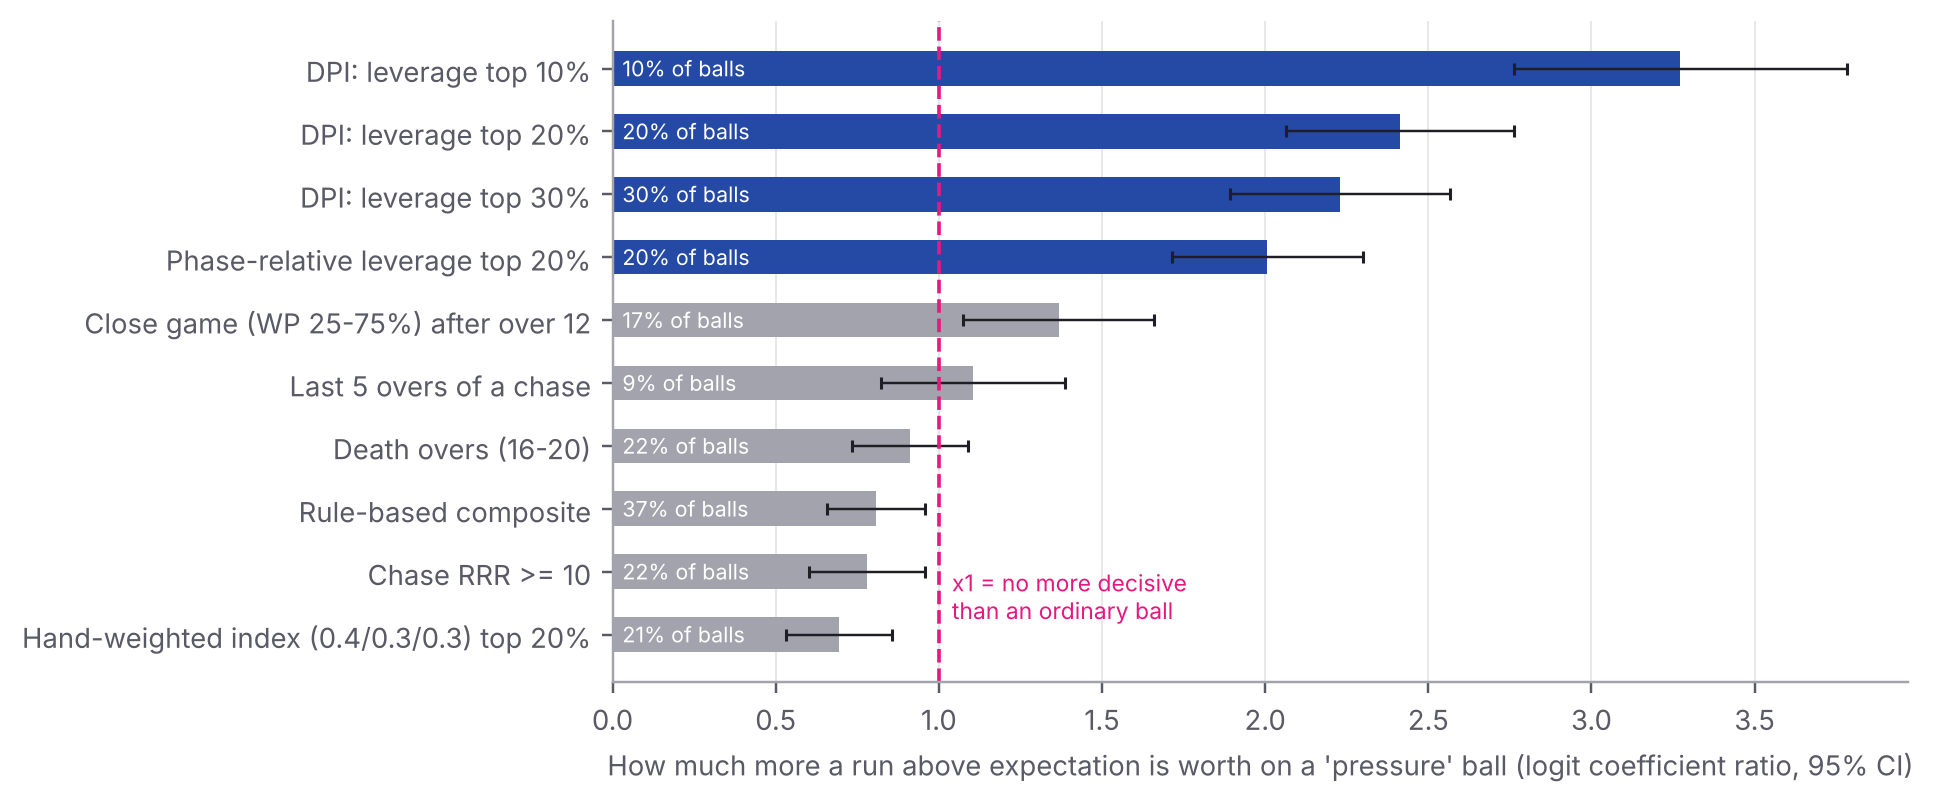

In [32]:
from IPython.display import Image
Image('figures/F02_pressure_definition_test.png', width=820)

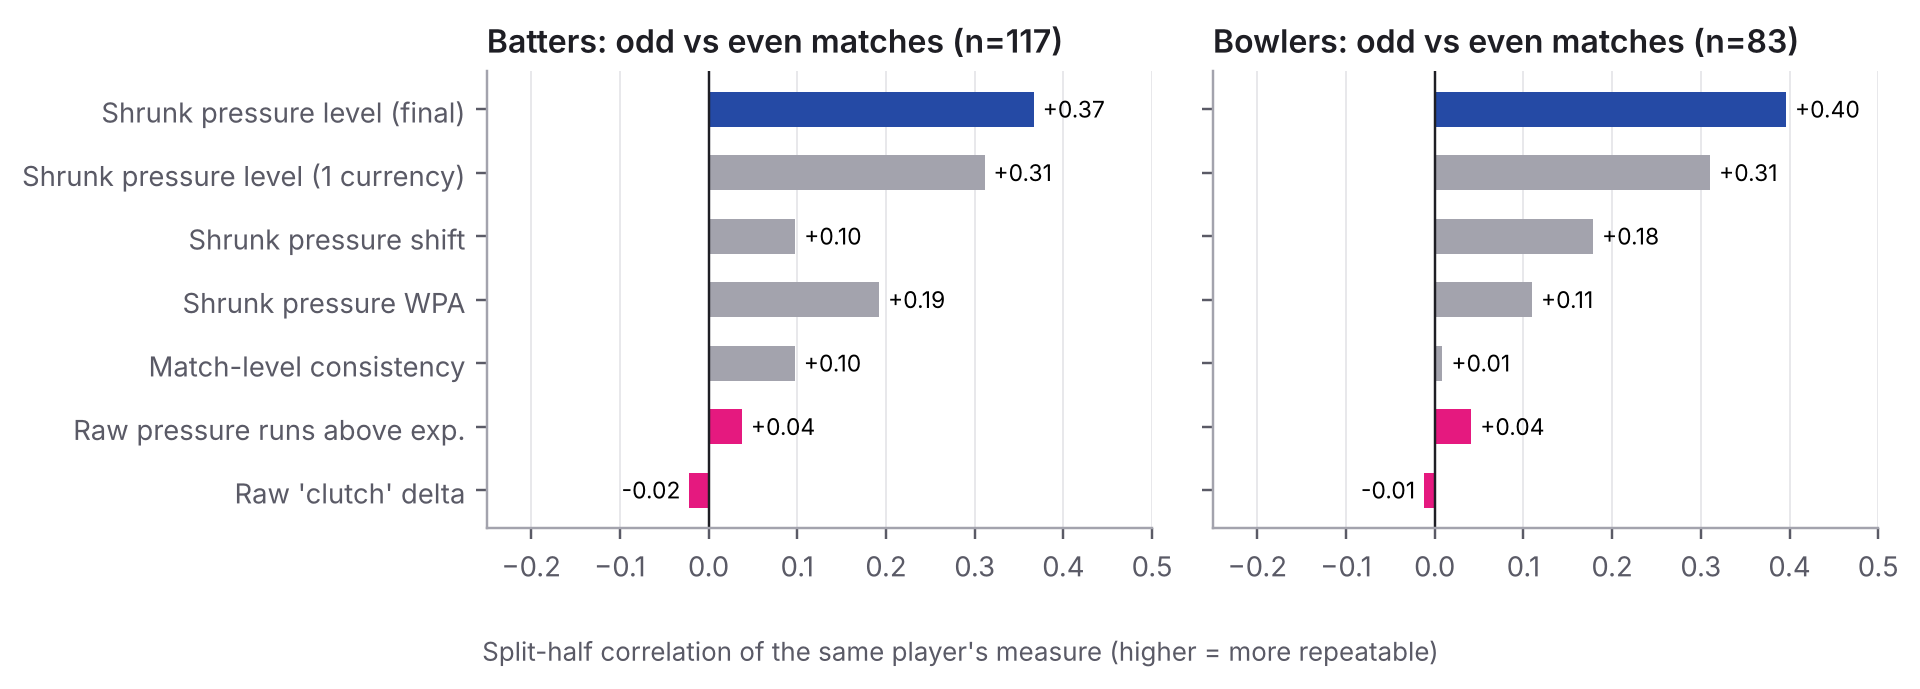

In [33]:
from IPython.display import Image
Image('figures/F05_repeatability.png', width=820)

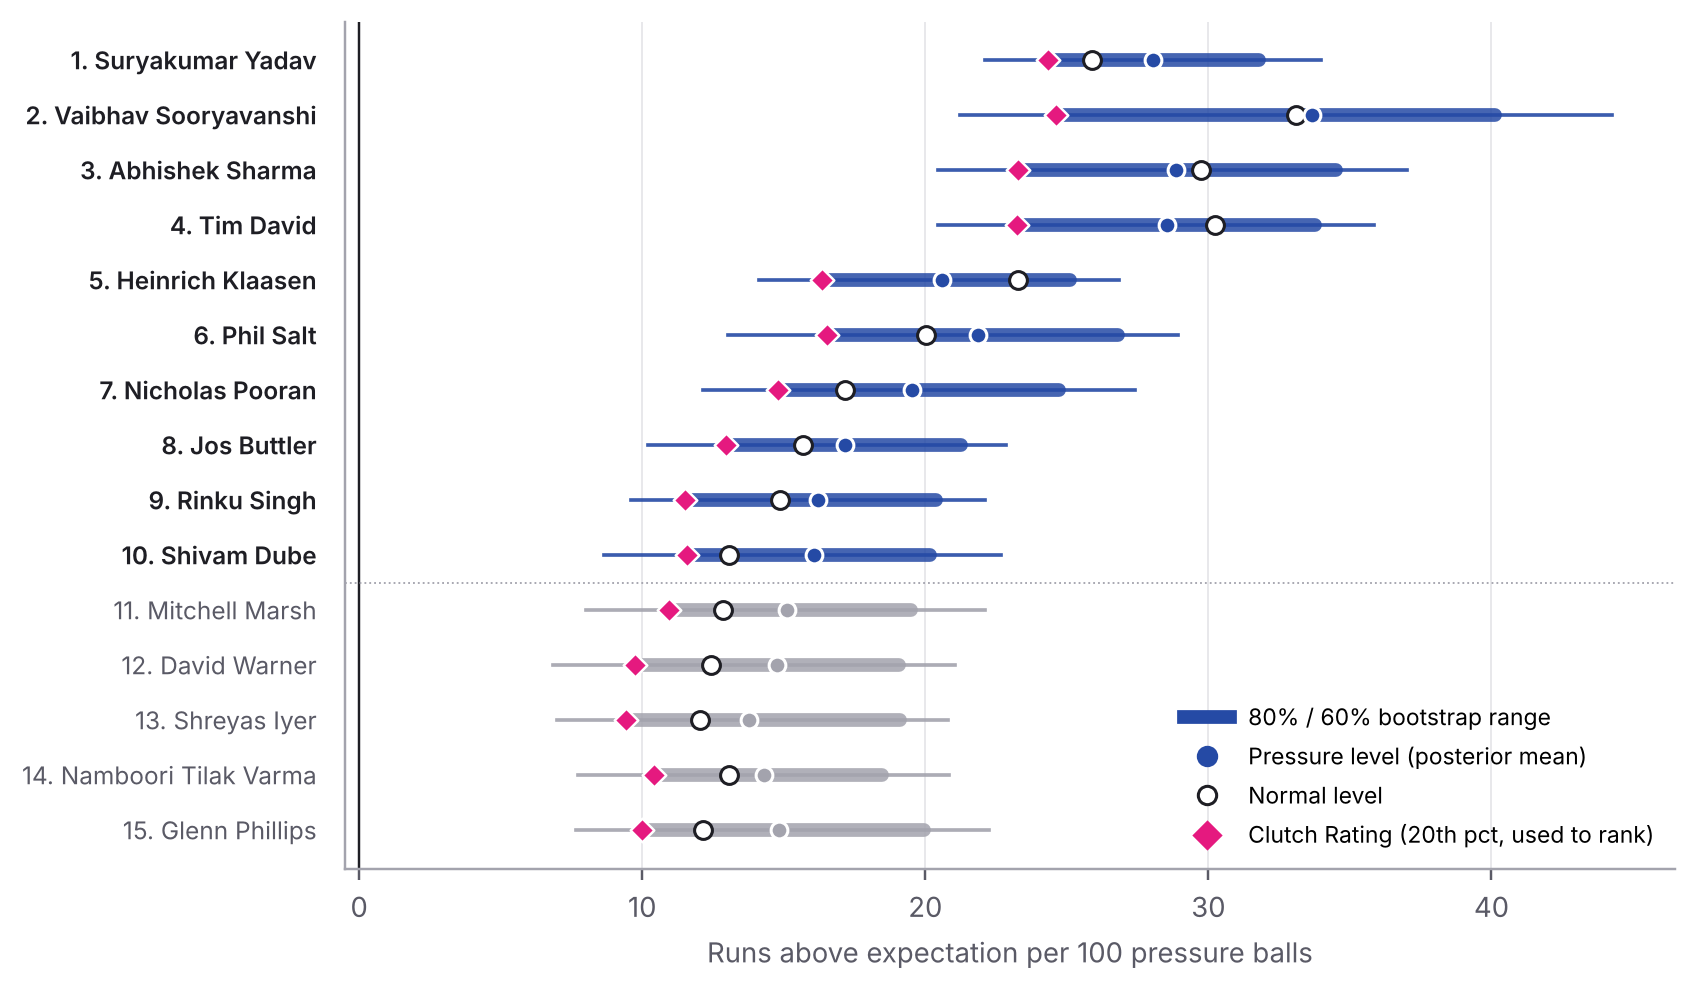

In [34]:
from IPython.display import Image
Image('figures/F07_forest_bat.png', width=820)

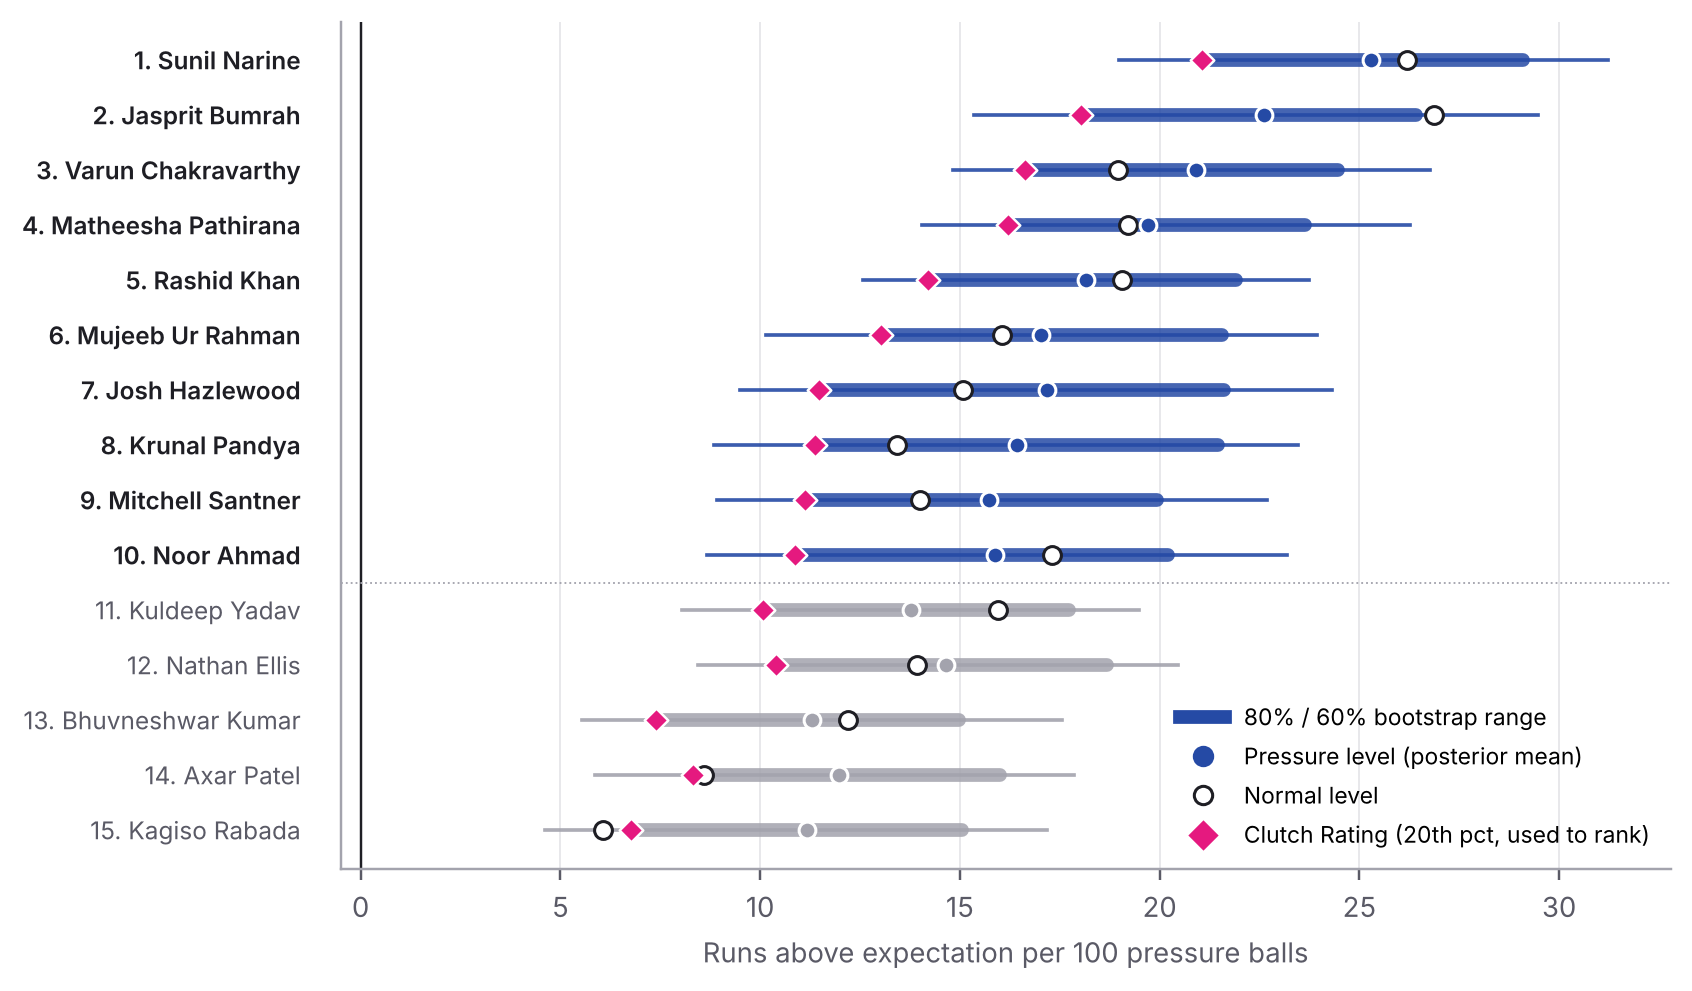

In [35]:
from IPython.display import Image
Image('figures/F07_forest_bowl.png', width=820)

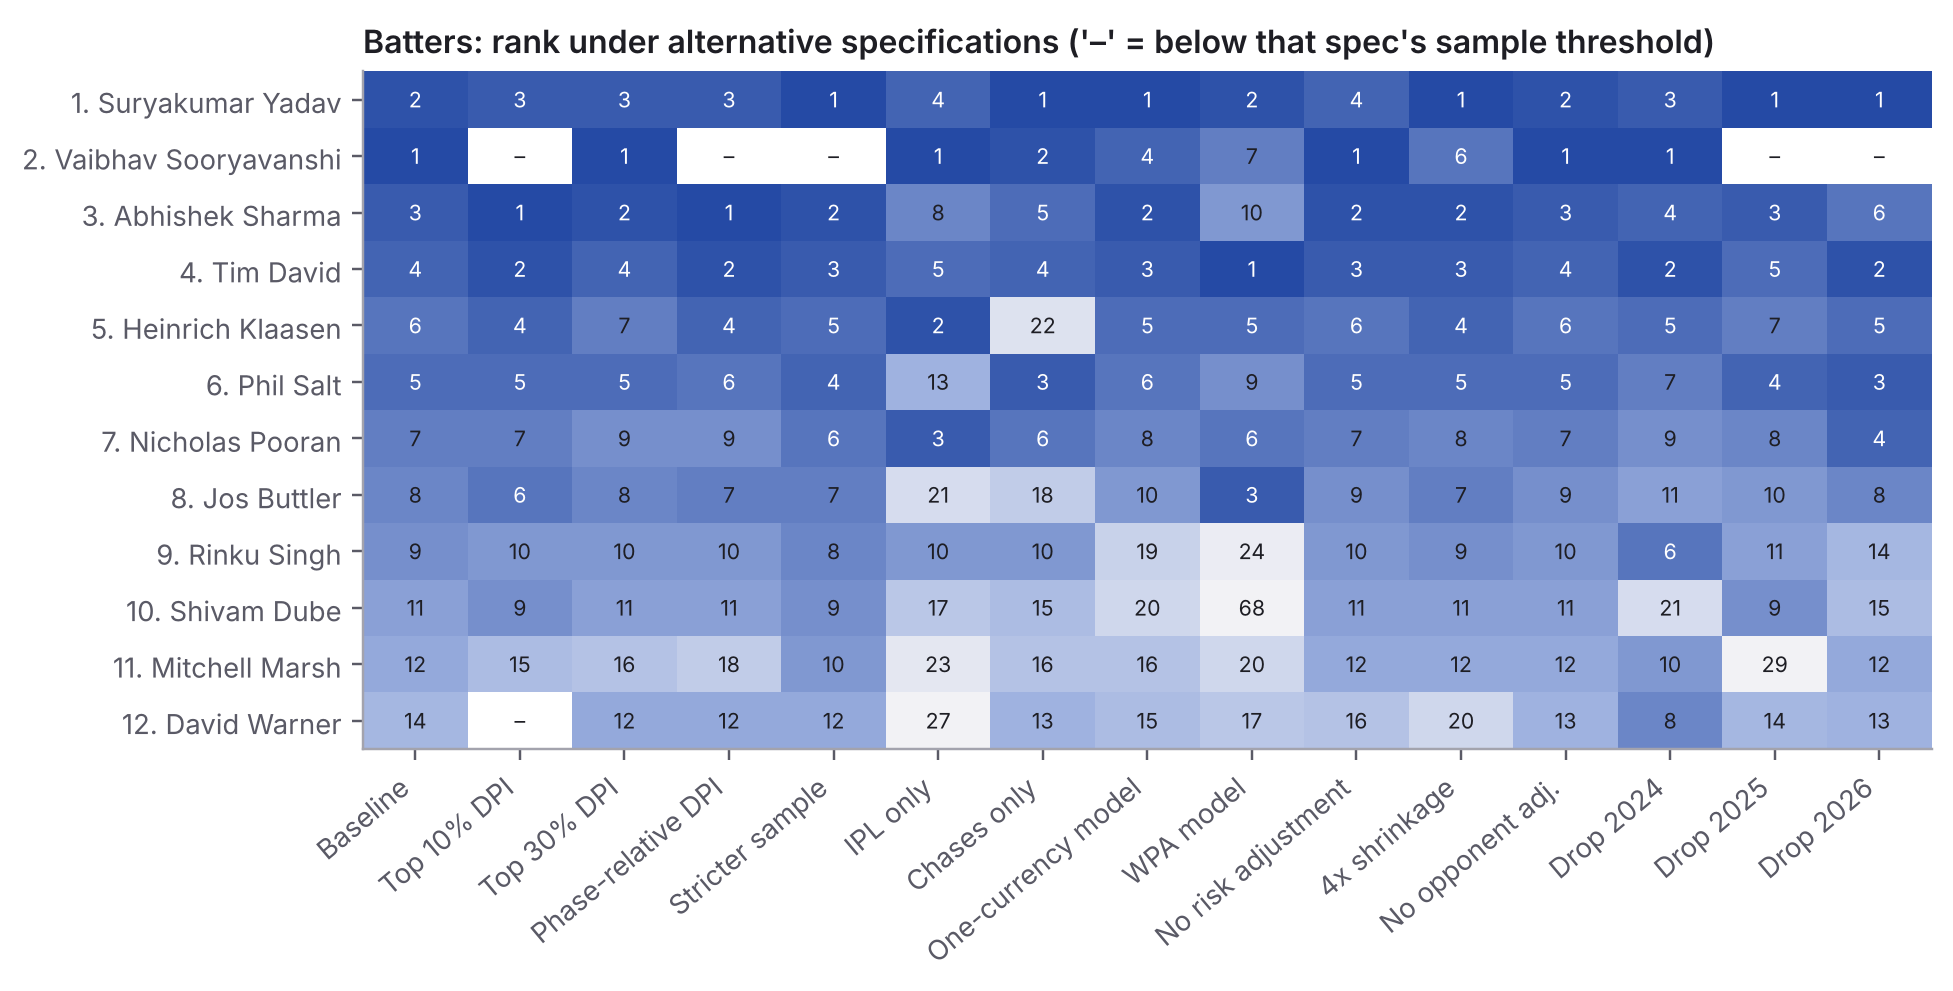

In [36]:
from IPython.display import Image
Image('figures/F09_rank_stability_bat.png', width=820)

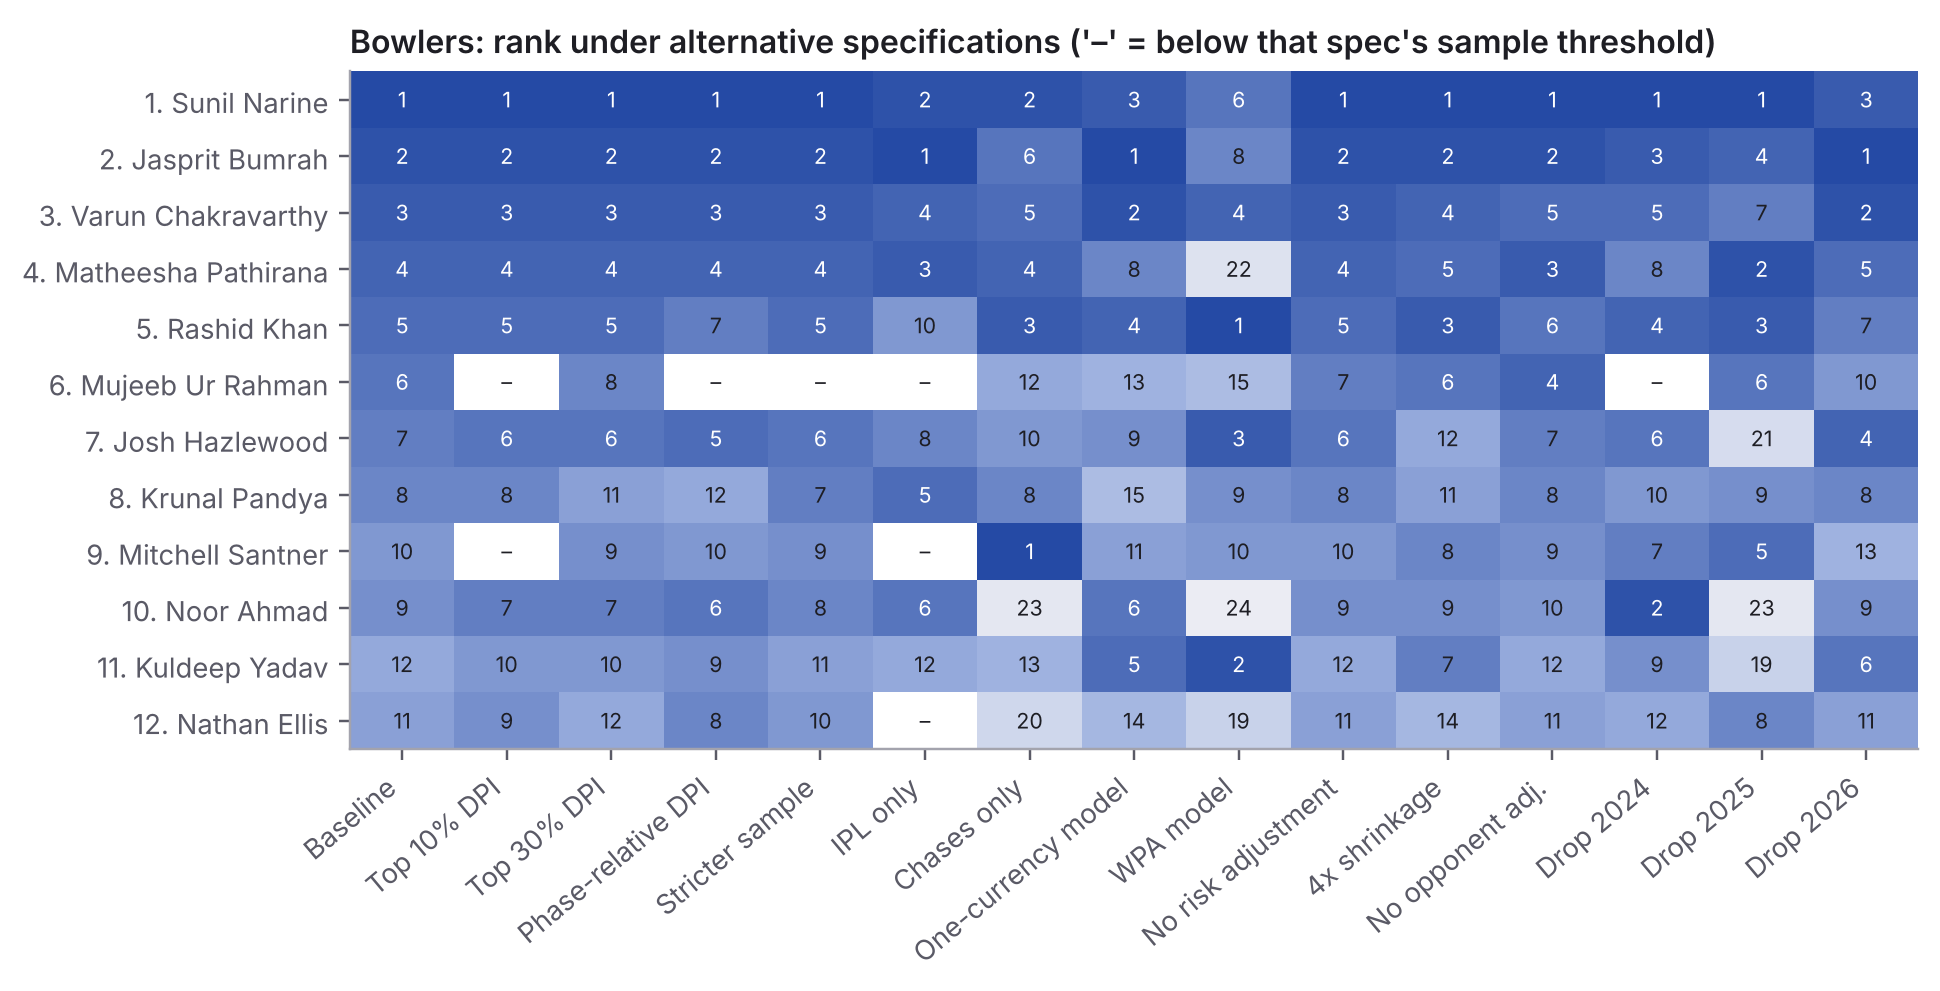

In [37]:
from IPython.display import Image
Image('figures/F09_rank_stability_bowl.png', width=820)

## Optional - rebuild the two PDF reports
Requires `playwright` and Google Chrome at `/usr/bin/google-chrome`.

In [38]:
# import build_report, build_validation
# build_report.main(); build_validation.main()